## setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

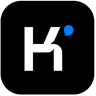

In [2]:
import sys
import copy
import json
import inspect
sys.path.append(r'src')
from tqdm.notebook import tqdm

import random
from datetime import date, datetime
from pathlib import Path
import pandas as pd
import os
import time
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output

from src.game_arena import base
from src.game_arena import utils
from src.game_arena import run_leaderboard

from experimental.exp_utils import model_name_map, get_logo, Image, get_main_elo_data, get_match_results, get_match_file_path, get_done_count, MODEL_NAME_MAP, MAIN_GAMES_WORLD_COLUMNS, NAME_DELETE, NAME_FIX_MAP
Image.fromarray(get_logo('kimi_k2.5'))

# leaderboard

In [48]:
gs = MAIN_GAMES_WORLD_COLUMNS
# gs = MAIN_GAMES_WORLD_COLUMNS + [('go', 'worldmem1', 'Go w/mem', None)]
# gs = MAIN_GAMES_WORLD_COLUMNS + [('go', 'worldmem1', 'Go w/mem', None)]
# gs = [
#     # ['go', 'world1', 'Go', None],
#     # ['go', 'worldmem1', 'Go Mem', 'matches_go_worldmem1_2211_1.json'],
# ]

In [53]:

# result_dir = 'results'
# result_dir = 'results_temp'
result_dir = 'results_current/results_somerset_feb_20/tourney'
# result_dir = 'results_feb_01'
# result_dir = 'results_memory'
main_elo_data = get_main_elo_data(gs, result_dir=result_dir)
elos = main_elo_data['elos']
elos_pre = main_elo_data['elos_pre']
colnames = main_elo_data['colnames']
raw_match_data = main_elo_data['raw_match_data']
pruned_match_data = main_elo_data['pruned_match_data']
done_count = main_elo_data['done_count']
top_bot_ids = main_elo_data['top_bot_ids']


tic_tac_toe_3d world1 46920
tic_tac_toe world1 46920
tic_tac_toe world2 46920
battleships world1 46920


KeyboardInterrupt: 

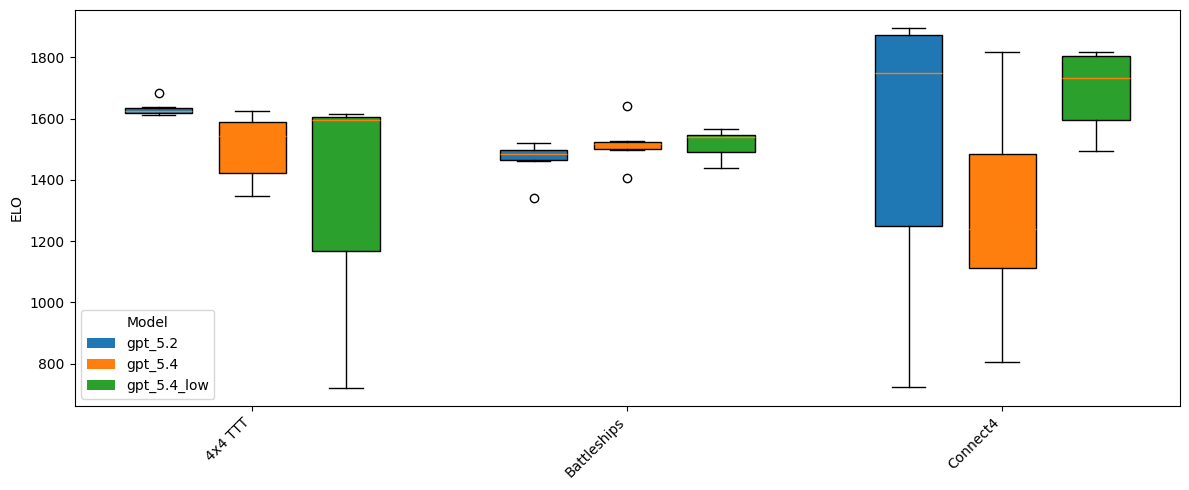

In [45]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

families = ["gpt_5.2", "gpt_5.4", "gpt_5.4_low"]
offsets = {"gpt_5.2": -0.25, "gpt_5.4": 0.0, "gpt_5.4_low": 0.25}
colors = {"gpt_5.2": "C0", "gpt_5.4": "C1", "gpt_5.4_low": "C2"}

fig, ax = plt.subplots(figsize=(12, 5))

for i, (_, elos) in enumerate(zip(colnames, elos_pre)):
    s = elos.squeeze()
    grouped = {fam: [] for fam in families}

    for model_name, elo in s.items():
        model_name = str(model_name).strip()
        if model_name.startswith("gpt_5.4_low"):
            grouped["gpt_5.4_low"].append(float(elo))
        elif model_name.startswith("gpt_5.4"):
            grouped["gpt_5.4"].append(float(elo))
        elif model_name.startswith("gpt_5.2"):
            grouped["gpt_5.2"].append(float(elo))

    for fam in families:
        if grouped[fam]:
            bp = ax.boxplot(
                grouped[fam],
                positions=[i + offsets[fam]],
                widths=0.18,
                patch_artist=True,
                manage_ticks=False,
            )
            for box in bp["boxes"]:
                box.set_facecolor(colors[fam])

ax.set_xticks(range(len(colnames)))
ax.set_xticklabels(colnames, rotation=45, ha="right")
ax.set_ylabel("ELO")
ax.legend(
    handles=[Patch(facecolor=colors[f], label=f) for f in families],
    title="Model"
)
plt.tight_layout()
plt.show()

In [28]:
elos

,ELO
gpt_5.2/002,2013.11
gpt_5.4_instant/002,1806.65
gpt_5.2/003,1793.74
gpt_5.4_instant/005,1725.37
gpt_5.2/006,1706.35
gpt_5.2/001,1700.25
gpt_5.4_instant/006,1662.82
gpt_5.4/004,1647.49
gpt_5.4/006,1606.29
gpt_5.2/004,1517.79


In [23]:
add_done_count = True

elos_df = pd.concat(elos, axis=1)
elos_df.columns = colnames
# elos_df = elos_df.drop(columns=['Chess']).rename(columns={'Chess UCI': 'Chess'})
_cols = elos_df.columns.tolist()
elos_df['Median ELO'] = elos_df.fillna(-9999).median(axis=1, skipna=False).round(1)
elos_df['Mean ELO'] = elos_df.fillna(0).mean(axis=1).round(1)
elos_df = elos_df[['Median ELO', 'Mean ELO'] + _cols]
elos_df = elos_df.sort_values('Median ELO', ascending=False)
# elos_df = elos_df.sort_values('Mean ELO', ascending=False)
# elos_df = elos_df.sort_values('Lines of Action ELO', ascending=False)
# elos_df = elos_df.sort_values('3D Tic Tac Toe ELO', ascending=False)
elos_with_rwins = elos_df.copy()
elos_with_rwins.to_csv(f'analysis/ranking_elos/elos_{datetime.now().strftime("%Y_%m_%d")}_with_{len(elos_df.columns)-2}_games_{len(elos_df)-2}_models.csv')
for game_str, _, _, colname in gs:
    if colname in elos_with_rwins.columns:
        elos_with_rwins[colname] = elos_with_rwins[colname].astype(str)
        for model in elos_with_rwins.index:
            elo = elos_df.at[model, colname]
            dc = done_count[colname].get(model, float('nan'))
            if pd.notnull(elo):
                elo_str = f"{int(round(elo))}"
            else:
                elo_str = 'nan'
            if (pd.isnull(dc) or dc == 0):
                dc_str = "*"
            else:
                dc_str = ""
            elos_with_rwins.at[model, colname] = f"{elo_str}"
            if add_done_count:
                 elos_with_rwins.at[model, colname] += f' {dc_str}'

with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(elos_with_rwins)

,Median ELO,Mean ELO,4x4 TTT,Battleships,Connect4
gpt_5.4_instant,1542.2,1602.1,1500.0,1542.2,1824.07
gpt_5.2,1500.0,1570.9,1500.0,1458.5,1825.00
gpt_5.4,1499.3,1337.4,1500.0,1499.3,850.93


In [53]:
print('WIN/LOSS/DRAW/ERROR/TIMEOUT breakdown for a game:')
colname = 'Go Mem'
elos_pre_df = pd.concat(elos_pre, axis=1)
elos_pre_df.columns = colnames
all_scores_df = run_leaderboard.get_scores_from_match_data(raw_match_data[colname])
all_scores_df['Total Rounds'] = all_scores_df.sum(axis=1)
df = pd.concat([elos_pre_df[colname].dropna().rename('ELO'), all_scores_df], axis=1).round().astype("Int64")
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(df.sort_values('ELO', ascending=False))


WIN/LOSS/DRAW/ERROR/TIMEOUT breakdown for a game:


,ELO,win,loss,draw,error,timeout,enemy_error,enemy_timeout,Total Rounds
mem:gpt_5.2/005,2079,40,11,1,0,0,39,41,132
nomem:gpt_5.2_codex/002,2034,23,14,0,1,0,30,64,132
mem:qwen3_coder_30b_a3b_instruct/003,2018,52,3,2,0,12,28,35,132
nomem:kimi_k2_thinking/005,1891,29,19,1,2,1,25,55,132
mem:gpt_5_mini/005,1885,24,13,4,2,6,28,55,132
mem:deepseek_v3.2_speciale/001,1874,47,21,3,0,0,38,23,132
nomem:gpt_5_mini/005,1839,26,29,0,2,2,31,42,132
mem:glm_4.7/002,1835,19,16,3,0,13,26,55,132
mem:minimax_m2/002,1795,41,33,2,3,3,13,37,132
nomem:gpt_5.2/005,1793,26,10,1,16,8,35,36,132


In [25]:
print('WIN/LOSS/DRAW/ERROR/TIMEOUT breakdown for a game:')
colname = 'Go'
# colname = 'GoSlow'
all_scores_df = run_leaderboard.get_scores_from_match_data(pruned_match_data[colname])
all_scores_df['Total'] = all_scores_df.sum(axis=1)
df = pd.concat([elos_df[colname].rename('ELO'), all_scores_df], axis=1).round().astype("Int64")
df['Timeout_Percent'] = (all_scores_df['timeout'] / all_scores_df['Total'] * 100).round(1).astype(str) + '%'
df.sort_values('ELO', ascending=False)

WIN/LOSS/DRAW/ERROR/TIMEOUT breakdown for a game:


,ELO,win,loss,draw,error,timeout,enemy_error,enemy_timeout,Total,Timeout_Percent
gpt_5.2_codex,2015,64,23,1,0,5,91,136,320,1.6%
gpt_5_mini,1915,62,43,0,1,2,90,122,320,0.6%
kimi_k2_thinking,1903,56,42,1,4,3,81,133,320,0.9%
gemini_3_pro_preview,1897,82,24,8,23,1,132,50,320,0.3%
glm_4.7,1764,61,16,1,38,29,101,74,320,9.1%
gpt_5.2,1763,72,15,1,35,32,107,58,320,10.0%
qwen3_32b,1709,75,41,0,16,39,71,78,320,12.2%
kimi_k2.5,1703,51,53,1,10,39,87,79,320,12.2%
kat_coder_pro,1691,100,23,1,27,56,66,47,320,17.5%
minimax_m2,1675,92,43,1,35,27,81,41,320,8.4%


In [26]:
print('Length of rounds THAT FINISHED:')
round_lens = {}
for col in pruned_match_data:
    round_lens[col] = [x['r']['move_count'] for x in pruned_match_data[col] if x['done']]

df = pd.DataFrame([(k, v) for k, vs in round_lens.items() for v in vs], columns=["key","move_count"])
stats = (df.groupby("key")["move_count"]
           .agg(n="size", mean="mean", std="std", min="min",
                p25=lambda s: s.quantile(.25),
                median="median",
                p75=lambda s: s.quantile(.75),
                max="max")
           .reset_index())
stats.sort_values('mean', ascending=False).reset_index(drop=True)


Length of rounds THAT FINISHED:


,key,n,mean,std,min,p25,median,p75,max
0,Go,1461,604.85,160.20,51,443.00,722.00,722.00,722
1,GoSlow,956,551.70,175.06,2,399.75,581.00,722.00,722
2,Battleships,5280,107.26,17.69,51,95.00,107.00,119.00,184
3,Backgammon,800,85.08,37.53,36,61.00,74.00,96.00,379
4,Breakthrough,4514,58.63,22.07,11,42.00,58.00,77.00,122
5,Checkers,2137,56.96,30.73,33,45.00,48.00,58.00,653
6,Hex,5025,44.01,33.93,21,22.00,22.00,65.00,121
7,Chess UCI,1931,40.72,31.47,7,17.00,34.00,52.00,267
8,Dots&B,3329,40.00,0.00,40,40.00,40.00,40.00,40
9,Havannah,4901,35.26,41.28,12,16.00,19.00,28.00,169


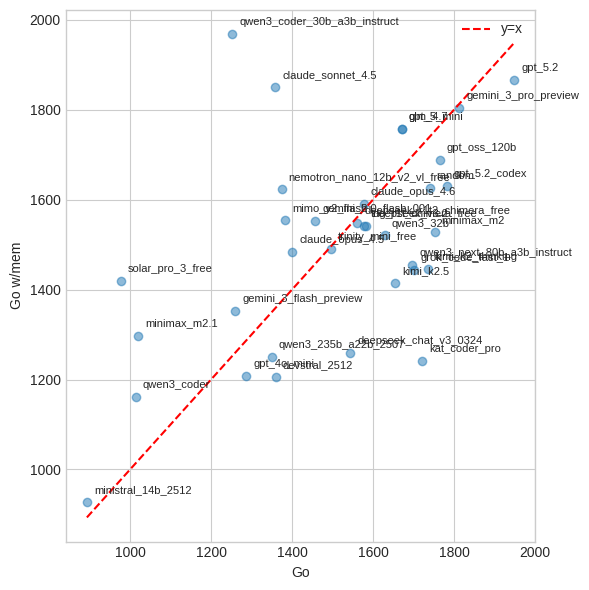

In [249]:
import matplotlib.pyplot as plt

game1 = "Go"
game2 = "Go w/mem"

tmp = elos_df[[game1, game2]].fillna(0)
x = tmp[game1]
y = tmp[game2]
plt.figure(figsize=(6, 6))
plt.scatter(x, y, alpha=0.5)
# y=x
plt.plot([x.min(), x.max()], [x.min(), x.max()], 'r--', label='y=x')
plt.legend()
for name, (xi, yi) in tmp.iterrows():
    plt.annotate(name, (xi, yi),textcoords="offset points", xytext=(5, 5),ha="left", va="bottom",fontsize=8)
plt.xlabel(game1)
plt.ylabel(game2)
plt.tight_layout()
plt.show()

In [10]:
# print qualified bots /id in a game (as in passed qualifier)
game_str = 'amazons'
world = 'world1'
all_data = get_match_results(get_match_file_path(game_str, world))
print('Qualified bots:')
n = sorted({x['name0'] for x in all_data} | {x['name1'] for x in all_data})
print(n)

Qualified bots:
['claude_opus_4.5/001', 'claude_opus_4.5/005', 'claude_sonnet_4.5/001', 'claude_sonnet_4.5/003', 'deepseek_chat_v3_0324/004', 'deepseek_chat_v3_0324/005', 'deepseek_r1t2_chimera_free/004', 'deepseek_r1t2_chimera_free/005', 'deepseek_v3.2/003', 'deepseek_v3.2/005', 'devstral_2512_free/001', 'devstral_2512_free/002', 'gemini_2.0_flash_001/001', 'gemini_2.0_flash_001/005', 'gemini_3_flash_preview/001', 'gemini_3_flash_preview/004', 'gemini_3_pro_preview/001', 'gemini_3_pro_preview/003', 'glm_4.7/002', 'glm_4.7/005', 'gpt_4o_mini/001', 'gpt_4o_mini/002', 'gpt_5.2/002', 'gpt_5.2/004', 'gpt_5.2_codex/002', 'gpt_5.2_codex/005', 'gpt_5.2_pro/001', 'gpt_5_mini/003', 'gpt_5_mini/005', 'gpt_oss_120b/004', 'gpt_oss_120b/005', 'grok_code_fast_1/001', 'grok_code_fast_1/002', 'kat_coder_pro/003', 'kat_coder_pro/004', 'kimi_k2.5/001', 'kimi_k2.5/003', 'kimi_k2_thinking/001', 'kimi_k2_thinking/003', 'mimo_v2_flash_free/001', 'mimo_v2_flash_free/005', 'minimax_m2.1/002', 'minimax_m2.1/00

In [162]:
print('Bot counts in true round robin tournament match results:')
def get_bot_counts(game_str, world, match_json):
    match_json = get_match_file_path(game_str, world, match_json, result_dir=result_dir)
    if match_json is None:
        return None
    all_data, pre_elim_matches = get_match_results(match_json, get_pre_elimination=True)
    all_names = set([m['name0'] for m in all_data] + [m['name1'] for m in all_data] + [m['name0'] for m in pre_elim_matches] + [m['name1'] for m in pre_elim_matches])
    return pd.Series(list(all_names)).str.split('/').str[0].value_counts()

bot_count_df = pd.DataFrame()
for game_str, world, column_name, match_json in gs:
    bot_count_single_df = get_bot_counts(game_str, world, match_json)
    if bot_count_single_df is None:
        continue
    bot_count_df[column_name] = bot_count_single_df
to_be_removed = set(bot_count_df.index) - set(elos_with_rwins.index)
print(f"Removing {len(to_be_removed)} bots: {to_be_removed}")
bot_count_df = bot_count_df[bot_count_df.index.isin(elos_with_rwins.index)]
bot_count_df[bot_count_df.isna()] = 0
bot_count_df = bot_count_df.astype(int)
bot_count_df['Total Bots'] = bot_count_df.sum(axis=1)
bot_count_df['Median ELO'] = elos_df['Median ELO']
bot_count_df = bot_count_df.sort_values('Median ELO', ascending=False)
# bot_count_df = bot_count_df.sort_values('Total Bots', ascending=False)
print('total bots =', bot_count_df['Total Bots'].sum())
print('Bot Counts:')
cols_to_exclude = ['Total Bots', 'Median ELO']
mask_cols = [c for c in bot_count_df.columns if c not in cols_to_exclude]

mask_lt = bot_count_df[mask_cols] < 2
mask_gt = bot_count_df[mask_cols] > 2
bot_count_df = bot_count_df.astype(str)
bot_count_df.loc[:, mask_cols] = bot_count_df.loc[:, mask_cols].mask(mask_lt, bot_count_df.loc[:, mask_cols] + ' (🟥)')
bot_count_df.loc[:, mask_cols] = bot_count_df.loc[:, mask_cols].mask(mask_gt, bot_count_df.loc[:, mask_cols] + ' (🟢)')
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    # bot_count_df[bot_count_df < 3] = -9990
    display(bot_count_df)

Bot counts in true round robin tournament match results:
ERROR========================== battleships world1
ERROR battleships world1: No matches found for battleships world1
ERROR========================== checkers world1
ERROR checkers world1: No matches found for checkers world1
Removing 0 bots: set()
total bots = 1206
Bot Counts:


,3D TTT,3x3 TTT,4x4 TTT,Connect4,LoA,Mancala,Clobber,Pentago,Amazons,Backgammon,Nim,Othello,Dots&B,Breakthrough,Hex,Havannah,Go,Chess UCI,Total Bots,Median ELO
gemini_3_pro_preview,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,36,2020.2
gpt_5.2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,36,1961.3
claude_opus_4.6,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,36,1907.0
kimi_k2.5,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,36,1802.0
kimi_k2_thinking,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,36,1773.1
gpt_5.2_codex,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,36,1752.7
gemini_3_flash_preview,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,36,1738.2
gpt_5_mini,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,36,1729.9
glm_4.7,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,36,1693.3
claude_opus_4.5,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,36,1664.2


In [55]:
print('Bot counts inside repo:')
clip_to_num = True
num = 6

all_bots_in_repo = {}
for game_str, world, column_name, match_json in gs:
    game = utils.get_game(game_name=game_str)
    ex = utils.get_examples_dir(game_str) / world
    config_path = json.loads((ex / 'config.json').read_text()) if (ex / 'config.json').exists() else {}
    random_policy = utils.get_the_random_policy()
    input_policy = lambda **kwargs: input('POLICY INPUT:')
    bots = list(utils.get_bot_jsons(ex).items()) if ex.exists() else []
    counts = {}
    for b, _ in bots:
        b = b.split('/')[0]
        if b in NAME_DELETE:
            continue
        counts[b] = counts.get(b, 0) + 1
    all_bots_in_repo[column_name] = counts
repo_bots_df = pd.DataFrame(all_bots_in_repo)
if clip_to_num:
    repo_bots_df = repo_bots_df.clip(upper=num)
mask_lt = (repo_bots_df < num)
mask_gt = repo_bots_df > num
repo_bots_df['total_bots'] = repo_bots_df.sum(axis=1)
repo_bots_df['nan_count'] = repo_bots_df.isna().sum(axis=1)
try:
    repo_bots_df['Median ELO'] = elos_df['Median ELO'].round()
except:
    repo_bots_df['Median ELO'] = pd.NA
mark_cols = repo_bots_df.columns.drop(['total_bots', 'nan_count', 'Median ELO'])
repo_bots_df = repo_bots_df.astype('Int64')
repo_bots_df[mark_cols] = repo_bots_df[mark_cols].astype(str)
repo_bots_df[mark_cols] = repo_bots_df[mark_cols].mask(mask_lt, repo_bots_df[mark_cols] + ' (🟥)')
repo_bots_df[mark_cols] = repo_bots_df[mark_cols].mask(mask_gt, repo_bots_df[mark_cols] + ' (🟢)')
repo_bots_df[mark_cols] = repo_bots_df[mark_cols].fillna('NaN (🟥)')
repo_bots_df.sort_values(by=['total_bots', 'Median ELO'], ascending=[True, False], inplace=True)
repo_bots_df.insert(0, "Model#", range(1, len(repo_bots_df) + 1))
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(repo_bots_df)
# repo_bots_df

Bot counts inside repo:


,Model#,3D TTT,3x3 TTT,4x4 TTT,Battleships,Connect4,LoA,Mancala,Clobber,Pentago,Amazons,Backgammon,Nim,Othello,Dots&B,Breakthrough,Hex,Havannah,Go,Checkers,Chess UCI,total_bots,nan_count,Median ELO
deepseek_r1t2_chimera_free,1,5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),100,0,<NA>
tng_r1t_chimera_free,2,5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),5 (🟥),100,0,<NA>
gpt_5.4_instant,3,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,120,0,1542
gpt_5.2,4,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,120,0,1500
gpt_5.4,5,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,120,0,1499
qwen3_coder,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,120,0,<NA>
kat_coder_pro,7,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,120,0,<NA>
glm_5,8,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,120,0,<NA>
grok_code_fast_1,9,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,120,0,<NA>
claude_opus_4.6,10,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,6,120,0,<NA>


In [164]:
# top bot id per model/game
top_bot_ids_df = pd.DataFrame(top_bot_ids)
top_bot_ids_df['Median ELO'] = elos_df['Median ELO']
top_bot_ids_df = top_bot_ids_df.sort_values('Median ELO', ascending=False)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(top_bot_ids_df)



,3D TTT,3x3 TTT,4x4 TTT,Connect4,LoA,Mancala,Clobber,Pentago,Amazons,Backgammon,Nim,Othello,Dots&B,Breakthrough,Hex,Havannah,Go,Chess UCI,Median ELO
gemini_3_pro_preview,001,002,002,003,005,002,002,001,001,005,002,005,001,002,003,001,001,005,2020.20
gpt_5.2,001,002,002,002,002,001,004,005,005,001,001,005,005,003,003,005,002,002,1961.30
claude_opus_4.6,001,001,004,003,002,001,001,002,001,001,002,003,002,003,003,005,001,005,1907.00
kimi_k2.5,001,002,002,004,004,002,001,002,001,001,001,003,002,001,002,003,005,002,1802.00
kimi_k2_thinking,002,002,002,001,004,003,005,004,001,006,003,005,005,002,001,001,005,004,1773.10
gpt_5.2_codex,001,001,002,002,003,002,005,003,002,006,001,005,002,001,001,001,002,004,1752.70
gemini_3_flash_preview,001,001,001,001,001,004,002,003,001,003,003,005,004,002,004,001,001,005,1738.20
gpt_5_mini,002,001,003,003,005,003,005,003,005,004,005,001,002,003,002,002,005,003,1729.90
glm_4.7,002,002,002,003,004,001,001,002,005,005,001,001,002,002,002,004,004,005,1693.30
claude_opus_4.5,002,001,004,004,005,004,004,005,005,004,001,001,002,002,002,004,001,002,1664.20


In [ ]:
# for frontend
elos_all_bots = {}
elos_combined_bots = []
strategies = {}
dnq_bots = {}
dnq_models = {}
col_names = []

gs = [
    ['tic_tac_toe_3d', 'world1', None, '3D TTT'],
    ['tic_tac_toe', 'world1', None, '3x3 TTT'],
    ['tic_tac_toe', 'world2', None, '4x4 TTT'],
    # ['blackjack', 'world1', None, 'Blackjack'],
    ['battleships', 'world1', None, 'Battleships'],
    ['connect4', 'world1', None, 'Connect4'],
    ['lines_of_action', 'world1', None, 'LoA'],
    ['mancala', 'world1', None, 'Mancala'],
    ['clobber', 'world1', None, 'Clobber'],
    ['pentago', 'world1', None, 'Pentago'],
    ['othello', 'world1', None, 'Othello'],
    ['amazons', 'world1', None, 'Amazons'],
    ['backgammon', 'world1', None, 'Backgammon'],
    ['nim', 'world1', None, 'Nim'],
    ['dots_and_boxes', 'world1', None, 'Dots&B'],
    # ['chess', 'world1', None, 'Chess'],
    ['breakthrough', 'world1', None, 'Breakthrough'],
    ['hex', 'world1', None, 'Hex'],
    ['havannah', 'world1', None, 'Havannah'],
    ['go', 'world1', None, 'Go'],
    ['checkers', 'world1', None, 'Checkers'],
    ['chess', 'worlduci1', None, 'Chess UCI'],
]


# results_dir = 'results_jan_24'
results_dir = 'results'
for game_str, world, match_json, colname in gs:
    print(f'{game_str} {world} {match_json} {colname}')
    match_json = get_match_file_path(game_str, world, match_json, result_dir=result_dir)
    if match_json is None:
        continue
    with open(match_json, 'r') as f:
        match_file = json.load(f)
    all_data_pruned = match_file['match_results']
    all_data_pruned = [g for g in all_data_pruned if 'OLD_' not in g['name0'] and 'OLD_' not in g['name1']]
    all_data_pruned = [g for g in all_data_pruned if g['name0'].split('/')[0] not in NAME_DELETE and g['name1'].split('/')[0] not in NAME_DELETE]
    for g in all_data_pruned:
        if '/' in g['name0']:
            model_name, bot_num = g['name0'].split('/', 1)
            g['name0'] = NAME_FIX_MAP.get(model_name, model_name) + f'/{bot_num}'
        if '/' in g['name1']:
            model_name, bot_num = g['name1'].split('/', 1)
            g['name1'] = NAME_FIX_MAP.get(model_name, model_name) + f'/{bot_num}'

    # ALL BOTS CSV
    elo_pre, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='top_1', verbose=False, learning_rate=4, iters=500)
    elos_all_bots[colname] = elo_pre
    if match_file['pre_elimination_results']:
        pre_elim_matches = match_file['pre_elimination_results']['match_results']
        done_matches = [m for m in pre_elim_matches if m['done']]
        not_done_matches = [m for m in pre_elim_matches if not m['done']]
        done_bots = (set([m['name0'] for m in done_matches]) | set([m['name1'] for m in done_matches]))
        not_done_bots = (set([m['name0'] for m in not_done_matches]) | set([m['name1'] for m in not_done_matches])) - done_bots
        dnq_bots[colname] = not_done_bots
        done_models = set([m['name0'].split('/')[0] for m in done_matches] + [m['name1'].split('/')[0] for m in done_matches])
        not_done_models = set([m['name0'].split('/')[0] for m in not_done_matches] + [m['name1'].split('/')[0] for m in not_done_matches]) - done_models
        dnq_models[colname] = not_done_models

    # TOP 1 CSV
    top_models_names = set(top_models)
    all_data_pruned = [g for g in all_data_pruned if g['name0'] in top_models_names and g['name1'] in top_models_names]
    for g in all_data_pruned:
        g['name0'] = g['name0'].split('/')[0]
        g['name1'] = g['name1'].split('/')[0]
    elo_post, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='none', verbose=False, learning_rate=4, iters=500)
    elos_combined_bots.append(elo_post)
    col_names.append(colname)

    # # STRATEGY JSON
    # strategies[colname] = {}
    # for model_dir in Path(f'src/game_arena/{game_str}/examples/{world}/').iterdir():
    #     if not model_dir.is_dir() or model_dir.name in ['trash_free', 'trash']:
    #         continue
    #     for bot_dir in model_dir.iterdir():
    #         if not bot_dir.is_dir():
    #             continue
    #         # if '_old_prompt/' in b or 'kat_coder_pro_free/' in b or 'kat_code_pro_free/' in b:
    #         #     continue
    #         if not (bot_dir / '1.output.txt').exists():
    #             print(f'{bot_dir} does not have 1.output.txt')
    #             continue
    #         full_output = (bot_dir / '1.output.txt').read_text()
    #         if '```python' in full_output or '<code>' in full_output:
    #             pre_code = full_output.split('```python')[0].split('<code>')[0] 
    #         else:
    #             pre_code = ''
    #         if (bot_dir / '2.python_code.py').exists():
    #             with open(bot_dir / '2.python_code.py', 'r') as f:
    #                 code = f.read()
    #         else:
    #             code = ''
    #         model_with_bot = bot_dir.parent.name + '/' + bot_dir.name
    #         strategies[colname][model_with_bot] = {
    #             'pre_code': pre_code,
    #             'full_output': full_output,
    #             'code': code,
    #             'elo': elo_pre.at[model_with_bot, 'ELO'].item() if model_with_bot in elo_pre.index else None,
    #         }
    # # if len(elos_all_bots) > 1:
    # #     break

for asdf in range(len(elos_combined_bots)):
    elos_combined_bots[asdf] = elos_combined_bots[asdf].astype(float)
df = pd.concat(elos_combined_bots, axis=1)
df.columns = col_names
for col in dnq_models:
    for bot in dnq_models[col]:
        if bot not in df.index:
            continue
        if not pd.isna(df.at[bot, col]):
            print(f"{bot} {col} is not DNQ = {df.at[bot, col]}")
            continue
        df[col] = df[col].astype(str)
        df.at[bot, col] = "DNQ"
df.to_csv('src/frontend/arena_fe/public/elos_combined_bots.csv')


kv = elos_all_bots.items()
df = pd.concat([v for _,v in kv], axis=1)
df.columns = [k for k,v in kv]
for col in dnq_bots:
    for bot in dnq_bots[col]:
        if bot not in df.index:
            continue
        if not pd.isna(df.at[bot, col]):
            print(f"{bot} {col} is not DNQ = {df.at[bot, col]}")
            continue
        df[col] = df[col].astype(str)
        df.at[bot, col] = "DNQ"
df.to_csv('src/frontend/arena_fe/public/elos_all_bots.csv')

# import json
# with open('src/frontend/arena_fe/public/strategies.json', 'w') as f:
#     json.dump(strategies, f, indent=2)


tic_tac_toe_3d world1 None 3D TTT
tic_tac_toe world1 None 3x3 TTT
tic_tac_toe world2 None 4x4 TTT
battleships world1 None Battleships
ERROR========================== battleships world1
ERROR battleships world1: No matches found for battleships world1
connect4 world1 None Connect4
lines_of_action world1 None LoA
mancala world1 None Mancala
clobber world1 None Clobber
pentago world1 None Pentago
othello world1 None Othello
amazons world1 None Amazons
backgammon world1 None Backgammon
nim world1 None Nim
dots_and_boxes world1 None Dots&B
breakthrough world1 None Breakthrough
hex world1 None Hex
havannah world1 None Havannah
go world1 None Go
checkers world1 None Checkers
ERROR========================== checkers world1
ERROR checkers world1: No matches found for checkers world1
chess worlduci1 None Chess UCI


## Figures

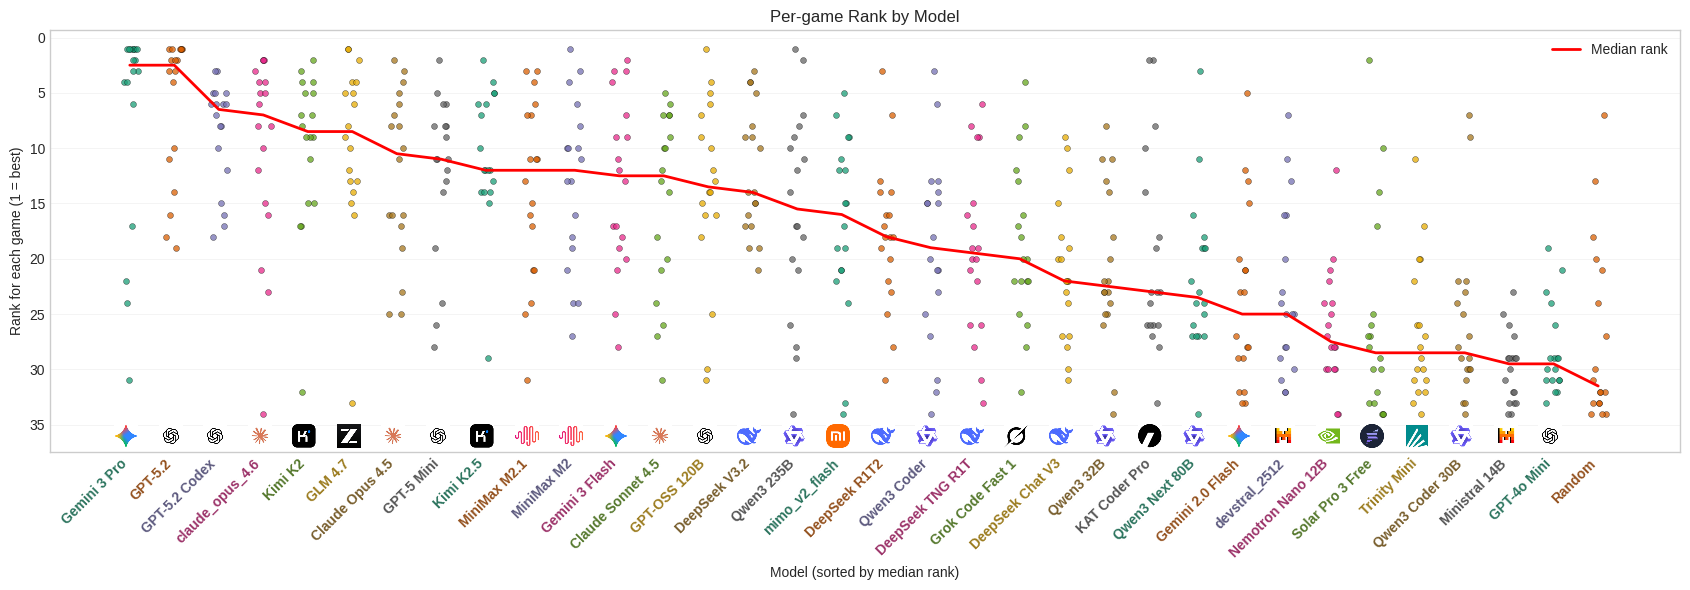

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

# 1) Per-game ranks (1 = best / highest ELO)
rank_df = elos_df.rank(axis=0, ascending=False, method="min")

# 2) Sort models by median rank (lower median = better)
med = rank_df.median(axis=1, skipna=True)
order = med.sort_values(ascending=True).index

# 3) Scatter (strip) plot with jitter + median trend line + legend
models = order.astype(str).tolist()
x = np.arange(len(models))

jitter = 0.18
alpha = 0.75
size = 18

plt.style.use("seaborn-v0_8-whitegrid")
plt.figure(figsize=(max(10, 0.5 * len(models)), 6))
ax = plt.gca()

ax.grid(axis="y", which="major", linestyle="-", linewidth=0.6, alpha=0.25)
ax.grid(axis="x", visible=False)

cmap = plt.get_cmap("Dark2")
colors = [cmap(i % cmap.N) for i in range(len(models))]

for asdf, m in enumerate(order):
    y = rank_df.loc[m].dropna().to_numpy()
    xj = asdf + np.random.uniform(-jitter, jitter, size=len(y))
    ax.scatter(xj, y,s=size,alpha=alpha,color=colors[asdf],edgecolors="black",linewidths=0.3,zorder=2,
    )

median_y = med.loc[order].to_numpy()
median_line, = ax.plot(x, median_y, linestyle="-", linewidth=2.0, color="red", zorder=3)

ax.set_xticks(x)
ax.set_xticklabels([model_name_map(m) for m in models], rotation=45, ha="right")

logo_zoom = 0.18
x_offset = -10  # px left of label
y_offset = 0

for asdf, m in enumerate(models):
    if m == 'random':
        continue
    arr = get_logo(m)
    ax.add_artist(AnnotationBbox(OffsetImage(arr, zoom=logo_zoom),(asdf+0.5, 0.01),xycoords=("data", "axes fraction"),xybox=(x_offset, y_offset),boxcoords="offset points",frameon=False,box_alignment=(1.0, 0.0),pad=0.0,zorder=4,clip_on=False,))

plt.subplots_adjust(bottom=0.30)

ax.set_xlabel("Model (sorted by median rank)")
ax.set_ylabel("Rank for each game (1 = best)")
ax.set_title("Per-game Rank by Model")
ymin, ymax = ax.get_ylim()          # (bottom, top) before invert
pad = 1.8                           # tweak: ~0.5–1.5 works well
ax.set_ylim(ymin, ymax + pad)       # after invert this becomes extra space at the top

ax.invert_yaxis()

text_blend = 0.45
grey = np.array([0.25, 0.25, 0.25, 1.0])
for tick, c in zip(ax.get_xticklabels(), colors):
    rgba = np.array(c)
    muted = (1 - text_blend) * rgba + text_blend * grey
    tick.set_color(muted)
    tick.set_fontweight("semibold")

ax.legend([median_line], ["Median rank"], frameon=False, loc="upper right")

plt.tight_layout()
plt.savefig("figures/boxplot_per_game_rank.svg", format="svg", bbox_inches="tight")
plt.show()


In [56]:
import pandas as pd

df = (pd.DataFrame([(v, k) for k, v in MODEL_NAME_MAP.items()],
                   columns=["Short model name", "Full model name"])
        .sort_values(["Short model name", "Full model name"], kind="stable"))

print(df.to_latex(index=False, escape=True, column_format="ll"))


\begin{tabular}{ll}
\toprule
Short model name & Full model name \\
\midrule
Claude Opus 4.5 & claude\_opus\_4.5 \\
Claude Opus 4.6 & claude\_opus\_4.6 \\
Claude Sonnet 4.5 & claude\_sonnet\_4.5 \\
DeepSeek Chat V3 & deepseek\_chat\_v3\_0324 \\
DeepSeek R1T2 & deepseek\_r1t2\_chimera\_free \\
DeepSeek TNG R1T & tng\_r1t\_chimera\_free \\
DeepSeek V3.2 & deepseek\_v3.2 \\
Devstral & devstral\_2512 \\
Devstral & devstral\_2512\_free \\
GLM 4.7 & glm\_4.7 \\
GLM 5 & glm\_5 \\
GPT-4o Mini & gpt\_4o\_mini \\
GPT-5 Mini & gpt\_5\_mini \\
GPT-5.2 & gpt\_5.2 \\
GPT-5.2 Codex & gpt\_5.2\_codex \\
GPT-5.4 & gpt\_5.4 \\
GPT-5.4 Instant & gpt\_5.4\_instant \\
GPT-5.4 Low & gpt\_5.4\_low \\
GPT-5.4 Medium & gpt\_5.4\_medium \\
GPT-OSS 120B & gpt\_oss\_120b \\
Gemini 2.0 Flash & gemini\_2.0\_flash\_001 \\
Gemini 3 Flash & gemini\_3\_flash\_preview \\
Gemini 3 Pro & gemini\_3\_pro\_preview \\
Grok Code Fast 1 & grok\_code\_fast\_1 \\
KAT Coder Pro & kat\_coder\_pro \\
Kimi K2 & kimi\_k2\_thinking \\
K

In [34]:
# APPENDIX FULL ELO TABLE
df = elos_with_rwins.copy()
# no mean elo
df = df.drop(columns=['Mean ELO'])
# rename Random to Random Legal Move
df = df.rename(index={'random': 'Random Legal Move'})
df.index = (
    df.index
      .str.replace('_', ' ', regex=False)
      .str.title()
      .str.replace(' Free', '', regex=False)
)

df = df.round(1)

latex_str = df.to_latex(
    float_format="%.1f",
    index=True,
    escape=True,
    column_format="l" + "r" * df.shape[1]
)
# latex_str = '''
# \\begin{table*}[t]
# \\centering
# \\scriptsize
# \\setlength{\\tabcolsep}{2.5pt}
# \\renewcommand{\\arraystretch}{0.9}
# \\resizebox{\\textwidth}{!}{%
# ''' + \
#     latex_str
# '''}
# \\caption{...}
# \\label{tab:...}
# \\end{table*}
# '''
print(latex_str)


\begin{tabular}{lrrrrrrrrrrrrrrrrrrrrr}
\toprule
 & Median ELO & 3D TTT & 3x3 TTT & 4x4 TTT & Blackjack & Battleships & Connect4 & LoA & Mancala & Clobber & Pentago & Amazons & Backgammon & Nim & Dots\&B & Breakthrough & Hex & Havannah & Go & Checkers & Chess UCI \\
\midrule
Gpt 5.2 & 1792.7 & 1573.2 & 1515.0 & 1520.0 & 1495.0 & 1692.9 & 1979.0 & 1909.2 & 1772.8 & 1979.0 & 1679.6 & 1852.6 & 1892.5 & 1749.5 & 1977.4 & 1443.4 & 1899.2 & 1929.1 & 1673.0 & 1812.7 & 1890.9 \\
Gemini 3 Pro Preview & 1756.1 & 1566.5 & 1515.0 & 1513.3 & 1526.6 & 1749.5 & 1724.5 & 2004.0 & 1777.8 & 1849.3 & 1659.7 & 1955.7 & 1905.8 & 1749.5 & 1812.7 & 1979.0 & 1992.3 & 1400.2 & 1937.4 & 1762.8 & 1746.2 \\
Kimi K2.5 & 1738.7 & 1566.5 & 1525.0 & 1521.6 & 1541.6 & 1683.0 & 1816.0 & 1599.8 & 1779.4 & 1829.3 & 1563.2 & 1832.7 & 1759.5 & 1749.5 & 1731.2 & 1832.7 & 1782.8 & 1371.9 & 1837.6 & 1357.0 & 1746.2 \\
Gpt 5.2 Codex & 1670.5 & 1566.5 & 1523.3 & 1525.0 & 1513.3 & 1716.2 & 1707.9 & 1571.5 & 1799.4 & 1663.0 & 166

In [38]:
# APPENDIX FULL ELO TABLE
df = elos_with_rwins.copy()
# no mean elo
df = df.drop(columns=['Mean ELO', '3x3 TTT', '4x4 TTT', 'Blackjack', 'Battleships', 'Nim'])
# rename Random to Random Legal Move
df = df.rename(index={'random': 'Random Legal Move'}, columns={'Chess UCI': 'Chess'})
_cols = df.columns.tolist()
_last_cols = ['Checkers', 'Chess', 'Go']
df = df[[c for c in _cols if c not in _last_cols] + _last_cols]
df.index = (
    df.index
      .str.replace('_', ' ', regex=False)
      .str.title()
      .str.replace(' Free', '', regex=False)
)

df = df.round(1)

latex_str = df.to_latex(
    float_format="%.1f",
    index=True,
    escape=True,
    column_format="l" + "r" * df.shape[1]
)
latex_str = '''
\\begin{table*}[t]
\\centering
\\scriptsize
\\setlength{\\tabcolsep}{2.5pt}
\\renewcommand{\\arraystretch}{0.9}
\\resizebox{\\textwidth}{!}{%
''' + \
    latex_str + \
'''}
\\caption{...}
\\label{tab:main_table}
\\end{table*}
'''
print(latex_str)



\begin{table*}[t]
\centering
\scriptsize
\setlength{\tabcolsep}{2.5pt}
\renewcommand{\arraystretch}{0.9}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lrrrrrrrrrrrrrrrr}
\toprule
 & Median ELO & 3D TTT & Connect4 & LoA & Mancala & Clobber & Pentago & Amazons & Backgammon & Dots\&B & Breakthrough & Hex & Havannah & Checkers & Chess & Go \\
\midrule
Gpt 5.2 & 1792.7 & 1573.2 & 1979.0 & 1909.2 & 1772.8 & 1979.0 & 1679.6 & 1852.6 & 1892.5 & 1977.4 & 1443.4 & 1899.2 & 1929.1 & 1812.7 & 1890.9 & 1673.0 \\
Gemini 3 Pro Preview & 1756.1 & 1566.5 & 1724.5 & 2004.0 & 1777.8 & 1849.3 & 1659.7 & 1955.7 & 1905.8 & 1812.7 & 1979.0 & 1992.3 & 1400.2 & 1762.8 & 1746.2 & 1937.4 \\
Kimi K2.5 & 1738.7 & 1566.5 & 1816.0 & 1599.8 & 1779.4 & 1829.3 & 1563.2 & 1832.7 & 1759.5 & 1731.2 & 1832.7 & 1782.8 & 1371.9 & 1357.0 & 1746.2 & 1837.6 \\
Gpt 5.2 Codex & 1670.5 & 1566.5 & 1707.9 & 1571.5 & 1799.4 & 1663.0 & 1663.0 & 1526.6 & 1869.2 & 1658.0 & 1749.5 & 1782.8 & 1533.3 & 1859.3 & 1678.0 & 1782.8 \\
Gpt 5 Mini

n_games 19


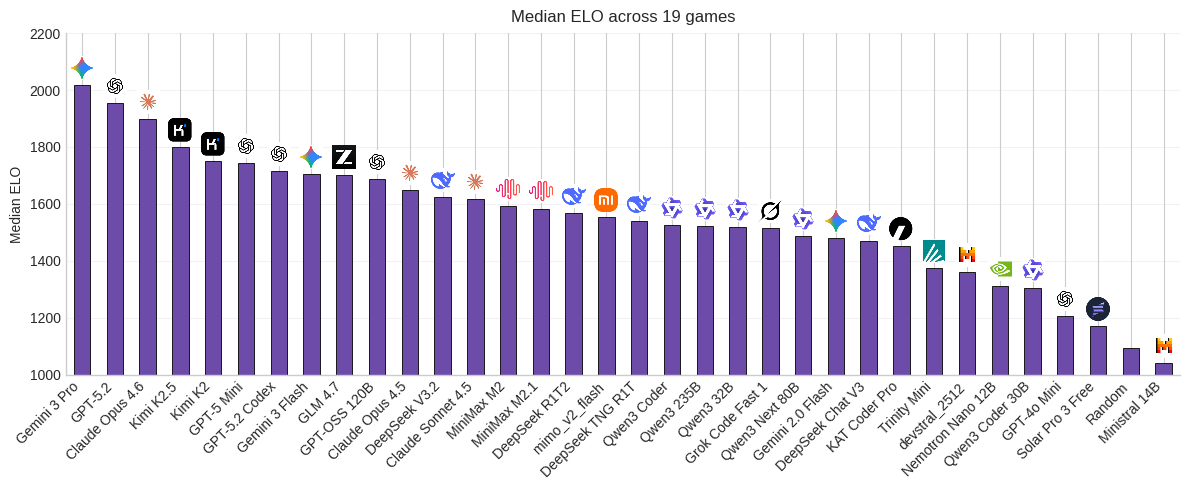

In [247]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

elos_df = pd.concat(elos, axis=1)
elos_df.columns = colnames
_cols = elos_df.columns.tolist()
elos_df["Median ELO"] = elos_df.fillna(-9999).median(axis=1, skipna=False).round(1)
elos_df["Mean ELO"]   = elos_df.fillna(0).mean(axis=1).round(1)
elos_df = elos_df[["Median ELO", "Mean ELO"] + _cols]
elos_df = elos_df.sort_values("Median ELO", ascending=False)

n_games = len(elos_df.columns) - 2
print('n_games', n_games)

ax = elos_df["Median ELO"].plot.bar(
    figsize=(12, 5),
    color="#6c4ca8",
    edgecolor="black",
    linewidth=0.6
)

ax.set_xticklabels([MODEL_NAME_MAP.get(m, m) for m in elos_df.index.astype(str)],
                   rotation=45, ha="right")

ax.set_ylabel("Median ELO")
ax.set_title(f"Median ELO across {n_games} games", pad=8)
ax.set_ylim(1000, 2200)
plt.xticks(rotation=45, ha="right")
ax.grid(axis="y", alpha=0.25, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

logo_zoom = 0.18
y_pad = 18  # ELO units above bar; tweak

for patch, name in zip(ax.patches, elos_df.index.astype(str)):
    if name == "random":
        continue
    x = patch.get_x() + patch.get_width() / 2
    y = patch.get_height()
    arr = get_logo(name)
    ax.add_artist(AnnotationBbox(
        OffsetImage(arr, zoom=logo_zoom),
        (x, y + y_pad),
        xycoords="data",
        frameon=False,
        box_alignment=(0.5, 0.0),
        pad=0.0,
        zorder=5,
        clip_on=False,
    ))

plt.tight_layout()
plt.show()

out_svg = "figures/elo_median_all.svg"
fig = ax.get_figure()
fig.savefig(out_svg, format="svg", bbox_inches="tight")


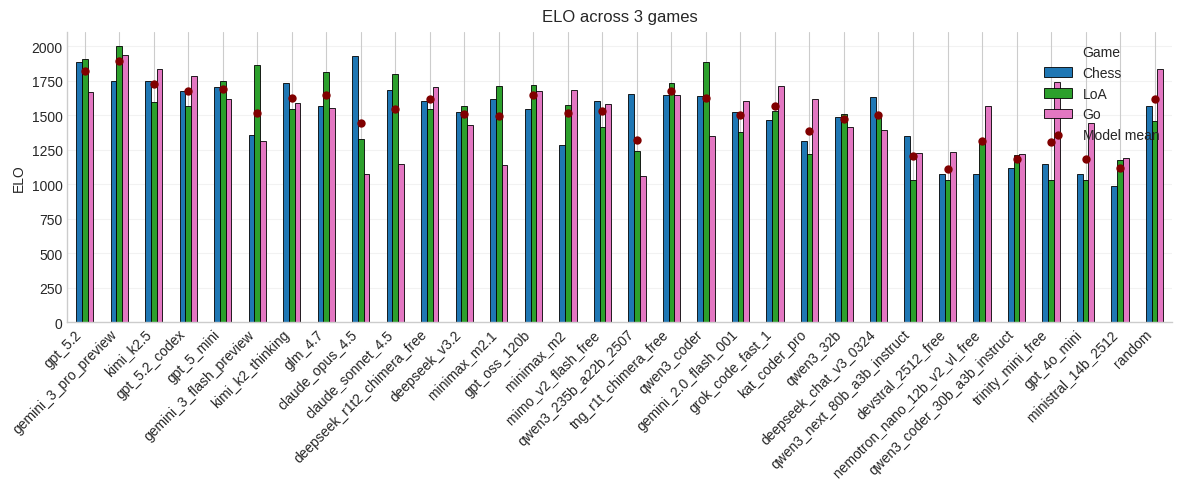

In [45]:
import matplotlib.pyplot as plt

cols = ["Chess", "LoA", 'Go']
# cols = ["Chess", "LoA", 'Go']
# cols = ["Chess", "Chess UCI"]

df = pd.concat(elos, axis=1)
df.columns = colnames
# df = df.drop(columns=['Chess'])
df = df.rename(columns={'Chess UCI': 'Chess'})
df['Median ELO'] = df.fillna(-9999).median(axis=1, skipna=False).round(1)
df = df.sort_values(by='Median ELO', ascending=False)
df = df[cols]
row_means = df.mean(axis=1)

palette = [
    "#1f77b4",  # blue
    "#2ca02c",  # green
    "#e377c2",  # pink
    "#9467bd",  # purple
    "#ff7f0e",  # orange
    "#8c564b",  # brown
    "#7f7f7f",  # gray
    "#bcbd22",  # olive
    "#17becf",  # teal
]
ax = df.plot.bar(
    figsize=(12, 5),
    color=[palette[i] for i, c in enumerate(cols)],
    edgecolor="black",
    linewidth=0.6,
    width=0.5
)
ax.set_ylabel("ELO")
ax.set_title("ELO across 3 games", pad=8)
# ax.set_ylim(1000, 2400)
plt.xticks(rotation=45, ha="right")
ax.grid(axis="y", alpha=0.25, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(
    title="Game",
    # frameon=False,
    # ncol=3,
    loc="upper right",
)
# Add small mean indicators (one per model)
x_positions = range(len(df))
mean_markers = ax.plot(
    x_positions,
    row_means,
    linestyle="None",
    marker=".",
    markersize=8,
    markeredgewidth=2,
    color="maroon",
)

# Update legend to include the mean marker
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles + [mean_markers[0]],
    labels + ["Model mean"],
    title="Game",
    loc="upper right",
)

plt.tight_layout()
plt.show()
out_svg = "figures/elo_across_3_games.svg"
fig = ax.get_figure()
fig.savefig(out_svg, format="svg", bbox_inches="tight")


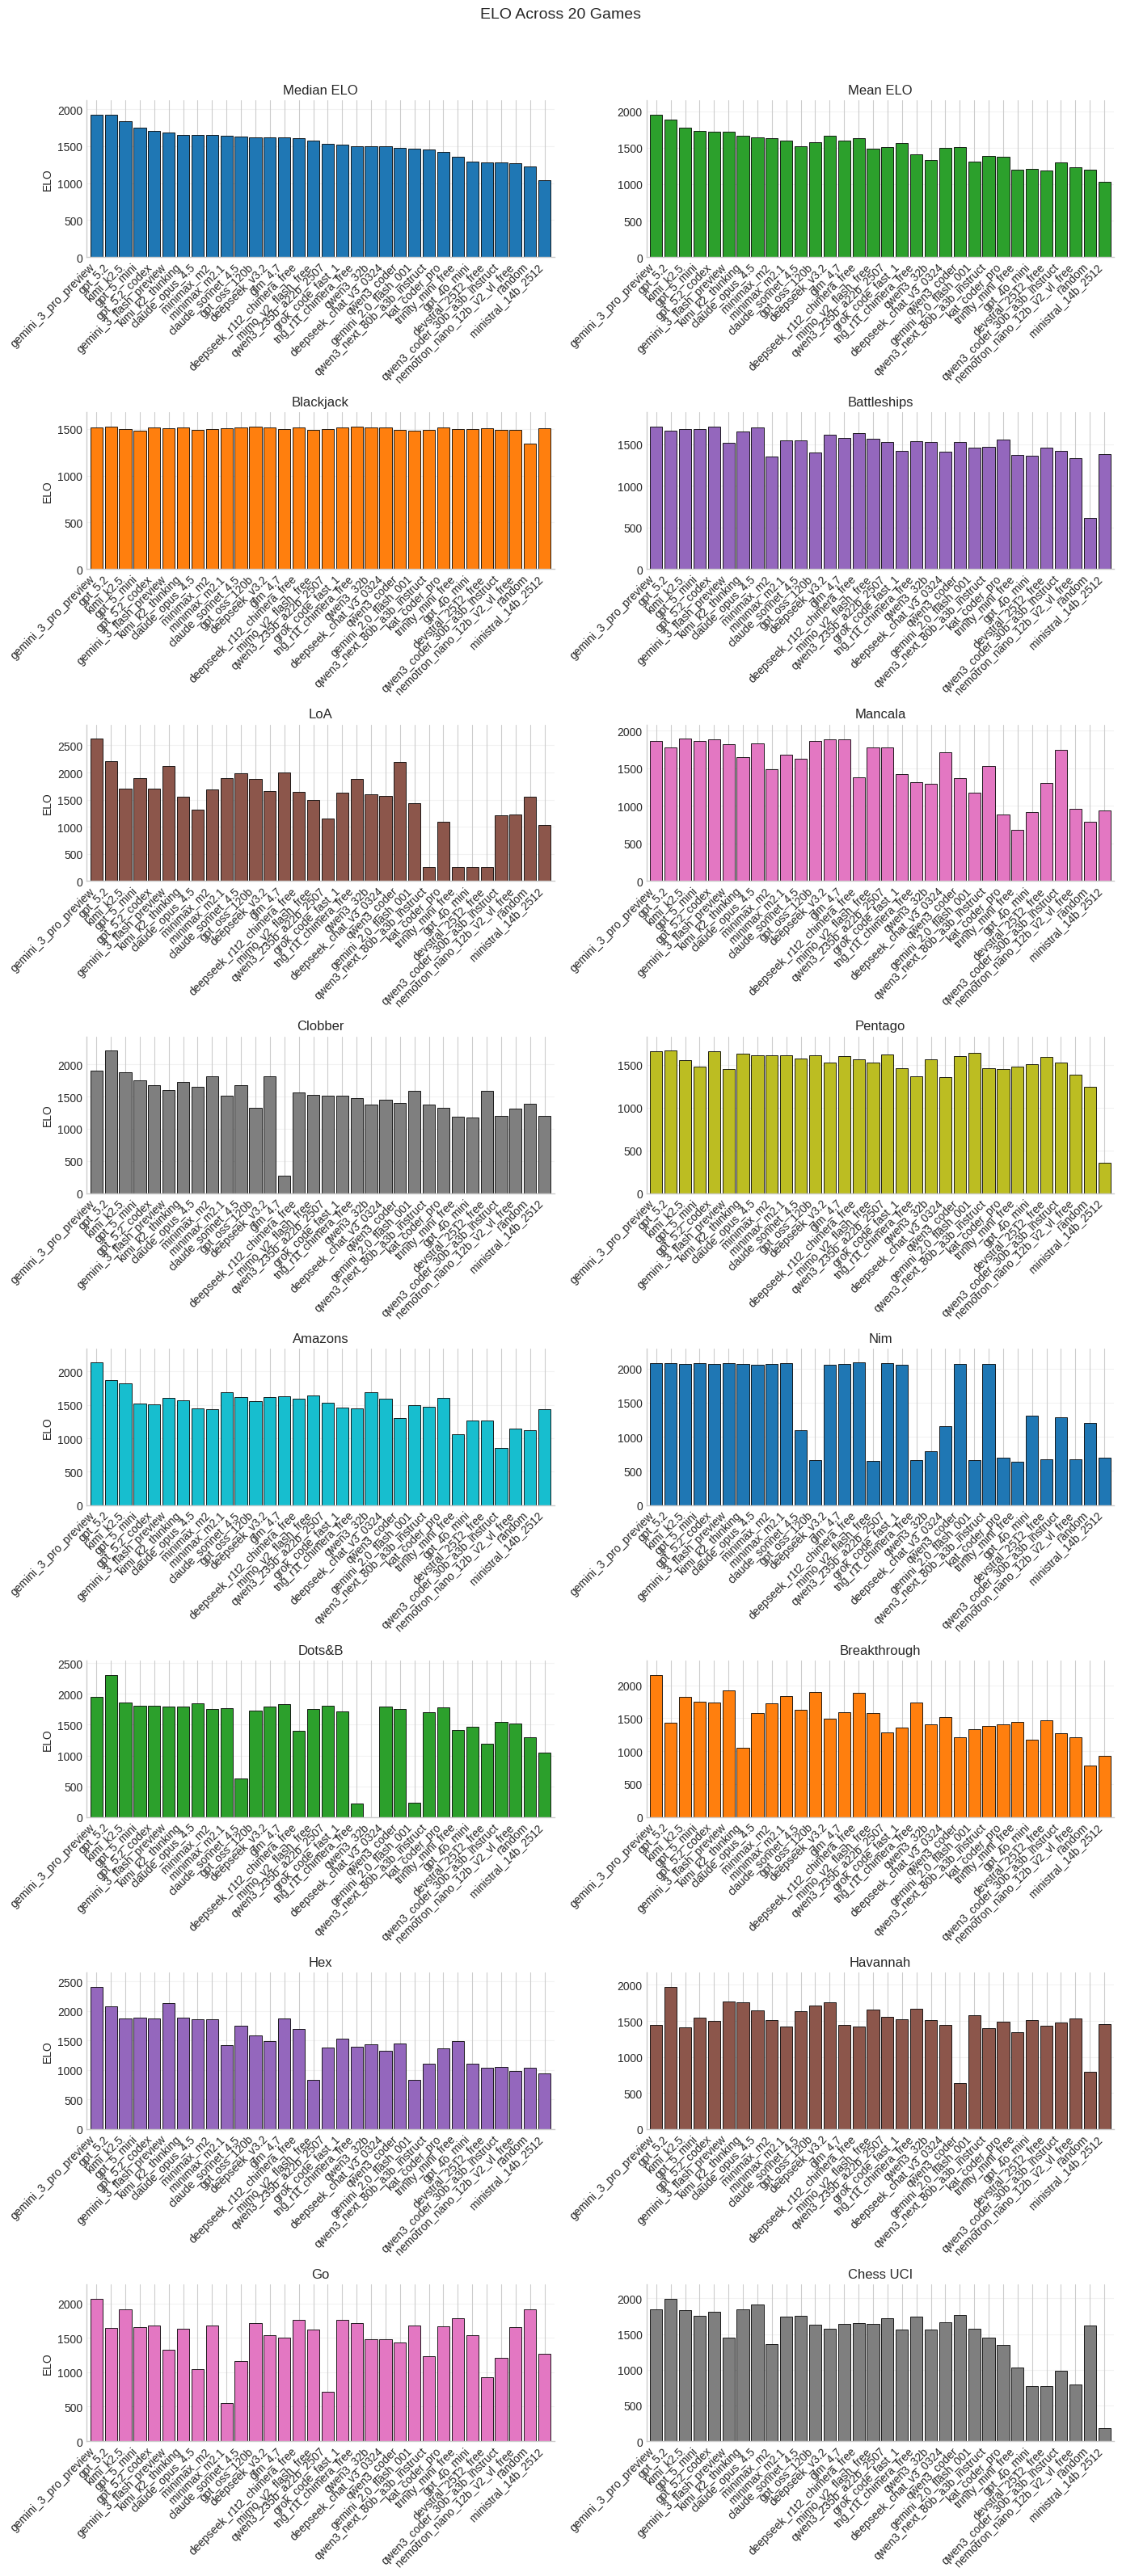

In [ ]:
import math
import matplotlib.pyplot as plt

palette = [
    "#1f77b4",  # blue
    "#2ca02c",  # green
    "#ff7f0e",  # orange
    "#9467bd",  # purple
    "#8c564b",  # brown
    "#e377c2",  # pink
    "#7f7f7f",  # gray
    "#bcbd22",  # olive
    "#17becf",  # teal
]

cols = elos_df.columns
n_cols = len(cols)
n_plot_cols = 2
n_plot_rows = math.ceil(n_cols / n_plot_cols)

fig, axes = plt.subplots(
    n_plot_rows,
    n_plot_cols,
    figsize=(14, 4 * n_plot_rows),
    sharey=False
)

axes = axes.flatten()

for asdf, col in enumerate(cols):
    ax = axes[asdf]

    series = elos_df[col]

    series.plot.bar(
        ax=ax,
        color=palette[asdf % len(palette)],
        edgecolor="black",
        linewidth=0.6,
        width=0.85
    )

    col_max = series.max()
    y_min = 0
    y_max = col_max * 1.1  # 10% headroom

    ax.set_ylim(y_min, y_max)

    ax.set_title(col, pad=6)

    if asdf % n_plot_cols == 0:
        ax.set_ylabel("ELO")
    else:
        ax.set_ylabel("")

    ax.tick_params(axis="x", rotation=45)
    for label in ax.get_xticklabels():
        label.set_ha("right")

    ax.grid(axis="y", alpha=0.25, linewidth=0.8)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Hide unused axes
for j in range(asdf + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("ELO Across 20 Games", fontsize=14, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


chess world1 85150
chess worlduci1 18300
total games = 103450


/tmp/ipykernel_527821/3509093660.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


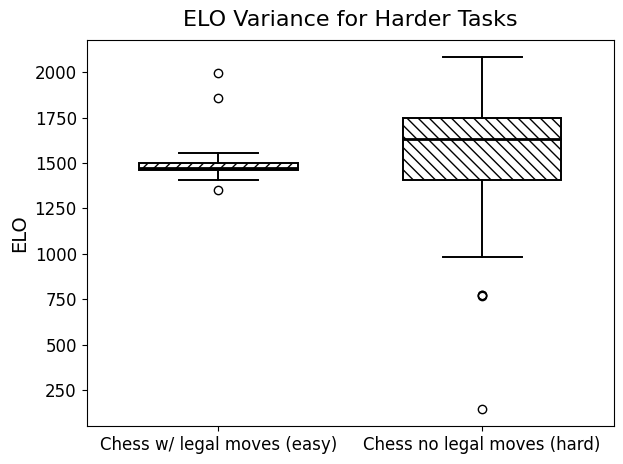

In [89]:
import matplotlib.pyplot as plt

gs = [('chess', 'world1', 'Chess', None), ('chess', 'worlduci1', 'Chess UCI', None)]
main_elo_data = get_main_elo_data(gs, result_dir='results_chess_uci_vs_normal')
elos = main_elo_data['elos']
colnames = main_elo_data['colnames']

with plt.rc_context({
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
}):
    # ---- everything in here uses the custom fonts ----
    fig, ax = plt.subplots()

    data = [elos[0]['ELO'].dropna().values, elos[1]['ELO'].dropna().values]
    labels = {"Chess": "Chess w/ legal moves (easy)", "Chess UCI": "Chess no legal moves (hard)"}
    labels = [labels[col] for col in colnames]


    bp = ax.boxplot(
        data,
        labels=labels,
        patch_artist=True,
        widths=0.6,
        showfliers=True
    )

    hatches = ["///", "\\\\\\"]
    for patch, hatch in zip(bp["boxes"], hatches):
        patch.set_facecolor("none")
        patch.set_edgecolor("black")
        patch.set_linewidth(1.4)
        patch.set_hatch(hatch)

    for median in bp["medians"]:
        median.set_color("black")
        median.set_linewidth(2.0)

    for whisker in bp["whiskers"]:
        whisker.set_color("black")
        whisker.set_linewidth(1.4)

    for cap in bp["caps"]:
        cap.set_color("black")
        cap.set_linewidth(1.4)

    for flier in bp["fliers"]:
        flier.set_marker("o")
        flier.set_markerfacecolor("none")
        flier.set_markeredgecolor("black")
        flier.set_markersize(6)

    ax.set_title("ELO Variance for Harder Tasks", pad=10)
    ax.set_ylabel("ELO")

    plt.tight_layout()
    plt.show()

# -------- Save to SVG --------
out_pdf = "figures/elo_variance_san_vs_uci.pdf"
fig.savefig(out_pdf, format="pdf", bbox_inches="tight")
plt.show()


# Variance between bots

In [201]:
elos = []
for game_str, world, match_json, colname in gs:
    if match_json is None:
        match_json = get_matches_filename(game_str, world)
    all_data_pruned = get_match_results(game_str, world, match_json)
    elo_pre, _ = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='none', verbose=False)
    elos.append(elo_pre)
elos_df = pd.concat(elos, axis=1)
elos_df.columns = [n for _,_,_,n in gs]


In [235]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def boxplot_by_model(
    df: pd.DataFrame,
    column: str,
    *,
    index_col: str = None,
    min_points_per_model: int = 1,
    order: str = "median_desc",  # "median_desc", "median_asc", or "alphabetical"
    figsize=(12, 6),
    rotate_xticks: int = 45,
    show_points: bool = True,
    point_jitter: float = 0.2,
    na_strings=("N/A", "DNQ"),
):
    if column not in df.columns:
        raise ValueError(f"Column '{column}' not found. Available columns: {list(df.columns)}")

    # Normalize ids to a Series with df's index (works whether source is index or a column)
    if index_col is None:
        ids = pd.Series(df.index.astype(str), index=df.index, name="id")
        base_df = df
    else:
        if index_col not in df.columns:
            raise ValueError(f"index_col '{index_col}' not found in df columns.")
        ids = df[index_col].astype(str)
        base_df = df

    # Split into model and bot id (and drop rows without '/')
    mask = ids.str.contains("/")
    removed_rows = ids[~mask]
    if len(removed_rows) > 0:
        print(f"Removed {len(removed_rows)} rows with no model/bot id: {removed_rows.tolist()}")
        ids = ids[mask]

    # Filter the data to the same rows as ids (ids is a Series, so .index is valid)
    base_df = base_df.loc[ids.index]

    # Robust parsing (guarantees 2 Series, never tuples)
    extracted = ids.str.extract(r"^(?P<model>[^/]+)/(?P<bot>.+)$")
    model = extracted["model"]
    bot = extracted["bot"]

    # Clean and coerce values: treat 'N/A' and 'DNQ' as missing, coerce others to numeric
    clean_values = (
        base_df[column]
        .replace(list(na_strings), np.nan)
        .apply(lambda x: x.strip() if isinstance(x, str) else x)
    )
    clean_values = pd.to_numeric(clean_values, errors="coerce")

    plot_df = pd.DataFrame(
        {"model": model, "bot": bot, "value": clean_values},
        index=ids.index,
    ).dropna(subset=["value"])

    # Enforce minimum points per model
    counts = plot_df.groupby("model")["value"].size()
    keep_models = counts[counts >= min_points_per_model].index
    plot_df = plot_df[plot_df["model"].isin(keep_models)]

    if plot_df.empty:
        raise ValueError(
            f"No data to plot for column '{column}' after dropping {na_strings} "
            f"and applying min_points_per_model={min_points_per_model}."
        )

    # Determine model order
    if order == "alphabetical":
        model_order = sorted(plot_df["model"].unique())
    elif order in ("median_desc", "median_asc"):
        med = plot_df.groupby("model")["value"].median().sort_values(
            ascending=(order == "median_asc")
        )
        model_order = med.index.tolist()
    else:
        raise ValueError("order must be one of: 'median_desc', 'median_asc', 'alphabetical'")

    # Plot
    plt.figure(figsize=figsize)
    ax = sns.boxplot(data=plot_df, x="model", y="value", order=model_order)

    if show_points:
        sns.stripplot(
            data=plot_df,
            x="model",
            y="value",
            order=model_order,
            jitter=point_jitter,
            alpha=0.6,
            dodge=False,
        )

    ax.set_title(f"Distribution of ELO by model for '{column}'")
    ax.set_xlabel("Model")
    ax.set_ylabel("ELO")
    if rotate_xticks:
        ax.tick_params(axis="x", rotation=rotate_xticks)
        for lbl in ax.get_xticklabels():
            lbl.set_horizontalalignment("right")   # anchor the RIGHT edge at the tick
            lbl.set_rotation_mode("anchor")        # rotate around the anchor point
    plt.tight_layout()
    return ax, plot_df


Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for '3D TTT'"}, xlabel='Model', ylabel='ELO'>

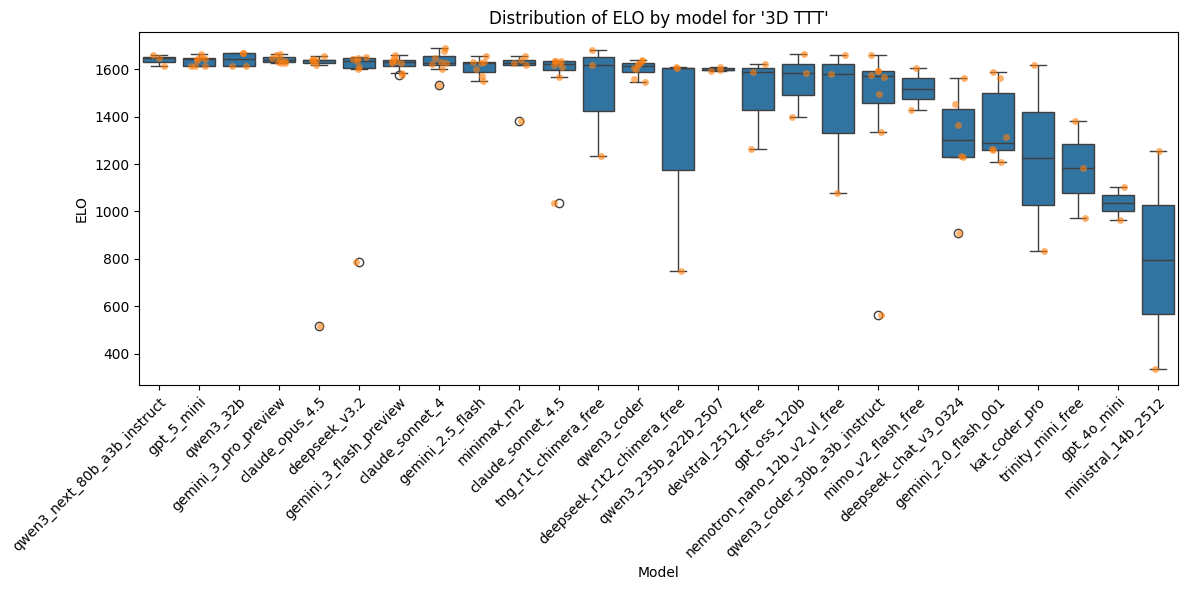

Saved: model_sample_elo_variance/3D_TTT_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for '3x3 TTT'"}, xlabel='Model', ylabel='ELO'>

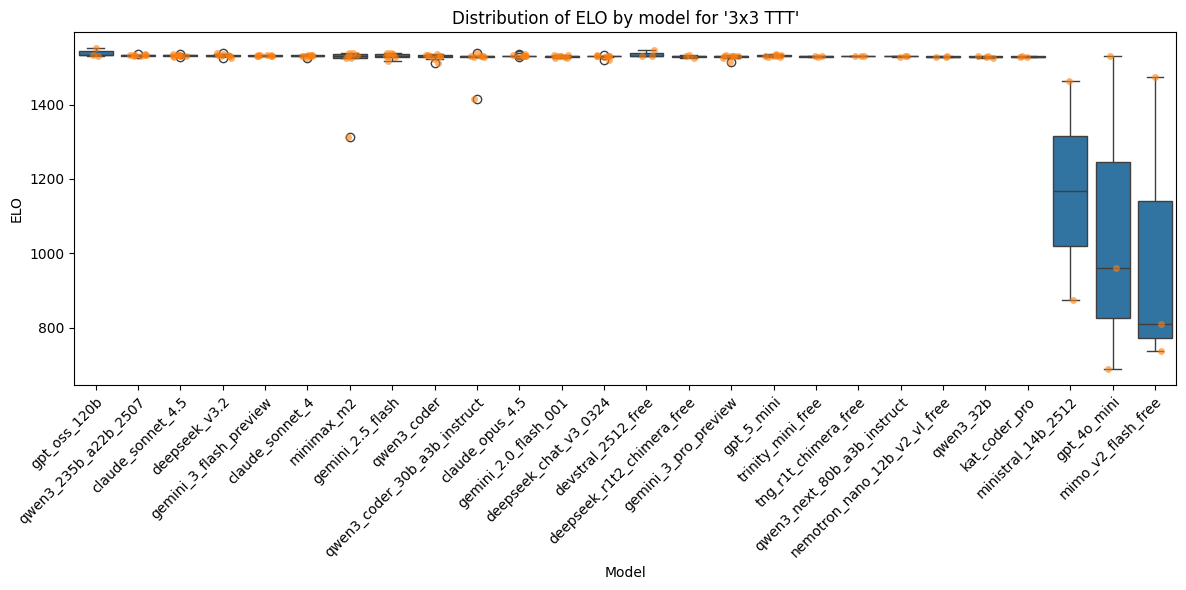

Saved: model_sample_elo_variance/3x3_TTT_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for '4x4 TTT'"}, xlabel='Model', ylabel='ELO'>

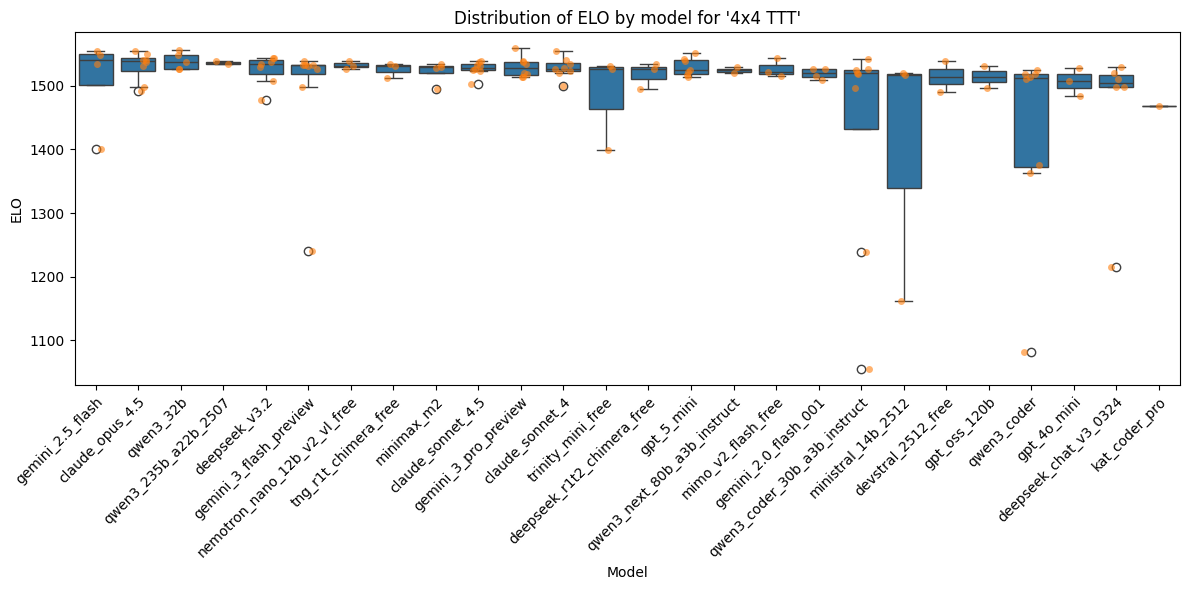

Saved: model_sample_elo_variance/4x4_TTT_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


<Axes: title={'center': "Distribution of ELO by model for 'Blackjack'"}, xlabel='Model', ylabel='ELO'>

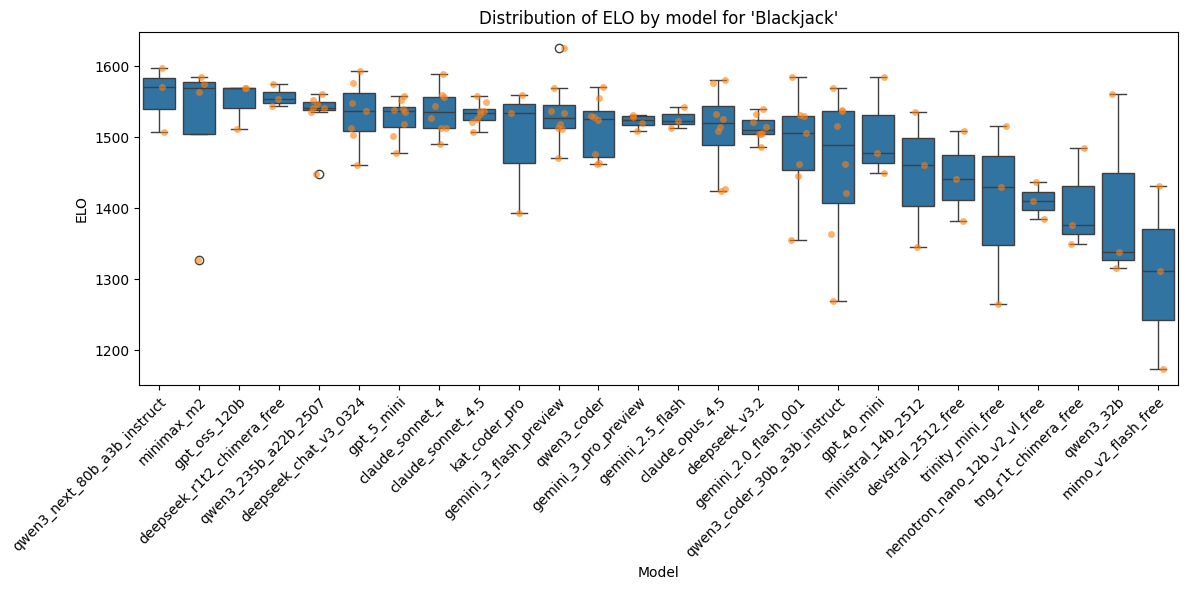

Saved: model_sample_elo_variance/Blackjack_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Battleships'"}, xlabel='Model', ylabel='ELO'>

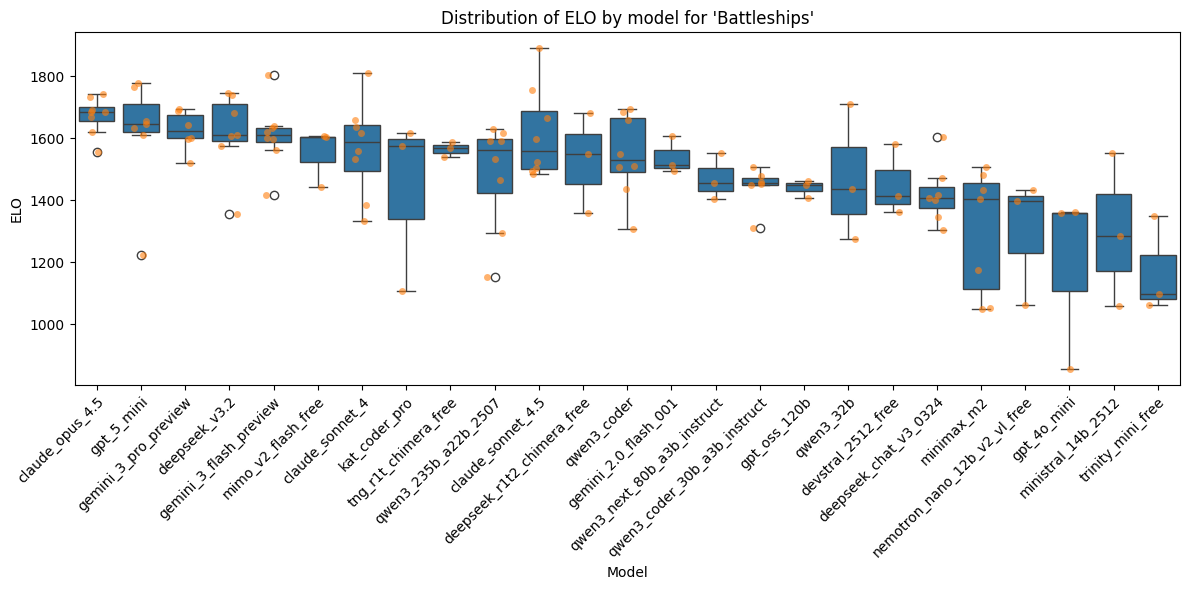

Saved: model_sample_elo_variance/Battleships_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Connect4'"}, xlabel='Model', ylabel='ELO'>

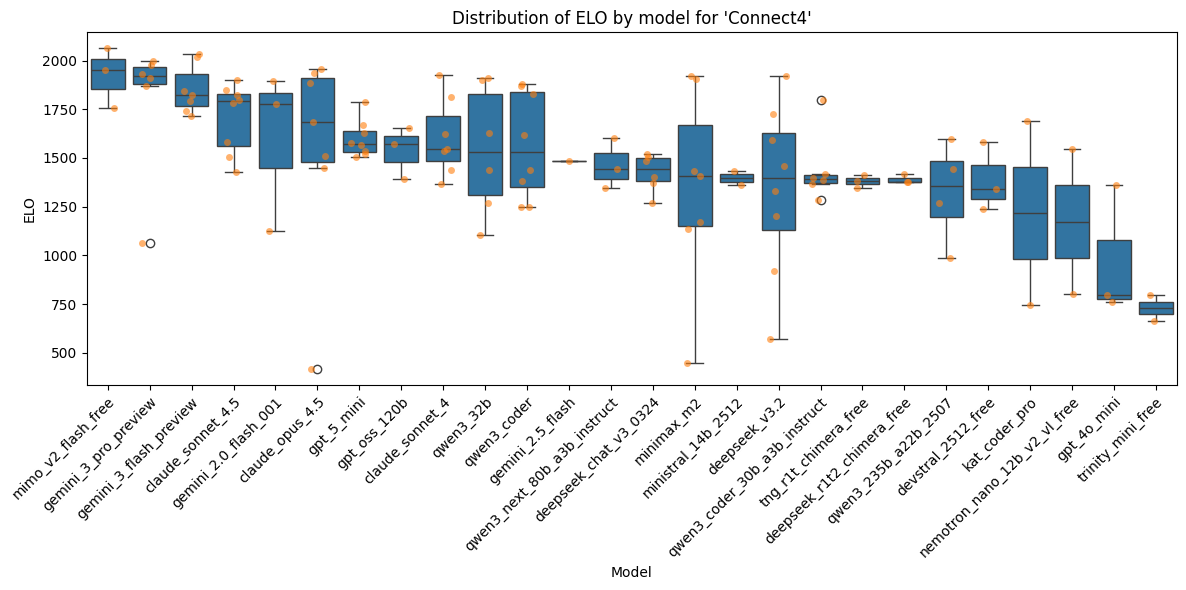

Saved: model_sample_elo_variance/Connect4_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'LoA'"}, xlabel='Model', ylabel='ELO'>

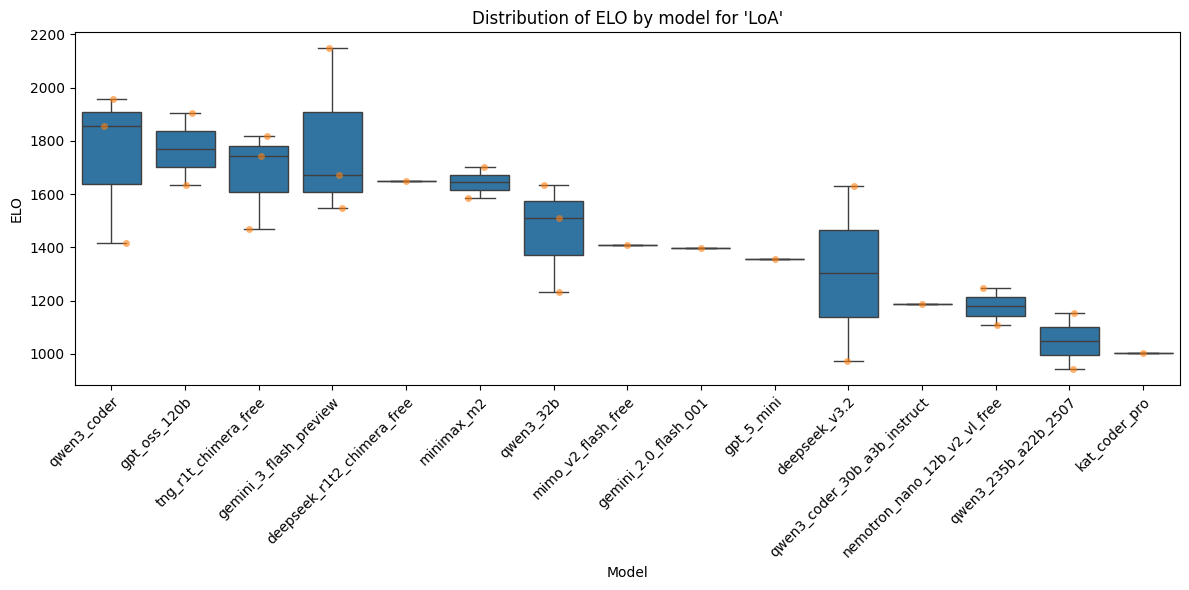

Saved: model_sample_elo_variance/LoA_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Mancala'"}, xlabel='Model', ylabel='ELO'>

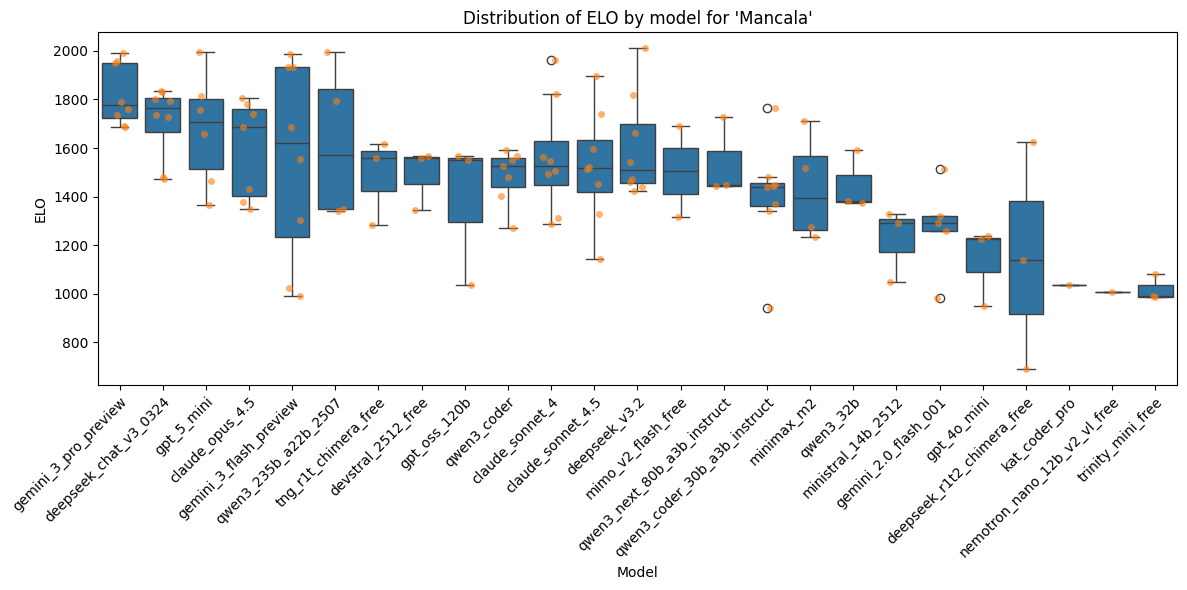

Saved: model_sample_elo_variance/Mancala_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Clobber'"}, xlabel='Model', ylabel='ELO'>

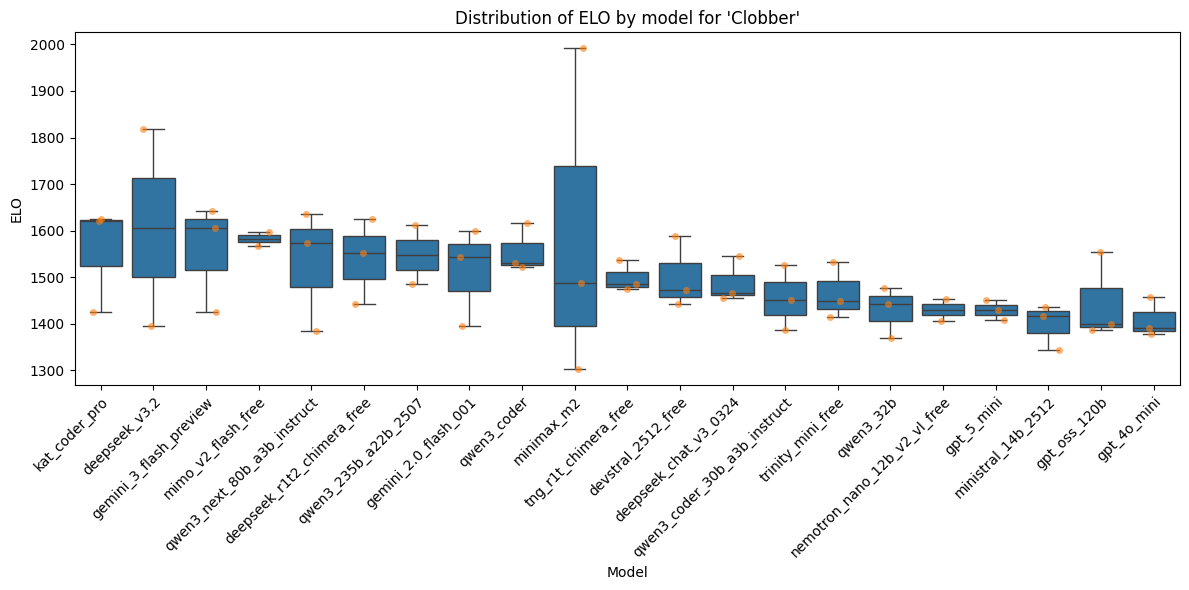

Saved: model_sample_elo_variance/Clobber_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Pentago'"}, xlabel='Model', ylabel='ELO'>

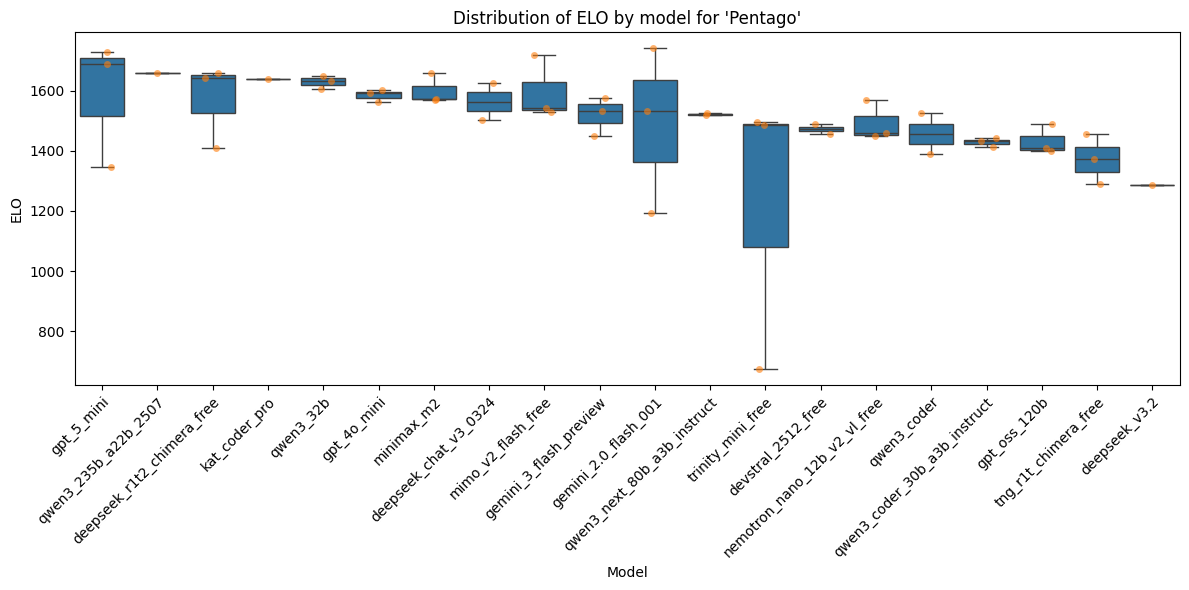

Saved: model_sample_elo_variance/Pentago_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Amazons'"}, xlabel='Model', ylabel='ELO'>

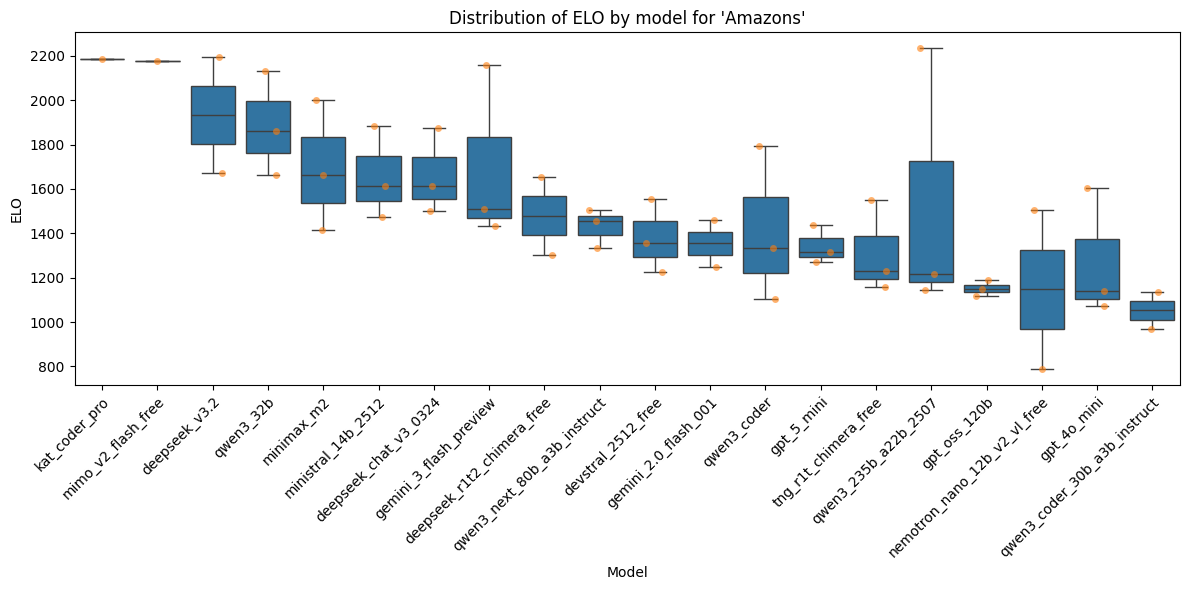

Saved: model_sample_elo_variance/Amazons_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Nim'"}, xlabel='Model', ylabel='ELO'>

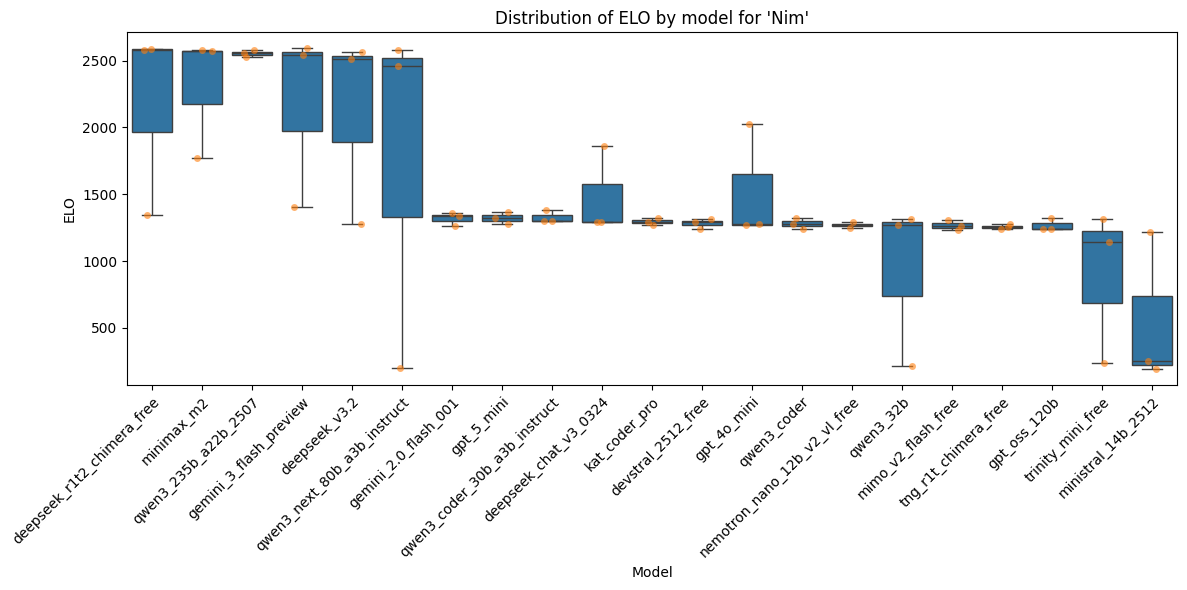

Saved: model_sample_elo_variance/Nim_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Dots&B'"}, xlabel='Model', ylabel='ELO'>

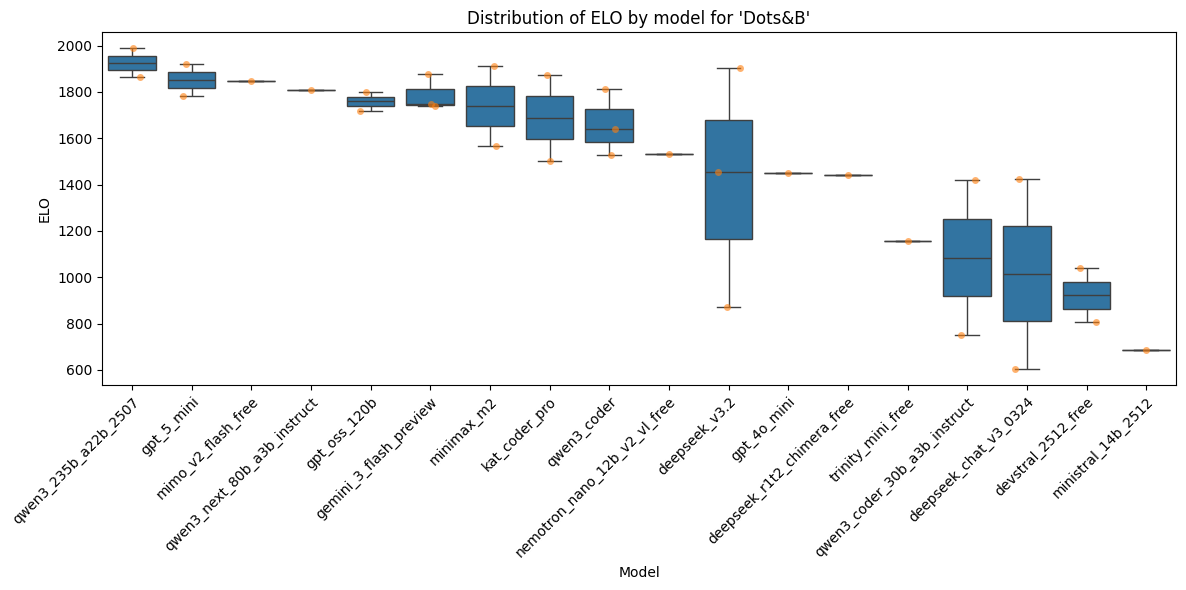

Saved: model_sample_elo_variance/Dots&B_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Chess'"}, xlabel='Model', ylabel='ELO'>

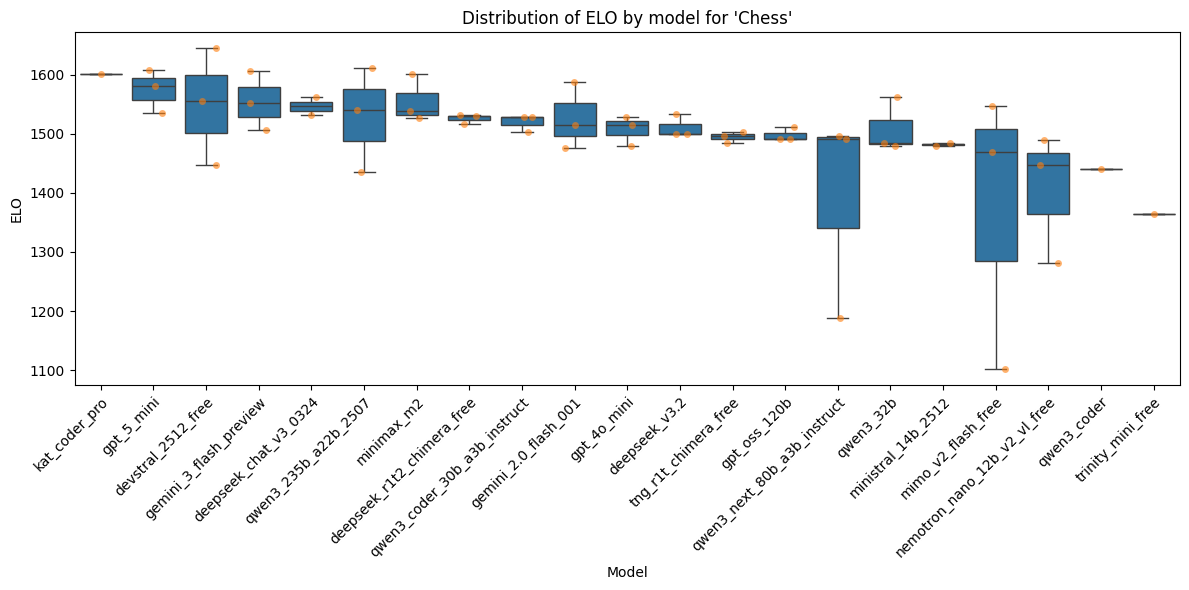

Saved: model_sample_elo_variance/Chess_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Breakthrough'"}, xlabel='Model', ylabel='ELO'>

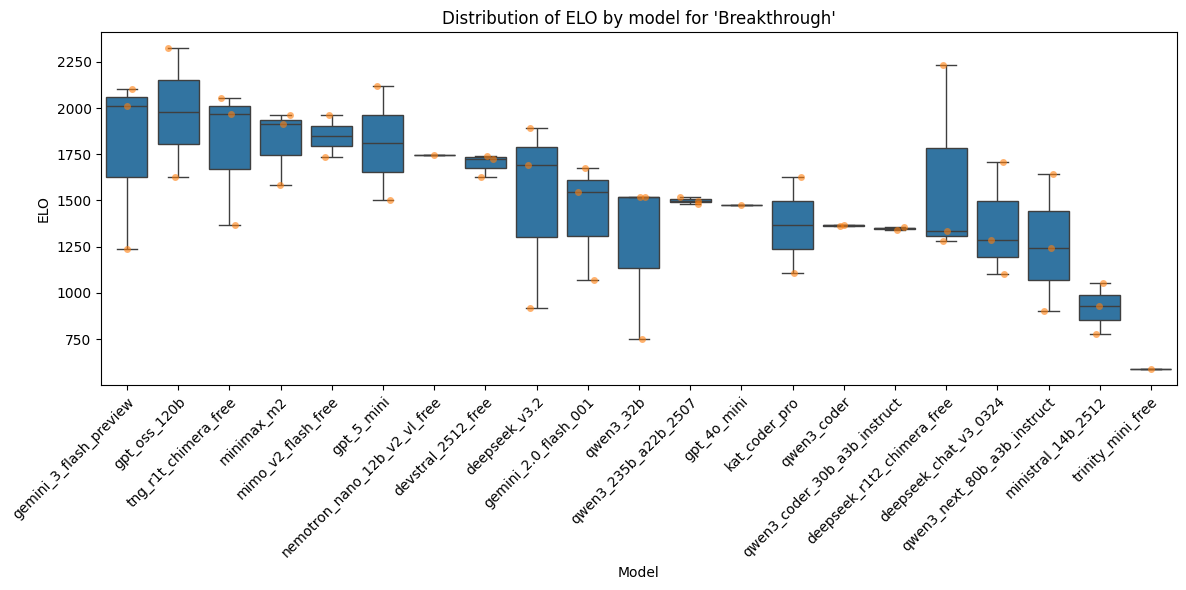

Saved: model_sample_elo_variance/Breakthrough_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Hex'"}, xlabel='Model', ylabel='ELO'>

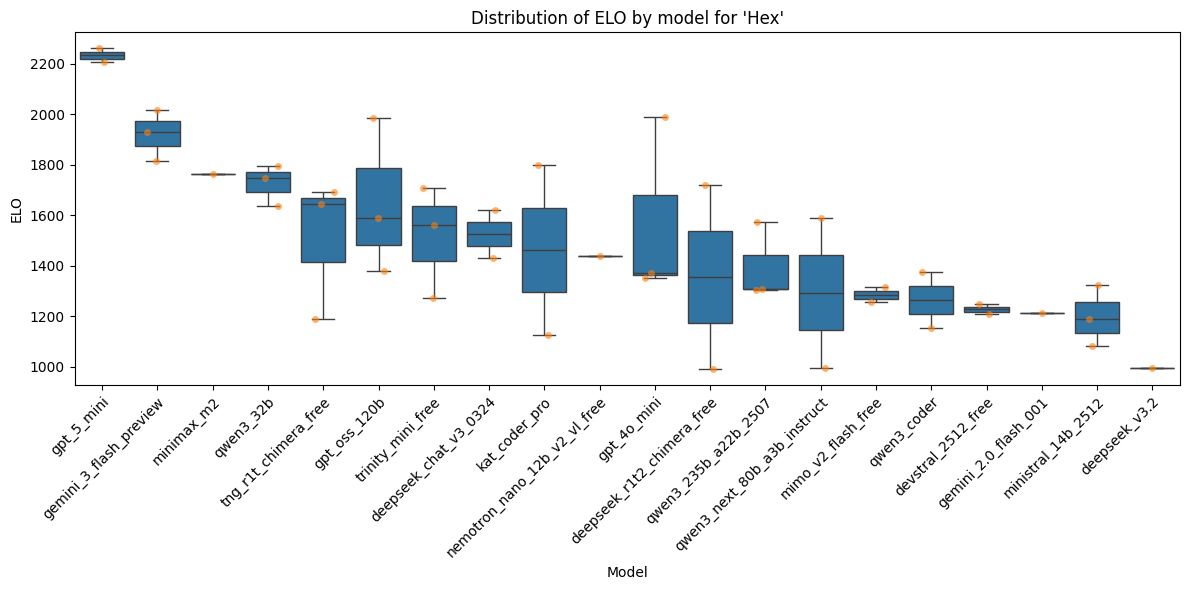

Saved: model_sample_elo_variance/Hex_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Havannah'"}, xlabel='Model', ylabel='ELO'>

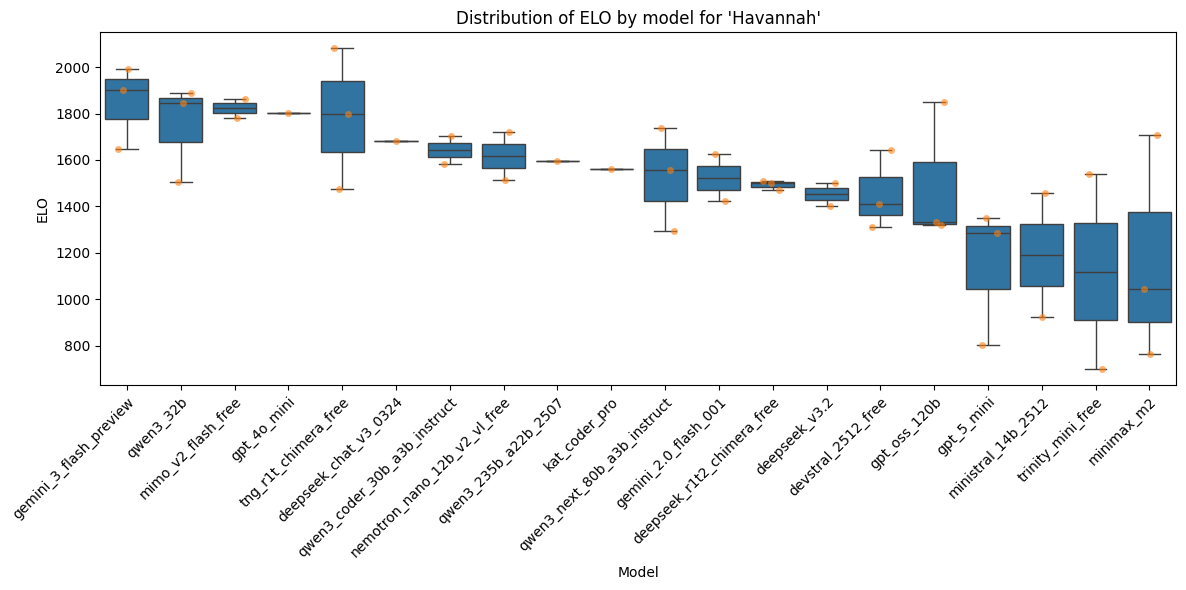

Saved: model_sample_elo_variance/Havannah_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Go'"}, xlabel='Model', ylabel='ELO'>

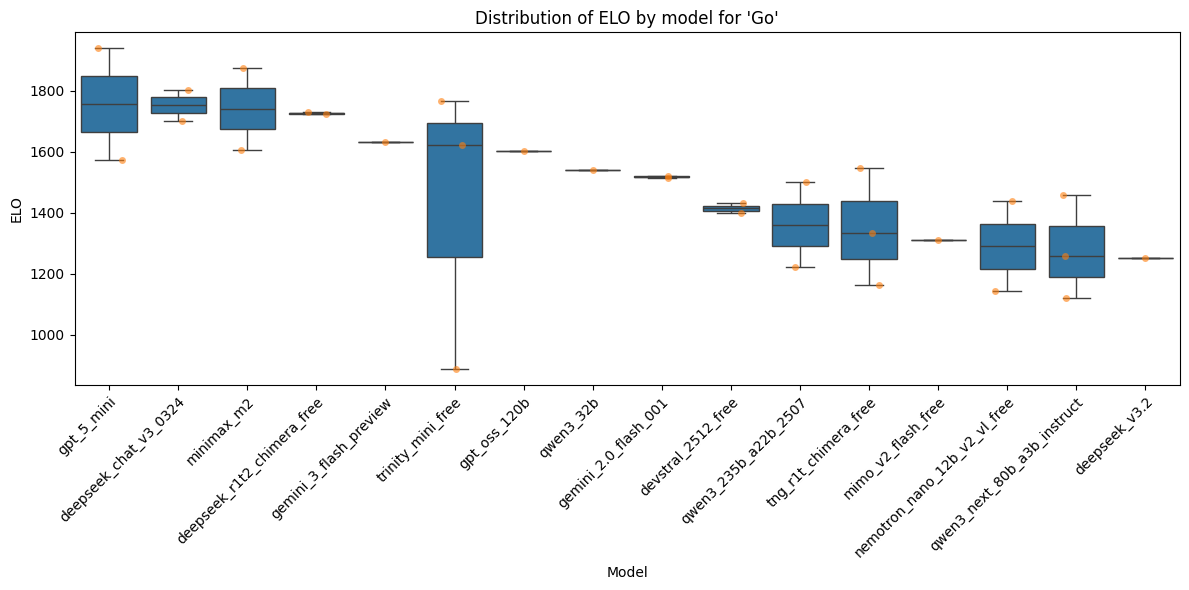

Saved: model_sample_elo_variance/Go_20260121_142308.png
Removed 1 rows with no model/bot id: ['random']


/tmp/ipykernel_602595/4000338404.py:49: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  base_df[column]


<Axes: title={'center': "Distribution of ELO by model for 'Checkers'"}, xlabel='Model', ylabel='ELO'>

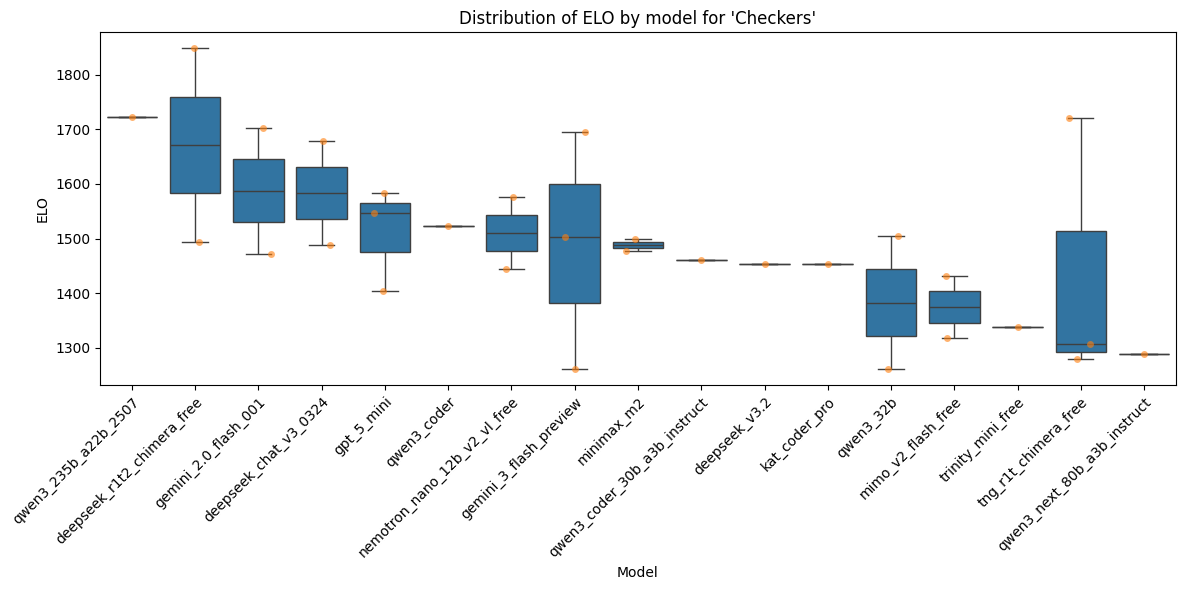

Saved: model_sample_elo_variance/Checkers_20260121_142308.png


In [241]:
import os
from datetime import datetime
import matplotlib.pyplot as plt
output_dir = "model_sample_elo_variance"
os.makedirs(output_dir, exist_ok=True)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
for game in df.columns:
    try:
        ax, plot_df = boxplot_by_model(df, game)
        safe_game = game.strip().replace(" ", "_").replace("/", "_")
        filename = f"{safe_game}_{timestamp}.png"
        filepath = os.path.join(output_dir, filename)
        fig = ax.get_figure()
        fig.savefig(filepath, dpi=200, bbox_inches="tight")
        display(ax)
        plt.show()
        plt.close(fig)
        print(f"Saved: {filepath}")
    except Exception as e:
        print(f"Skipping '{game}': {e}")


# repitition

In [ ]:

gs = [
    ['lines_of_action', 'world1', 'matches_lines_of_action_world1_rep1.json', 'Lines of Action R1 ELO'],
    ['lines_of_action', 'world1', 'matches_lines_of_action_world1_rep2.json', 'Lines of Action R2 ELO'],
    ['lines_of_action', 'world1', 'matches_lines_of_action_world1_rep3.json', 'Lines of Action R3 ELO'],
    ['lines_of_action', 'world1', 'matches_lines_of_action_world1_rep4.json', 'Lines of Action R4 ELO'],
    ['lines_of_action', 'world1', 'matches_lines_of_action_world1_rep5.json', 'Lines of Action R5 ELO'],
    ['lines_of_action', 'world1', 'matches_lines_of_action_world1_rep6.json', 'Lines of Action R6 ELO'],
    ['lines_of_action', 'world1', 'matches_lines_of_action_world1_rep7.json', 'Lines of Action R6 ELO'],
]
gs = [
    ['lines_of_action', 'world1', 'matches_lines_of_action_world1_grep1.json', 'Lines of Action R1 ELO'],
    ['lines_of_action', 'world1', 'matches_lines_of_action_world1_grep2.json', 'Lines of Action R2 ELO'],
    ['lines_of_action', 'world1', 'matches_lines_of_action_world1_grep3.json', 'Lines of Action R3 ELO'],
]

gs = [
    ['poker', 'world1', ('results_experiments_jan14', 'matches_poker_world1_6k_1.json'), 'Poker ELO 1'],
    # ['poker', 'world1', ('results_experiments_jan14', 'matches_poker_world1_6k_2.json'), 'Poker ELO 2'],
    ['poker', 'world1', ('results_experiments_jan14', 'matches_poker_world1_6k_3.json'), 'Poker ELO 3'],
]

gs = [
    ['poker', 'world1', ('results_experiments_jan14', 'matches_poker_world1_16k_1.json'), 'Poker ELO 1'],
    ['poker', 'world1', ('results_experiments_jan14', 'matches_poker_world1_16k_2.json'), 'Poker ELO 2'],
    ['poker', 'world1', ('results_experiments_jan14', 'matches_poker_world1_16k_3.json'), 'Poker ELO 3'],
]

elos = []
top_models_names = {}
for game_str, world, match_json, colname in gs:
    if isinstance(match_json, str):
        all_data = get_match_results(game_str, world, match_json)
    else:
        all_data = get_match_results(game_str, world, match_json[1], result_dir=match_json[0])
    
    elo_pre, top_models = run_leaderboard.get_elo_df_combined(all_data, combine_method='none', verbose=False)
    # top_models_names_single_game = set(top_models)
    # top_models_names[colname] = {x.split('/')[0]: (x.split('/')[1] if len(x.split('/')) > 1 else '') for x in top_models_names_single_game}
    # all_data_pruned = [g for g in all_data if g['name0'] in top_models_names and g['name1'] in top_models_names and ('OLD_' not in g['name0'] and 'OLD_' not in g['name1'])]
    # for g in all_data_pruned:
    #     g['name0'] = g['name0'].split('/')[0]
    #     if g['name0'].startswith('world1'):
    #         g['name0'] = g['name0'].split(':')[1]
    #     g['name1'] = g['name1'].split('/')[0]
    #     if g['name1'].startswith('world1'):
    #         g['name1'] = g['name1'].split(':')[1]
    # elo_post, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='none', verbose=False)
    elos.append(elo_pre)
for asdf in range(len(elos)):
    elos[asdf] = elos[asdf].astype(float)


In [372]:
# pd.DataFrame(top_models_names)

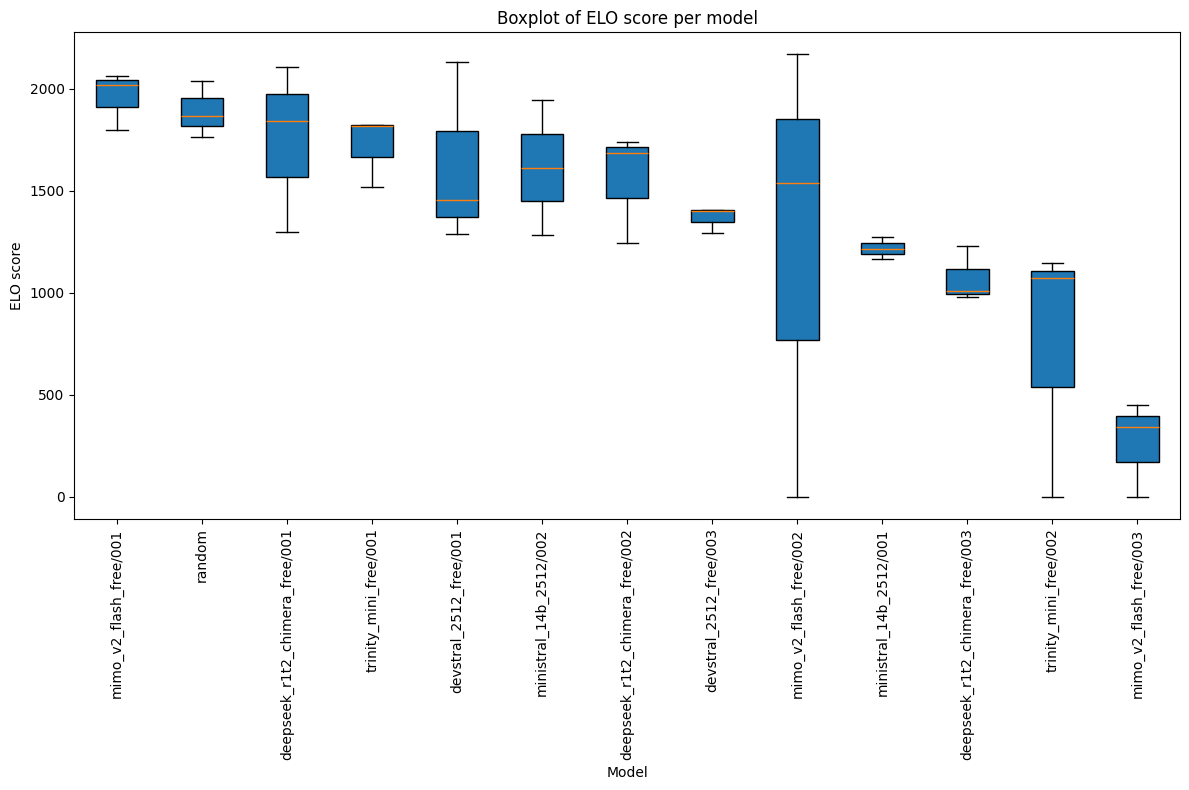

,ELO,ELO,ELO,Mean
mimo_v2_flash_free/001,2061.47,2018.91,1799.59,1960.0
random,1765.39,1868.00,2039.30,1890.9
deepseek_r1t2_chimera_free/001,1296.99,2106.67,1839.56,1747.7
trinity_mini_free/001,1815.05,1515.74,1824.20,1718.3
devstral_2512_free/001,1285.36,2129.14,1453.33,1622.6
ministral_14b_2512/002,1944.78,1284.67,1613.40,1614.3
deepseek_r1t2_chimera_free/002,1686.11,1243.61,1739.53,1556.4
devstral_2512_free/003,1400.31,1406.65,1290.77,1365.9
mimo_v2_flash_free/002,0.00,1536.02,2167.82,1234.6
ministral_14b_2512/001,1165.05,1212.21,1272.98,1216.7


In [400]:
import matplotlib.pyplot as plt
elos_df = pd.concat(elos, axis=1).fillna(0)
elos_df['Mean'] = elos_df.mean(axis=1).round(1)
elos_df = elos_df.sort_values('Mean', ascending=False)


boxplot_data = elos_df.drop(columns=['Mean']).T  # Transpose to have one box per row/model

plt.figure(figsize=(12, 8))
box = plt.boxplot(boxplot_data.values, patch_artist=True)
plt.xticks(range(1, len(elos_df.index) + 1), elos_df.index, rotation=90)
plt.title("Boxplot of ELO score per model")
plt.xlabel("Model")
plt.ylabel("ELO score")
plt.tight_layout()
plt.show()
elos_df

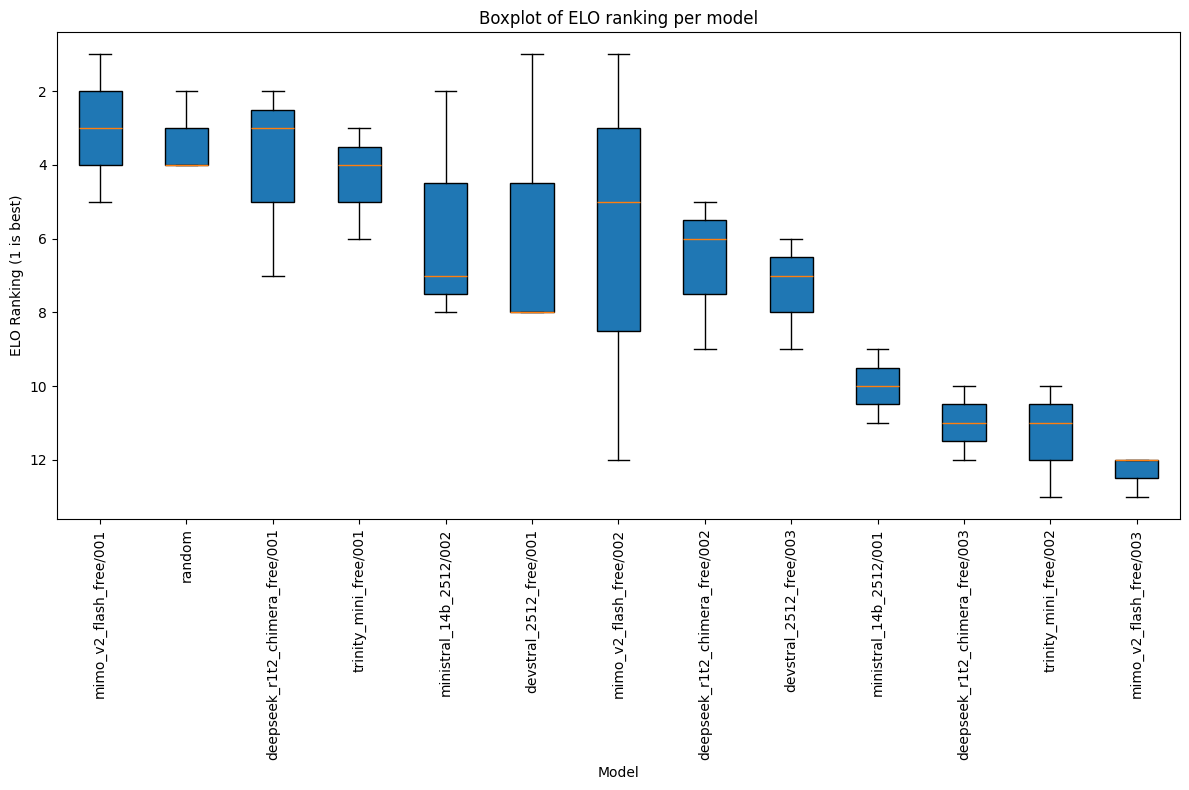

,ELO,ELO,ELO,Mean
mimo_v2_flash_free/001,1.0,3.0,5.0,3.000000
random,4.0,4.0,2.0,3.333333
deepseek_r1t2_chimera_free/001,7.0,2.0,3.0,4.000000
trinity_mini_free/001,3.0,6.0,4.0,4.333333
ministral_14b_2512/002,2.0,8.0,7.0,5.666667
devstral_2512_free/001,8.0,1.0,8.0,5.666667
mimo_v2_flash_free/002,12.0,5.0,1.0,6.000000
deepseek_r1t2_chimera_free/002,5.0,9.0,6.0,6.666667
devstral_2512_free/003,6.0,7.0,9.0,7.333333
ministral_14b_2512/001,9.0,11.0,10.0,10.000000


In [398]:
import matplotlib.pyplot as plt
elos_df = pd.concat(elos, axis=1).fillna(0)
elos_df = elos_df.apply(lambda x: x.rank(ascending=False, method='min'), axis=0)
elos_df['Mean'] = elos_df.mean(axis=1)
elos_df = elos_df.sort_values('Mean')

boxplot_data = elos_df.drop(columns=['Mean']).T  # Transpose to have one box per row/model

plt.figure(figsize=(12, 8))
box = plt.boxplot(boxplot_data.values, patch_artist=True)
plt.xticks(range(1, len(elos_df.index) + 1), elos_df.index, rotation=90)
plt.title("Boxplot of ELO ranking per model")
plt.xlabel("Model")
plt.ylabel("ELO Ranking (1 is best)")
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()
elos_df

elos_df

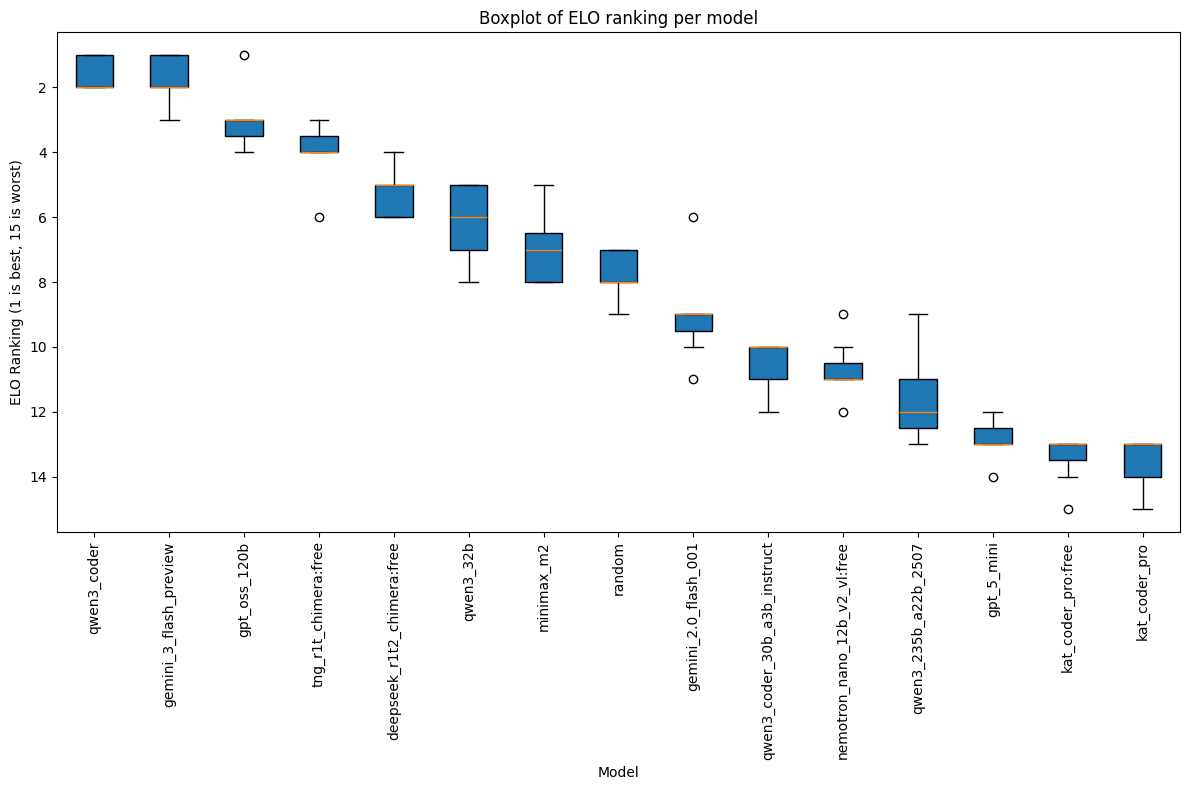

,ELO,ELO,ELO,ELO,ELO,ELO,ELO,Mean
qwen3_coder,2.0,1.0,1.0,2.0,1.0,2.0,2.0,1.571429
gemini_3_flash_preview,3.0,2.0,2.0,1.0,2.0,1.0,1.0,1.714286
gpt_oss_120b,1.0,4.0,3.0,3.0,3.0,3.0,4.0,3.000000
tng_r1t_chimera:free,6.0,3.0,4.0,4.0,4.0,4.0,3.0,4.000000
deepseek_r1t2_chimera:free,4.0,5.0,6.0,6.0,5.0,6.0,5.0,5.285714
qwen3_32b,7.0,7.0,5.0,5.0,8.0,5.0,6.0,6.142857
minimax_m2,5.0,8.0,8.0,7.0,6.0,7.0,8.0,7.000000
random,8.0,9.0,7.0,8.0,7.0,8.0,7.0,7.714286
gemini_2.0_flash_001,11.0,6.0,9.0,9.0,10.0,9.0,9.0,9.000000
qwen3_coder_30b_a3b_instruct,10.0,11.0,11.0,10.0,12.0,10.0,10.0,10.571429


# Policy from model output

In [17]:
# import re
# from src.game_arena import prompter

# newd = Path('src/game_arena/connect4/examples/world1/olmo_3_32b_think:free/003')

# with open(newd / '1.output.txt', 'r') as f:
#     response = f.read()
# python_code = prompter.python_code_from_response(response)
# python_code = python_code.replace('\\n', '\n')
# python_code = re.sub(r"->\s*[^:]*\|[^:]*:", "-> None:", python_code)  # remove union annotations. from "-> x | y" to "-> None" to support Python 3.9
# py_code = (newd / '2.python_code.py')
# ns = {}
# exec(compile(python_code, str(py_code), 'exec'), ns)
# assert 'policy' in ns
# with open(py_code, 'w') as f:
#     f.write(python_code)


In [155]:
import re
import shutil
from src.game_arena import prompter
fp = ''
fp = ''
fp = ''
fp = ''
fp = ''
fp = ''
fp = ''
fp = ''
fp = 'src/game_arena/clobber/examples/world1/trash/kimi_k2.5_2026-01-29T20_54_53.943178.txt'
with open(fp, 'r') as f:
    response = f.read()
python_code = prompter.python_code_from_response(response)
python_code = python_code.replace('\\n', '\n')
# python_code = re.sub(r"->\s*[^:]*\|[^:]*:", "-> None:", python_code)  # remove union annotations. from "-> x | y" to "-> None" to support Python 3.9
policy_fn = prompter.get_policy_fn(python_code, '2.python_code.py', "")
if policy_fn is None:
    print(f"Policy failed.")


In [ ]:
# SAVING NEW BOT
assert policy_fn is not None, "Policy failed"
path_fp = Path(fp)
model_name = path_fp.name.split('_2026')[0]
world_fp = path_fp.parent.parent
game = world_fp.parent.parent.name
world = world_fp.name
print('game:', game)
print('world:', world)
print('model:', model_name)
print('source file:', path_fp)

asdf = input('save?')
if asdf == 'y':
    parent_dir = path_fp.parent.parent / model_name
    parent_dir.mkdir(parents=True, exist_ok=True)
    subdirs = [d for d in parent_dir.iterdir() if d.is_dir()]
    candidate_nums = [int(d.name) for d in subdirs if d.name.isdigit() and any(d.iterdir())]
    max_num = max(candidate_nums) if candidate_nums else 0
    new_dir = parent_dir / f"{max_num + 1:03d}"
    new_dir.mkdir(parents=True, exist_ok=True)
    with open(new_dir / '0.info.json', 'w') as f:
        json.dump(prompter.get_info(model_name, prompter.get_prompt_from_world(game, world)), f)
    # move path_fp to new_dir and name it 1.output.txt
    shutil.move(path_fp, new_dir / '1.output.txt')
    with open(new_dir / '2.python_code.py', 'w') as f:
        f.write(python_code)

parent_dir

game: clobber
world: world1
model: kimi_k2.5
source file: src/game_arena/clobber/examples/world1/trash/kimi_k2.5_2026-01-29T20_54_53.943178.txt


PosixPath('src/game_arena/clobber/examples/world1/kimi_k2.5')

## testing bot in game

In [26]:
def match_results_to_bot_summary_json(match_results):
    bot_summaries = {}
    for m in match_results:
        bot_id = 0 if m['name1'] == 'random' else 1
        bot_name = m['name0'] if bot_id == 0 else m['name1']
        if bot_name not in bot_summaries:
            bot_summaries[bot_name] = {"done": 0, "win": 0, "move_counts": [], 'timeouts': 0, "exception": [], "exception_traceback": []}
        s = bot_summaries[bot_name]
        s['done'] += 1 if m['done'] else 0
        s['win'] += 1 if m['winner'] == bot_id else 0
        s['move_counts'].append(m['r']['move_count'] if (m['r'] is not None and 'move_count' in m['r']) else None)
        is_timeout = False
        if 'exception' in m:
            if 'timeout' in m['exception']:
                is_timeout = True
            s['exception'].append(m['exception'])
            s['exception_traceback'].append(m['exception_traceback'])
        elif m['r'] is not None and 'exception' in m['r']:
            if 'timeout' in m['r']['exception']:
                is_timeout = True
            s['exception'].append(m['r']['exception'])
            s['exception_traceback'].append(m['r']['exception_traceback'])
        if is_timeout:
            s['timeouts'] += 1
        
        # s['raw_match'].append(m)

    qualifying = {b: s for b, s in bot_summaries.items() if s['done'] > 0}
    non_qualifying = {b: s for b, s in bot_summaries.items() if s['done'] == 0}

    lbn = max(len(b) for b in bot_summaries.keys())  # longest_bot_name
    results_json_txt = '{\n  "qualifying_bots": {'
    for b, s in sorted(qualifying.items()):
        results_json_txt += f'\n    {json.dumps(b):<{lbn}}: {json.dumps(s)},'
    results_json_txt = results_json_txt[:-1]  # remove the last comma
    results_json_txt += '\n  },\n  "non_qualifying_bots": {'
    for b, s in sorted(non_qualifying.items()):
        results_json_txt += f'\n    {json.dumps(b):<{lbn}}: {json.dumps(s)},'
    results_json_txt = results_json_txt[:-1]  # remove the last comma
    results_json_txt += '\n  }\n}'
    return results_json_txt

In [ ]:
from src.game_arena import base
from IPython.display import clear_output

game_worlds = [
    # ('mancala', 'world1'),
    # ('lines_of_action', 'world1'),
    # ('pentago', 'world1'),
    # ('clobber', 'world1'),
    # ('amazons', 'world1'),
    # ('nim', 'world1'),
    # ('dots_and_boxes', 'world1'),
    # ('chess', 'world1'),
    # ('go', 'world1'),
    # ('havannah', 'world1'),
    # ('hex', 'world1'),
    # ('breakthrough', 'world1'),
    # ('blackjack', 'world1'),
    # ('battleships', 'world1'),
    # ('connect4', 'world1'),
    # ('tic_tac_toe', 'world1'),
    # ('tic_tac_toe', 'world2'),
    # ('tic_tac_toe_3d', 'world1'),
    # ('checkers', 'world1'),
    ('backgammon', 'world1'),
]
analysis_dir = Path("./logs/error_analysis") / date.today().isoformat()

for game_str, world in game_worlds:
    world_dir = utils.get_examples_dir(game_str) / world
    config_path = world_dir / 'config.json'
    game = utils.get_game(game_name=game_str)
    bots = list(utils.get_bot_jsons_from_world(game_str, world, add_random=True).items())
    if config_path.exists():
        with open(config_path) as f:
            config = json.load(f)
    else:
        config = {}
    def game_creator():
        return game(config)
    game_creator.__name__ = game.__name__
    random_policy = ('random', utils.get_the_random_policy())
    pre_result = base.play_all_2p_games(game_creator, [(p, random_policy) for p in bots], n_games=5, timeout=20, verbose=True, max_workers=32, error_log_path='error_analyzer_notebook.log')
    analysis_dir.mkdir(parents=True, exist_ok=True)
    bot_summaries_path = analysis_dir / f'{game_str}_{world}_bot_summaries.json'
    with open(bot_summaries_path, 'w') as f:
        f.write(match_results_to_bot_summary_json(pre_result))
    clear_output()

In [125]:
with open(bot_summaries_path, 'w') as f:
    f.write(match_results_to_bot_summary_json(pre_result['match_results']))

In [ ]:
# mancala
# temp/2026_01_24_17_34_53/error.log
# LinesOfActionGame
# temp/2026_01_24_17_38_35/error.log
# PentagoGame
# temp/2026_01_24_17_40_38/error.log
# ClobberGame
# temp/2026_01_24_17_42_53/error.log
# AmazonsGame
# temp/2026_01_24_17_44_18/error.log
# NimGame
# temp/2026_01_24_17_46_16/error.log
# DotsAndBoxesGame
# temp/2026_01_24_17_46_21/error.log
# ChessGame
# temp/2026_01_24_17_46_36/error.log
# GoGame
# temp/2026_01_24_17_46_59/error.log
# HavannahGame
# temp/2026_01_24_17_51_43/error.log
# HexGame
# temp/2026_01_24_17_52_34/error.log

# from src.game_arena import base
# base.analyze_error_log(Path('temp/2026_01_24_17_14_55/error.log').read_text(), error_log_path=Path('./logs/error_analyzer_notebook.log'))
print(Path('temp/2026_01_24_17_52_34/error.log').read_text())

# test single game

In [63]:
# game_str = 'amazons'
# game_str = 'backgammon'
# game_str = 'breakthrough'
# game_str = 'battleships'
# game_str = 'blackjack'
# game_str = 'connect4'
# game_str = 'clobber'
# game_str = 'checkers'
# game_str = 'chess'
# game_str = 'dots_and_boxes'
# game_str = 'go'
# game_str = 'havannah'
# game_str = 'hex'
# game_str = 'tic_tac_toe'
# game_str = 'othello'
# game_str = 'pentago'
# game_str = 'lines_of_action'
# game_str = 'nim'
# game_str = 'poker'
# game_str = 'tic_tac_toe'
# game_str = 'phantom_ttt'
game_str = 'stanford_gamemaster'
# world = 'world1'
# world = 'worlduci1'
world = 'w_albuquerque'
game = utils.get_game(game_name=game_str)
ex = utils.get_examples_dir(game_str) / world
config_path = ex / 'config.json'
if config_path.exists():
    with open(config_path) as f:
        config = json.load(f)
else:
    config = {}
random_policy = utils.get_the_random_policy()
input_policy = lambda **kwargs: input('POLICY INPUT:')
print('ex', ex)
bots = list(utils.get_bot_jsons(ex).items()) if ex.exists() else []
# print([b[0] for b in bots])
print(sorted([(b[0], i) for i, b in enumerate(bots) if b[0].startswith('gemini_3_flash_preview') or b[0].startswith('gpt_5.2') or b[0].startswith('minimax_m2')]))
# b1 = bots[10]
# b1 = ('random_1', random_policy)
b1 = ('input_1', input_policy)
print(b1)
# b2 = bots[10]
# b2 = ('random_2', random_policy)
b2 = ('input_2', input_policy)
print(b2)
players = [b1, b2]

ex /storage/ANON/projects/synthesis/arena/CA_arena/src/game_arena/stanford_gamemaster/examples/w_albuquerque
[]
('input_1', <function <lambda> at 0x7f7c8a6b8fe0>)
('input_2', <function <lambda> at 0x7f7c8a6b8fe0>)


In [65]:
# game_inst = tic_tac_toe_3d.TicTacToe3D({"n": 3}) # 
game_inst = game(config)
asdf = 0

while not game_inst.is_done():
    kwargs = game_inst.get_observation()
    # plt.imshow(kwargs['board'])
    # plt.imshow(kwargs['you'] - kwargs['opponent'])
    # plt.imshow(game_inst.get_viz_board())
    # plt.colorbar()
    # plt.show()
    current_player = game_inst.current_player()
    name = players[current_player][0]
    policy = players[current_player][1]
    print('--------------TURN', asdf, '--------------')
    print('current_player', current_player, 'name', name)
    print('kwargs', kwargs)
    print('legal_moves', sorted([m for m in game_inst.get_legal_moves()]))
    # if 'board' in kwargs:
    #     print(kwargs['board'])
    if hasattr(game_inst, '_state'):
        print(game_inst._state)
    if hasattr(game_inst, 'visualize'):
        game_inst.visualize()
    assert current_player >= 0 and current_player < len(players), "Current player is out of range"
    if '_debug_legal_moves' in inspect.signature(policy).parameters:  # when the policy wants to see the legal moves
        kwargs['_debug_legal_moves'] = game_inst.get_legal_moves()
    action_str = policy(**kwargs)  # type: ignore
    action_pre = None
    # if isinstance(action_str, int):
    #     action_pre = action_str
    #     action_str = game_inst.action_to_human(action_str)
    if 'input' in name:
        clear_output()
    print(f'{name} chose {action_str}', end='')
    action = game_inst.get_move(action_str)
    if action_pre is not None and action_pre != action.action:
        print('WARNING: action changed from', action_pre, 'to', action)
    print(f' and applied {action}')
    game_inst.game_step(action)
    print('MOVE TAKEN')
    if game_inst.is_done():
        break
    kwargs = game_inst.get_observation()
    if hasattr(game_inst, 'visualize'):
        game_inst.visualize()
    print('-----------------------------------')
    # plt.imshow(kwargs['board'])
    # plt.imshow(kwargs['you'] - kwargs['opponent'])
    # plt.imshow(game_inst.get_viz_board())
    # plt.colorbar()
    # plt.show()
    # print('-------')
    asdf += 1
    # if 'random' in name:
    #     time.sleep(0.1)
    #     inp = input()
    #     if inp == 'q':
    #         break
    #     clear_output()
game_inst.get_final_stats()

input_1 chose move(4,5,2,5) and applied StanfordGameMasterMove(text='move(4,5,2,5)')


ValueError: Illegal move: move(4,5,2,5)

In [ ]:
# loop of multiple games random vs random
N_GAMES = 1000

game_str = 'connect4'
world = 'world1'
game = utils.get_game(game_name=game_str)
ex = utils.get_examples_dir(game_str) / world
config_path = ex / 'config.json'
if config_path.exists():
    with open(config_path) as f:
        config = json.load(f)
else:
    config = {}
random_policy = utils.get_the_random_policy()
players = [('random_1', random_policy), ('random_2', random_policy)]
start_time = time.time()
for i in range(N_GAMES):
    game_inst = game(config)
    while not game_inst.is_done():
        kwargs = game_inst.get_observation()
        current_player = game_inst.current_player()
        name = players[current_player][0]
        policy = players[current_player][1]
        assert current_player >= 0 and current_player < len(players), "Current player is out of range"
        if '_debug_legal_moves' in inspect.signature(policy).parameters:  # when the policy wants to see the legal moves
            kwargs['_debug_legal_moves'] = game_inst.get_legal_moves()
        action_str = policy(**kwargs)  # type: ignore
        action = game_inst.get_move(action_str)
        game_inst.game_step(action)
        if game_inst.is_done():
            break
        kwargs = game_inst.get_observation()
print(i, game_inst.get_final_stats())
print(f'Time taken: {time.time() - start_time} seconds')

9999 {'done': True, 'winner': 0, 'move_count': 13, 'returns': [1.0, -1.0]}
Time taken: 18.069276332855225 seconds


# automated openspeil

In [9]:
from typing import Any
import pyspiel
import numpy as np
import random
from matplotlib import pyplot as plt
import matplotlib.animation as animation
from matplotlib import colors
from pathlib import Path
from pathlib import Path
from io import BytesIO
from PIL import Image as PILImage
import ipywidgets as widgets
from IPython.display import display


def viz_gif(gif_path):
    gif_path = Path(gif_path)
    gif = PILImage.open(gif_path)
    frames = []
    durations = []
    try:
        while True:
            frame = gif.convert('RGBA')
            buf = BytesIO()
            frame.save(buf, format='PNG')
            frames.append(buf.getvalue())
            durations.append(gif.info.get('duration', 200))
            gif.seek(gif.tell() + 1)
    except EOFError:
        pass

    img_widget = widgets.Image(value=frames[0], format='png', layout=widgets.Layout(width='800px', height='800px'))
    play = widgets.Play(value=0, min=0, max=len(frames) - 1, step=1, interval=durations[0])
    slider = widgets.IntSlider(value=0, min=0, max=len(frames) - 1, step=1, description='frame', layout=widgets.Layout(width='800px'))
    widgets.jslink((play, 'value'), (slider, 'value'))

    def on_change(change):
        img_widget.value = frames[change['new']]

    slider.observe(on_change, names='value')
    play.observe(on_change, names='value')
    controls = widgets.HBox([play, slider])
    display(widgets.VBox([img_widget, controls]))


In [8]:
# g = pyspiel.load_game('dots_and_boxes', {"num_rows": 4, "num_cols": 4})
# assert len(g.new_initial_state().observation_tensor(0)) == 3*25*3
# p = ('dots_and_boxes', {"num_rows": 4, "num_cols": 4})
# g = pyspiel.load_game(*p)
# assert len(g.new_initial_state().observation_tensor(0)) == 3*25*3


In [7]:


def amazons_viz(b):
    b = np.array(b).reshape(4, 6, 6)
    empty = b[0]
    player1 = b[1]
    player2 = b[2]
    arrows = b[3]
    single_board = player1 + 2*player2 - arrows
    return single_board

def lines_of_action_viz(b):
    b = np.array(b).reshape(3, 8, 8)
    empty = b[0]
    player1 = b[1]
    player2 = b[2]
    single_board = player1 + 2*player2
    return single_board

def dots_and_boxes_viz(b):
    b = np.array(b).reshape(3, -1, 3)
    board_size = b.shape[1]
    assert int(np.sqrt(board_size))**2 == board_size, f"Board size {board_size} is not a square"
    bsz = int(np.sqrt(board_size))
    empty = b[0]
    p1 = b[1]
    p2 = b[2]
    single_horiz = p1[:, 0] - p2[:, 0]
    single_vert = p1[:, 1] - p2[:, 1]
    single_capture = p1[:, 2] - p2[:, 2]
    single_horiz = single_horiz.reshape(bsz, bsz)
    single_vert = single_vert.reshape(bsz, bsz)
    single_capture = single_capture.reshape(bsz, bsz) * 10

    R, C = single_horiz.shape  # expected 5,5
    board = np.zeros((2*R - 1, 2*C - 1), dtype=int)
    # Horizontal edges: valid for c < C-1
    board[0::2, 1::2] = single_horiz[:, :C-1]
    # Vertical edges: valid for r < R-1
    board[1::2, 0::2] = single_vert[:R-1, :]
    # Box ownership / captures: valid for r < R-1 and c < C-1
    board[1::2, 1::2] = single_capture[:R-1, :C-1]
    return board

def backgammon_viz(obs):
    v = obs.tolist() if hasattr(obs, "tolist") else list(obs)
    if len(v) != 200:
        raise ValueError(f"Expected 200 floats, got {len(v)}")

    def dec4(i):
        a, b, c, d = v[i:i+4]
        return 3 + int(round(d)) if d > 0 else (1 if a > 0 else 2 if b > 0 else 3 if c > 0 else 0)

    my_pts  = [dec4(i) for i in range(0, 96, 4)]
    opp_pts = [dec4(i) for i in range(96, 192, 4)]

    dice0, dice1 = int(round(v[198])), int(round(v[199]))
    dice = [d for d in (dice0, dice1) if d]

    return {
        "my_pts": my_pts, "opp_pts": opp_pts,
        "my_bar": int(round(v[192])), "my_off": int(round(v[193])),
        "opp_bar": int(round(v[195])), "opp_off": int(round(v[196])),
        "dice": dice,
    }

def nim_viz(board, tol=0.5):
    """
    Decode OpenSpiel Nim observation_tensor into a human-readable dict.

    This version does NOT require num_piles or max_num_per_pile; it infers them
    from the tensor length and the Nim encoding in nim.cc.

    Returns:
        {"current_player": int, "piles": list[int]}
    """
    L = len(board)
    current_player = 1 if board[1] > board[0] else 0
    # Layout: 2 (player) + 1 (terminal) + n (num_piles one-hot) + n*(m+1) (piles)
    # So: L = 3 + n*(m+2), where m = max_num_per_pile
    if L < 6:
        raise ValueError(f"Observation tensor too short: len={L}")

    inferred = None
    for n in range(1, L):  # candidate num_piles
        if (L - 3) % n != 0:
            continue
        m_plus_2 = (L - 3) // n
        m = m_plus_2 - 2
        if m < 0:
            continue
        # num_piles block is length n and, per C++:
        # values[offset + num_piles_ - 1] = 1  ==> the '1' must be at index n-1
        block = board[3 : 3 + n]
        if len(block) != n:
            continue
        if int(block.argmax()) != (n - 1):
            continue
        if block[n - 1] <= tol:
            continue
        # ensure it's effectively one-hot
        if (block > tol).sum() != 1:
            continue
        inferred = (n, m)
        break
    if inferred is None:
        raise ValueError("Could not infer (num_piles, max_num_per_pile) from observation tensor.")
    num_piles, max_num_per_pile = inferred
    # 2) decode piles
    idx = 3 + num_piles
    stride = max_num_per_pile + 1
    piles = [int(board[idx + i * stride : idx + (i + 1) * stride].argmax())
             for i in range(num_piles)]
    return {"current_player": current_player, "piles": piles}

def poker_viz(board: list[float]) -> dict[str, Any]:
    """
    Parse OpenSpiel Universal Poker observation_tensor into a minimal, human-readable dict.

    Observation layout (from open_spiel/games/universal_poker/universal_poker.cc):
      [0 : P)                  -> one-hot "who I am" / observer player id
      [P : P + C)              -> my private cards (one-hot over deck cards)
      [P + C : P + 2C)         -> public/board cards (one-hot over deck cards)
      [P + 2C : P + 2C + P)    -> each player's current contribution/spent (numeric)

    Returns only what is typically required to act well on the next decision:
      - player_id (the observing player)
      - private_cards, public_cards (decoded as {rank, suit})
      - contributions, pot, to_call (derived from contributions)
      - max_spent (table max contribution so far)
    """
    b = list(board)
    n = len(b)

    def _is01(x: float, eps: float = 1e-6) -> bool:
        return abs(x - 0.0) < eps or abs(x - 1.0) < eps

    # Infer num_players P (OpenSpiel poker max is 10, min is 2).
    P = None
    for p in range(2, 11):
        if n - 2 * p <= 0 or (n - 2 * p) % 2 != 0:
            continue
        head = b[:p]
        if all(_is01(x) for x in head) and abs(sum(head) - 1.0) < 1e-6:
            P = p
            break
    if P is None:
        raise ValueError(
            "Could not infer num_players from tensor prefix. "
            "Expected a one-hot prefix of length 2..10."
        )

    C = (n - 2 * P) // 2  # total_cards = num_suits * num_ranks
    if C <= 0:
        raise ValueError("Invalid deck size inferred from observation tensor.")

    # Infer num_suits/num_ranks (default games are almost always 4 suits).
    num_suits = next((s for s in (4, 5, 6, 8, 2, 3, 7, 9, 10) if C % s == 0), 1)
    num_ranks = C // num_suits

    def decode_card(idx: int) -> dict[str, int]:
        # Card indexing in this codebase is rank-major: idx = rank * num_suits + suit.
        return {"rank": idx // num_suits, "suit": idx % num_suits}

    player_id = int(max(range(P), key=lambda i: b[i]))

    priv = b[P : P + C]
    pub = b[P + C : P + 2 * C]
    contributions = [float(x) for x in b[P + 2 * C : P + 2 * C + P]]

    private_cards = [decode_card(i) for i, v in enumerate(priv) if v > 0.5]
    public_cards = [decode_card(i) for i, v in enumerate(pub) if v > 0.5]

    max_spent = max(contributions) if contributions else 0.0
    my_spent = contributions[player_id] if 0 <= player_id < len(contributions) else 0.0
    to_call = max(0.0, max_spent - my_spent)
    pot = sum(contributions)

    return {
        "deck": {"num_suits": num_suits, "num_ranks": num_ranks, "num_cards": C},
        "private_cards": private_cards,   # list[{"rank": r, "suit": s}]
        "public_cards": public_cards,     # list[{"rank": r, "suit": s}]
        "contributions": contributions,   # current spent per player
        "pot": pot,
        "max_spent": max_spent,
        "to_call": to_call,
    }

def twixt_viz(board):
    b = np.asarray(board, dtype=np.float32)

    # Accept flat or shaped.
    if b.ndim == 1:
        if b.size != 576:
            raise ValueError(f"Expected flat length 576; got {b.size}")
        size = 8
        b = b.reshape(12, size, size - 2)
    elif b.ndim == 3:
        if b.shape[0] != 12:
            raise ValueError(f"Expected first dim 12; got {b.shape}")
        size = int(b.shape[1])
        if b.shape[2] != size - 2:
            raise ValueError(f"Expected last dim == size-2; got {b.shape}")
    else:
        raise ValueError(f"Expected flat (576,) or shaped (12,size,size-2); got {b.shape}")

    DIRS = ("NNE", "ENE", "ESE", "SSE")

    # Tensor -> board coordinate mappings consistent with the C++ comment:
    # - Red planes exclude opponent endlines (y=0 and y=size-1): tensor y maps to board y=ty+1.
    def red_tensor_to_board(tx, ty):
        return (int(tx), int(ty + 1))

    # - Blue planes are 90° rotated and exclude opponent endlines (x=0 and x=size-1).
    #   Inverse mapping:
    #     board y = tx
    #     board x = size-2 - ty   (board x in [1..size-2])
    def blue_tensor_to_board(tx, ty):
        return (int(size - 2 - ty), int(tx))

    def red_legal_positions():
        for x in range(size):
            for y in range(1, size - 1):
                yield (x, y)

    def blue_legal_positions():
        for x in range(1, size - 1):
            for y in range(size):
                yield (x, y)

    def decode_player(offset, tensor_to_board_xy, legal_xy_iter):
        planes = b[offset:offset + 6]  # (6, size, size-2)
        peg_mask = (planes[0] > 0.5) | (planes[1:5].sum(axis=0) > 0.5)

        txs, tys = np.where(peg_mask)
        pegs = []
        occupied = set()

        for tx, ty in zip(txs.tolist(), tys.tolist()):
            x, y = tensor_to_board_xy(tx, ty)
            occupied.add((x, y))

            links = [DIRS[i] for i in range(4) if planes[1 + i, tx, ty] > 0.5]
            blocked_east = bool(planes[5, tx, ty] > 0.5)

            pegs.append({
                "pos": (x, y),
                "links": links,
                "blocked_neighbors_east": blocked_east,
            })

        legal_all = set(legal_xy_iter())
        legal_empty = legal_all - occupied

        return {"pegs": pegs, "occupied": occupied, "legal_empty": legal_empty}

    return {
        "red":  decode_player(0, red_tensor_to_board, red_legal_positions),
        "blue": decode_player(6, blue_tensor_to_board, blue_legal_positions),
    }
def phantom_ttt_viz(board):
    board = np.array(board).reshape(3, 3, 3)
    empty = board[0]
    player_1 = board[1]
    player_2 = board[2]
    if player_1.sum() > 0:
        return player_1
    else:
        return player_2
def ttt_viz(board):
    board = np.array(board).reshape(3, 3, 3)
    print(board)


In [ ]:
from typing import Any
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors, animation

# game_str = ('amazons', )
# game_str = ('backgammon', )
# game_str = ('blackjack', )
# game_str = ('battleship', {"board_height": 10, "board_width": 10, "ship_sizes": '[5;4;3;3;2]', "ship_values": '[1;1;1;1;1]'})
# game_str = ('chess', )
# game_str = ('checkers', )
# game_str = ('dots_and_boxes', {"num_rows": 4, "num_cols": 4})
# game_str = ('lines_of_action', )
# game_str = ('nim', )
game_str = ('othello', )
# game_str = ('phantom_ttt', )
# game_str = ('twixt', )
# game_str = ('tic_tac_toe', )
# game_str = ('universal_poker', )
random_policy = lambda _debug_legal_moves, **kwargs: random.choice(_debug_legal_moves)
input_policy = lambda _debug_legal_moves, **kwargs: input()
b1 = ('random_1', random_policy)
print(b1)
b2 = ('random_2', random_policy)
print(b2)
players = [b1, b2]

inst = pyspiel.load_game(*game_str).new_initial_state()
asdf = 0
board_through_time = []
move_through_time = []
while not inst.is_terminal():
    current_player = inst.current_player()
    if inst.is_chance_node():
        # Chance node: sample an outcome
        outcomes = inst.chance_outcomes()
        action_list, prob_list = zip(*outcomes)
        action = np.random.choice(action_list, p=prob_list)
        inst.apply_action(action)
        continue
    name = players[current_player][0]
    policy = players[current_player][1]
    # print('current_player', current_player, 'name', name)
    try:
        kwargs = {'board': inst.observation_tensor(current_player)}
    except Exception as e:
        kwargs = {'board': inst.information_state_tensor(current_player)}
    print('legal_moves', sorted([m for m in inst.legal_actions()]))
    print('legal_moves_str', [inst.action_to_string(m) for m in inst.legal_actions()])
    # print('kwargs', kwargs)
    print(inst)
    if game_str[0] == 'amazons':
        board_through_time.append(amazons_viz(kwargs['board']))
    elif game_str[0] == 'lines_of_action':
        board_through_time.append(lines_of_action_viz(kwargs['board']))
    elif game_str[0] == 'dots_and_boxes':
        board_through_time.append(dots_and_boxes_viz(kwargs['board']))
    elif game_str[0] == 'backgammon':
        print('backgammon board', backgammon_viz(kwargs['board']))
    elif game_str[0] == 'nim':
        print('nim board', nim_viz(np.array(kwargs['board'])))
    elif game_str[0] == 'universal_poker':
        print('poker board', poker_viz(kwargs['board']))
    elif game_str[0] == 'twixt':
        # board_through_time.append(twixt_viz(kwargs['board']))
        print(twixt_viz(kwargs['board']))
    elif game_str[0] == 'chess':
        c = chess_viz(kwargs['board'])
        if c['en_passant'] is not None:
            print('en passant', c['en_passant'])
    elif game_str[0] == 'phantom_ttt':
        board_through_time.append(phantom_ttt_viz(kwargs['board']))
    elif game_str[0] == 'tic_tac_toe':
        board_through_time.append(ttt_viz(kwargs['board']))
    else:
        print('unknown game', game_str[0], 'cannot visualize')
    assert current_player >= 0 and current_player < len(players), "Current player is out of range"
    if '_debug_legal_moves' in inspect.signature(policy).parameters:  # when the policy wants to see the legal moves
        kwargs['_debug_legal_moves'] = inst.legal_actions()
    action_str = policy(**kwargs)  # type: ignore
    _str_repr = inst.action_to_string(action_str)
    print(f'{name} chose {action_str} {_str_repr}')
    apply_ret = inst.apply_action(action_str)
    move_through_time.append(action_str)
    print('-------')
    asdf += 1
    if asdf >= 20:
        break
print(inst.returns())


# if board_through_time:
#     vals = np.unique(np.stack(board_through_time))
#     v2i = {v: i for i, v in enumerate(vals)}
#     frames = [np.vectorize(v2i.get)(b) for b in board_through_time]

#     cmap = plt.get_cmap("tab20", len(vals))
#     norm = colors.BoundaryNorm(np.arange(-0.5, len(vals) + 0.5), cmap.N)

#     fig, ax = plt.subplots(figsize=(5, 5))
#     im = ax.imshow(frames[0], cmap=cmap, norm=norm)
#     cbar = fig.colorbar(im, ax=ax, ticks=np.arange(len(vals)))
#     cbar.ax.set_yticklabels(vals)

#     def update(frame):
#         im.set_data(frames[frame])
#         ax.set_title(f'{game_str[0]} board - frame {frame} move {move_through_time[frame]}')
#         return [im]

#     anim = animation.FuncAnimation(fig, update, frames=len(frames), interval=600, blit=True)
#     gif_path = Path("board.gif")
#     gif_path.unlink(missing_ok=True)
#     anim.save(gif_path, writer=animation.PillowWriter(fps=6))
#     plt.close(fig)
#     print(f"Saved GIF to {gif_path.resolve()}")
#     viz_gif(gif_path)
# else:
#     print('No board states captured; GIF not generated.')

('random_1', <function <lambda> at 0x7f894a715e40>)
('random_2', <function <lambda> at 0x7f894a715e40>)
legal_moves [19, 26, 37, 44]
legal_moves_str ['d3', 'c4', 'f5', 'e6']
Black (x) to play:
  a b c d e f g h  
1 - - - - - - - - 1
2 - - - - - - - - 2
3 - - - - - - - - 3
4 - - - o x - - - 4
5 - - - x o - - - 5
6 - - - - - - - - 6
7 - - - - - - - - 7
8 - - - - - - - - 8
  a b c d e f g h  
unknown game othello cannot visualize
random_1 chose 26 c4
-------
legal_moves [18, 20, 34]
legal_moves_str ['c3', 'e3', 'c5']
White (o) to play:
  a b c d e f g h  
1 - - - - - - - - 1
2 - - - - - - - - 2
3 - - - - - - - - 3
4 - - x x x - - - 4
5 - - - x o - - - 5
6 - - - - - - - - 6
7 - - - - - - - - 7
8 - - - - - - - - 8
  a b c d e f g h  
unknown game othello cannot visualize
random_2 chose 18 c3
-------
legal_moves [10, 19, 37, 44]
legal_moves_str ['c2', 'd3', 'f5', 'e6']
Black (x) to play:
  a b c d e f g h  
1 - - - - - - - - 1
2 - - - - - - - - 2
3 - - o - - - - - 3
4 - - x o x - - - 4
5 - -

In [518]:
import chess_viz
game_str = ('chess', )
random_policy = lambda _debug_legal_moves, **kwargs: random.choice(_debug_legal_moves)
b1 = ('random_1', random_policy)
b2 = ('random_2', random_policy)
players = [b1, b2]
inst = pyspiel.load_game(*game_str).new_initial_state()
while not inst.is_terminal():
    current_player = inst.current_player()
    name = players[current_player][0]
    policy = players[current_player][1]
    kwargs = {'board': inst.observation_tensor(current_player)}
    c = chess_viz.parse_board(kwargs['board'], current_player)
    chess_viz.print_board_ascii(c)
    if '_debug_legal_moves' in inspect.signature(policy).parameters:  # when the policy wants to see the legal moves
        kwargs['_debug_legal_moves'] = inst.legal_actions()
    action_str = policy(**kwargs)  # type: ignore
    # print(f'{name} chose {action_str}')
    inst.apply_action(action_str)
    move_through_time.append(action_str)
    # inp = input()
    # if inp == 'q':
    break

    # print('-------')
# print(inst.returns())

  +-----------------+
8 | q B P p b P B q |
7 | Q Q Q Q Q Q Q Q |
6 | . . . . . . . . |
5 | . . . . . . . . |
4 | . . . . . . . . |
3 | . . . . . . . . |
2 | K K K K K K K K |
1 | k R N n r N R k |
  +-----------------+
    a b c d e f g h
To play: black


In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
values = np.unique(np.stack(board_through_time))
n = len(values)
cmap = plt.get_cmap("tab10", n)   # or "tab20", "viridis", etc.
bounds = np.arange(values.min() - 0.5, values.max() + 1.5)
norm = colors.BoundaryNorm(bounds, cmap.N)


5 [-10  -1   0   1  10]


ValueError: There are 21 color bins including extensions, but ncolors = 5; ncolors must equal or exceed the number of bins

### checkers debugging openspeil bug?

In [86]:
move_history_int_int = [((2, 4), (3, 3)), ((5, 5), (4, 6)), ((2, 6), (3, 5)), ((4, 6), (2, 4)), ((1, 3), (3, 5)), ((6, 6), (5, 5)), ((0, 4), (1, 3)), ((7, 7), (6, 6)), ((2, 0), (3, 1)), ((5, 1), (4, 0)), ((3, 1), (4, 2)), ((5, 3), (3, 1)), ((3, 3), (4, 2)), ((6, 2), (5, 1)), ((4, 2), (5, 3)), ((6, 4), (4, 2)), ((2, 2), (3, 3)), ((4, 2), (2, 4)), ((1, 5), (3, 3)), ((7, 1), (6, 2)), ((0, 6), (1, 5)), ((6, 2), (5, 3)), ((1, 1), (2, 2)), ((7, 3), (6, 2)), ((0, 0), (1, 1)), ((7, 5), (6, 4)), ((3, 3), (4, 2)), ((5, 1), (3, 3)), ((2, 2), (4, 4)), ((5, 5), (3, 3)), ((1, 1), (2, 2)), ((3, 3), (1, 1))]
# Convert move_history_int_int to strings like 'c3e6'
def to_square_str(pos):
    row, col = pos
    return f"{chr(col + ord('a'))}{row + 1}"

move_history_str = [to_square_str(src) + to_square_str(dst) for src, dst in move_history_int_int]
print(move_history_str)

import pyspiel
inst = pyspiel.load_game('checkers').new_initial_state()
acts = ['e3d4', 'f6g5', 'g3f4', 'g5e3', 'd2f4', 'g7f6', 'e1d2', 'h8g7', 'a3b4', 'b6a5', 'b4c5', 'd6b4', 'd4c5', 'c7b6', 'c5d6', 'e7c5', 'c3d4', 'c5e3', 'f2d4', 'b8c7', 'g1f2', 'c7d6', 'b2c3', 'd8c7', 'a1b2', 'f8e7', 'd4c5', 'b6d4', 'c3e5', 'f6d4', 'b2c3', 'd4b2']
for act in acts:
    inst.apply_action(inst.string_to_action(act))

print(inst)
print('board:')
for l in str(inst).split('\n'):
    print(' '.join(list(l)))

legal_actions_str = [inst.action_to_string(a) for a in inst.legal_actions()]
print('open_spiel legal_actions', legal_actions_str)

assert 'c1c5' in legal_actions_str, "c1c5 should be legal"

['e3d4', 'f6g5', 'g3f4', 'g5e3', 'd2f4', 'g7f6', 'e1d2', 'h8g7', 'a3b4', 'b6a5', 'b4c5', 'd6b4', 'd4c5', 'c7b6', 'c5d6', 'e7c5', 'c3d4', 'c5e3', 'f2d4', 'b8c7', 'g1f2', 'c7d6', 'b2c3', 'd8c7', 'a1b2', 'f8e7', 'd4c5', 'b6d4', 'c3e5', 'f6d4', 'b2c3', 'd4b2']
8........
7+.+.+.+.
6...+...+
5+.......
4.+...o..
3........
2.+.o.o.o
1..o.....
 abcdefgh

board:
8 . . . . . . . .
7 + . + . + . + .
6 . . . + . . . +
5 + . . . . . . .
4 . + . . . o . .
3 . . . . . . . .
2 . + . o . o . o
1 . . o . . . . .
  a b c d e f g h

open_spiel legal_actions ['c1a3']


AssertionError: c1c5 should be legal

# compare qualified bots between runs

In [138]:
print('Given two results folders, print the different in qualified bots')
gs = MAIN_GAMES_WORLD_COLUMNS
results_1 = 'results'
results_2 = 'results_old/results_jan_28'

def get_bot_ids(gs, result_dir):
    bot_ids = {}
    for game_str, world, colname, match_json in gs:
        print(colname, end=' ')
        match_json = get_match_file_path(game_str, world, match_json, result_dir=result_dir)
        if match_json is None:
            continue
        all_data_pruned = get_match_results(match_json)
        all_data_pruned = [g for g in all_data_pruned if g['name0'].split('/')[0] not in NAME_DELETE and g['name1'].split('/')[0] not in NAME_DELETE]
        bot_ids[colname] = set(m['name0'] for m in all_data_pruned) | set(m['name1'] for m in all_data_pruned)
    print()
    return bot_ids


bot_ids_main = get_bot_ids(gs, results_1)
bot_ids_side = get_bot_ids(gs, results_2)
for col in bot_ids_main.keys():
    bots1 = bot_ids_main[col]
    bots1 = set([b for b in bots1 if 'kimi_k2.5' not in b])
    bots2 = bot_ids_side[col]
    only1 = bots1 - bots2
    only2 = bots2 - bots1
    both = bots1 & bots2
    print(col)
    print(f'shared missing: {min(len(bots1), len(bots2)) - len(both)}')
    print(f'only1: {sorted(only1)}')
    print(f'only2: {sorted(only2)}')
    print('---')


Given two results folders, print the different in qualified bots
3D TTT 3x3 TTT 4x4 TTT Blackjack Battleships Connect4 LoA Mancala Clobber Pentago Amazons Backgammon Nim Dots&B Breakthrough Hex Havannah Go Checkers Chess UCI 
3D TTT 3x3 TTT 4x4 TTT Blackjack Battleships Connect4 LoA Mancala Clobber Pentago Amazons Backgammon Nim Dots&B Breakthrough Hex Havannah Go Checkers Chess UCI 
3D TTT
shared missing: 8
only1: ['gemini_3_flash_preview/003', 'glm_4.7/004', 'gpt_5.2/005', 'gpt_5_mini/005', 'mimo_v2_flash_free/004', 'minimax_m2/003', 'qwen3_coder_30b_a3b_instruct/004', 'trinity_mini_free/004']
only2: ['gemini_3_flash_preview/004', 'glm_4.7/003', 'gpt_5.2/001', 'gpt_5_mini/004', 'mimo_v2_flash_free/001', 'minimax_m2/004', 'qwen3_coder_30b_a3b_instruct/001', 'trinity_mini_free/001']
---
3x3 TTT
shared missing: 0
only1: []
only2: []
---
4x4 TTT
shared missing: 8
only1: ['deepseek_chat_v3_0324/004', 'devstral_2512_free/005', 'glm_4.7/004', 'gpt_4o_mini/003', 'grok_code_fast_1/005', 'kimi

## stabilize randomness

In [40]:
from src.game_arena import base
from IPython.display import clear_output

game_worlds = [
    # ('mancala', 'world1'),
    # ('lines_of_action', 'world1'),
    # ('pentago', 'world1'),
    # ('clobber', 'world1'),
    # ('amazons', 'world1'),
    # ('nim', 'world1'),
    # ('dots_and_boxes', 'world1'),
    # ('chess', 'world1'),
    # ('go', 'world1'),
    # ('havannah', 'world1'),
    # ('hex', 'world1'),
    # ('breakthrough', 'world1'),
    # ('blackjack', 'world1'),
    # ('battleships', 'world1'),
    # ('connect4', 'world1'),
    # ('tic_tac_toe', 'world1'),
    # ('tic_tac_toe', 'world2'),
    # ('tic_tac_toe_3d', 'world1'),
    ('checkers', 'world1'),
    # ('backgammon', 'world1'),
]
analysis_dir = Path("./logs/error_analysis") / date.today().isoformat()

for game_str, world in game_worlds:
    world_dir = utils.get_examples_dir(game_str) / world
    config_path = world_dir / 'config.json'
    game = utils.get_game(game_name=game_str)
    bots = list(utils.get_bot_jsons_from_world(game_str, world, add_random=False).items())
    bots = [b for b in bots if 'claude_opus_4.6' in b[0]]
    if config_path.exists():
        with open(config_path) as f:
            config = json.load(f)
    else:
        config = {}
    def game_creator():
        return game(config)
    game_creator.__name__ = game.__name__
    random_policy = ('random', utils.get_the_random_policy())
    pre_result = base.play_all_2p_games(game_creator, [(p, random_policy) for p in bots], n_games=4, seed=1, timeout=20, verbose=False, max_workers=32, error_log_path='error_analyzer_notebook.log')

Creating futures, this should only take a few seconds: 100%|█████████████████████████████████████████████████████████████████████████████████████████| 40/40 [00:00<00:00, 147.26it/s]

Output()

Creating futures, this should only take a few seconds:  35%|███████████████████████████████▏                                                         | 14/40 [00:00<00:00, 132.44it/s]

Creating futures, this should only take a few seconds:  35%|███████████████████████████████▏                                                         | 14/40 [00:00<00:00, 132.44it/s]

Analyzing error log at /storage/ANON/projects/synthesis/arena/CA_arena/temp/2026_02_14_05_21_07/error.log
2026-02-14 05:21:27,245 - game_error_analyzer - WARNING - WARNING: play game errors found in logs. (#games = 1, [('CheckersGame', '5 players')])
2026-02-14 05:21:27,246 - game_error_analyzer - WARNING -     CheckersGame:
2026-02-14 05:21:27,247 - game_error_analyzer - WARNING -         claude_opus_4.6/003 (7 unique steps / 7 total errors):
2026-02-14 05:21:27,248 - game_error_analyzer - WARNING -             calling game_step() with action: Move(llm_output=((2, 6), (6, 2)), action_str='g3c7'): Traceback (most recent call last):   File "/storage/ANON/projects/synthesis/arena/CA_arena/src/game_arena/base.py", line 22, in play_game   File "/storage/ANON/projects/synthesis/arena/CA_arena/src/game_arena/checkers/game.py", line 171, in game_step     raise ValueError( ValueError: Invalid or illegal move: 'Move(llm_output=((2, 6), (6, 2)), action_str='g3c7')'. Legal moves: ['g3e5']. At mov

# Cost analysis

In [137]:
import json
from pathlib import Path
from collections import defaultdict

lives = defaultdict(lambda: defaultdict(list))  # game_world -> model_name -> list of json
live_prices = defaultdict(lambda: defaultdict(list))  # game_world -> model_name -> list of prices
live_price_per_prompt = defaultdict(lambda: defaultdict(list))  # game_world -> model_name -> list of prices
game_lengths = defaultdict(list)  # game_world -> list of game lengths
live_dir = Path("results_live")
for fp in live_dir.glob("**/*.json"):
    game_world = fp.parent.name
    model_name = fp.parent.parent.name
    with open(fp, "r") as f:
        data = json.load(f)
    if not data['done']:
        continue
    lives[game_world][model_name].append(data)


for game_world in lives:
    for model_name in lives[game_world]:
        for j in lives[game_world][model_name]:
            total_cost = j.get('live_play', {}).get('total_cost', None)
            api_responses = j.get('live_play', {}).get('api_responses', [])
            costs = [r.get('usage', {}).get('cost', None) for r in api_responses]
            live_price_per_prompt[game_world][model_name].extend(costs)
            if total_cost is None or total_cost == 0:
                continue
            live_prices[game_world][model_name].append(total_cost)
            if j['done'] and api_responses:
                game_lengths[game_world].append(len(api_responses))
# live_prices
root_dir = Path("src/game_arena")
automata_prices = defaultdict(lambda: defaultdict(list))
automata_tokens = defaultdict(lambda: defaultdict(list))
for fp in root_dir.glob(f"**/*.json"):
    game = fp.parent.parent.parent.parent.parent.name  # game / examples / world / model / 001 / .json
    world = fp.parent.parent.parent.name
    game_world = f"{game}_{world}"
    model_name = fp.parent.parent.name
    data = json.loads(fp.read_text())
    if 'usage' in data:
        automata_prices[game_world][model_name].append(data['usage']['cost'])
        automata_tokens[game_world][model_name].append(data['usage']['total_tokens'])



In [138]:
df_automata = pd.DataFrame(
    [(k1, k2, v) for k1, d2 in automata_prices.items() for k2, vs in d2.items() for v in vs],
    columns=["game","model","v"]
)
df_automata['game'] = df_automata['game'].str.split('_').str[0]

df_automata = df_automata.rename(columns={'v':'price_per_automata'})
df_automata = df_automata.groupby(["model","game"], as_index=False)["price_per_automata"].mean()
df_automata['mean_per_tournament'] = df_automata['price_per_automata'] * 5
df_automata[['game','model','mean_per_tournament']]

,game,model,mean_per_tournament
0,chess,claude_opus_4.5,0.418575
1,go,claude_opus_4.5,0.198850
2,chess,claude_sonnet_4.5,0.244760
3,go,claude_sonnet_4.5,0.148140
4,chess,deepseek_chat_v3_0324,0.014443
...,...,...,...
60,go,qwen3_next_80b_a3b_instruct,0.017137
61,chess,tng_r1t_chimera_free,0.000000
62,go,tng_r1t_chimera_free,0.000000
63,chess,trinity_mini_free,0.000000


In [140]:
df = pd.DataFrame(
    [(k1, k2, v) for k1, d2 in live_price_per_prompt.items() for k2, vs in d2.items() for v in vs],
    columns=["game","model","v"]
)
out = df.groupby(["game","model"])["v"].agg(mean="mean", v=list).reset_index()
out = out[out['mean'] > 0]
df = pd.DataFrame([(k, v) for k, vs in game_lengths.items() for v in vs], columns=["game","length"])
game_lens = df.groupby("game")["length"].agg(mean="mean", v=list).reset_index().set_index("game")['mean'].to_dict()
game_lens = {k.split('_')[0]: v for k, v in game_lens.items()}
out = out.rename(columns={'mean':'mean_price_per_prompt'})
out['game'] = out['game'].str.split('_').str[0]
out['mean_len'] = out['game'].map(game_lens)
out['mean_per_match'] = out['mean_price_per_prompt'] * out['mean_len']
out['mean_per_tournament'] = out['mean_per_match'] * 60
df_live = out[['game','model','mean_per_tournament']]
df_live


,game,model,mean_per_tournament
2,chess,deepseek_chat_v3_0324,1.643637
3,chess,deepseek_v3.2,1.256238
4,chess,gemini_2.0_flash_001,0.231264
5,chess,gemini_3_flash_preview,1.181938
6,chess,gpt_4o_mini,0.331676
7,chess,gpt_5_mini,9.470852
8,chess,gpt_oss_120b,1.718603
9,chess,grok_code_fast_1,20.556861
10,chess,kat_coder_pro,0.250356
11,chess,minimax_m2,33.008354


In [448]:
import pandas as pd

def pretty_model(s):
    s = str(s).replace("_", " ")
    return " ".join(t[:1].upper() + t[1:].lower() for t in s.split())

tbl = (df_automata.merge(df_live, on=["model","game"], how="inner", suffixes=("_automata","_live"))
       .rename(columns={"mean_per_tournament_automata":"Automata", "mean_per_tournament_live":"Live"})
       [["model","game","Automata","Live"]])

tbl["model"] = tbl["model"].map(pretty_model).replace({
    "Gemini 3 Flash Preview":"Gemini 3 Flash",
    "Ministral 14B 2512":"Ministral 14B",
    "Kimi k2 Thinking":"Kimi k2",
    "Deepseek Chat V3 0324":"Deepseek Chat V3",
    "Kimi K2 Thinking":"Kimi k2",
    "Qwen3 Next 80b A3b Instruct":"Qwen3 Next 80B",
    "Qwen3 Coder 30b A3b Instruct":"Qwen3 Coder 30B",
})
tbl["game"] = tbl["game"].replace({"connect4":"Con4", 'chess':'Chess'})

# tot = pd.DataFrame([{
#     "model":"Total",
#     "game":"",
#     "Automata": tbl["Automata"].sum(),
#     "Live": tbl["Live"].sum()
# }])

# tbl = pd.concat([tbl, tot], ignore_index=True)

for c in ["Automata","Live"]:
    tbl[c] = tbl[c].map(lambda x: f"$\\${x:.2f}$")
# sort by game
tbl = tbl.sort_values("game")
tbl = tbl.rename(columns={"model":"Model","game":"Game"})
print(tbl.to_latex(index=False, escape=False, column_format="llcc"))


\begin{tabular}{llcc}
\toprule
Model & Game & Automata & Live \\
\midrule
Deepseek Chat V3 & Chess & $\$0.01$ & $\$1.64$ \\
Qwen3 Coder & Chess & $\$0.02$ & $\$0.54$ \\
Qwen3 32b & Chess & $\$0.03$ & $\$2.48$ \\
Qwen3 235b A22b 2507 & Chess & $\$0.01$ & $\$0.36$ \\
Minimax M2.1 & Chess & $\$0.05$ & $\$8.07$ \\
Minimax M2 & Chess & $\$0.08$ & $\$33.01$ \\
Kat Coder Pro & Chess & $\$0.01$ & $\$0.25$ \\
Qwen3 Coder 30B & Chess & $\$0.00$ & $\$0.17$ \\
Grok Code Fast 1 & Chess & $\$0.04$ & $\$20.56$ \\
Gpt 5 Mini & Chess & $\$0.05$ & $\$9.47$ \\
Gpt 4o Mini & Chess & $\$0.00$ & $\$0.33$ \\
Gemini 3 Flash & Chess & $\$0.03$ & $\$1.18$ \\
Gemini 2.0 Flash 001 & Chess & $\$0.00$ & $\$0.23$ \\
Deepseek V3.2 & Chess & $\$0.02$ & $\$1.26$ \\
Gpt Oss 120b & Chess & $\$0.00$ & $\$1.72$ \\
Qwen3 Next 80B & Chess & $\$0.03$ & $\$0.30$ \\
Gpt 5 Mini & Con4 & $\$0.03$ & $\$1.96$ \\
Kimi k2 & Con4 & $\$0.15$ & $\$8.64$ \\
Gemini 3 Flash & Con4 & $\$0.03$ & $\$0.19$ \\
Ministral 14b 2512 & Con4 & $\$0.0

In [258]:
tbl

,Model,Game,Automata,Live
0,deepseek_chat_v3_0324,chess,$\$0.01$,$\$1.64$
1,deepseek_v3.2,chess,$\$0.02$,$\$1.26$
2,gemini_2.0_flash_001,chess,$\$0.00$,$\$0.23$
3,gemini_3_flash_preview,chess,$\$0.03$,$\$1.18$
4,gemini_3_flash_preview,connect4,$\$0.03$,$\$0.19$
5,gpt_4o_mini,chess,$\$0.00$,$\$0.33$
6,gpt_5_mini,chess,$\$0.05$,$\$9.47$
7,gpt_5_mini,connect4,$\$0.03$,$\$1.96$
8,gpt_oss_120b,chess,$\$0.00$,$\$1.72$
9,grok_code_fast_1,chess,$\$0.04$,$\$20.56$


In [162]:
import re

rows = lambda d, src: [(g, m, p, src) for g, ms in d.items() for m, ps in ms.items() for p in ps]
both = pd.DataFrame(rows(automata_prices,"automata")+rows(live_prices,"live"), columns=["game","model","price","source"])
both["game"] = both["game"].replace({"connect4_dummy_world_cost":"connect4_world1"})

def pretty(s):
    s = str(s).replace("_"," ")
    def tok(t):
        if any(c.isdigit() for c in t):
            m = re.fullmatch(r"(\d+)([A-Za-z]+)?", t)
            return t if m is None else m.group(1) + (m.group(2) or "").upper()
        return t[:1].upper() + t[1:].lower()
    return " ".join(tok(t) for t in s.split())

stats = both.groupby(["model","game","source"])["price"].agg(mean="mean", std="std").reset_index()
stats["model"] = stats["model"].map(pretty); stats["game"] = stats["game"].map(pretty)
stats["mps"] = stats.apply(lambda r: f"$\\${r['mean']:.2f}\\,\\pm\\,{r['std']:.2f}$", axis=1)

tbl2 = (stats.pivot_table(index=["model","game"], columns="source", values="mps", aggfunc="first")
          .dropna(subset=["automata","live"]).reset_index()
          .rename(columns={"model":"Model","game":"Game","automata":"Automata","live":"Live"}))
tbl2["Game"]  = tbl2["Game"].replace({"Chess worlduci1":"Chess", 'connect4 world1':'Con4'})
tbl2["Model"] = tbl2["Model"].replace({
    "Gemini 3 Flash Preview":"Gemini 3 Flash", 
    "Ministral 14B 2512": "Ministral 14B", "Kimi k2 Thinking":"Kimi k2",
    "Deepseek Chat v3 0324":"Deepseek Chat v3",
    })
# remove "Kimi k2 Thinking & Chess"
tbl2 = tbl2[(tbl2["Model"] != "Kimi k2") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "qwen3 Coder 30B a3b Instruct") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "qwen3 Coder") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "qwen3 32B") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "qwen3 Next 80B a3b Instruct") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "qwen3 235B a22b 2507") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "Ministral 14B") | (tbl2["Game"] != "Con4")]
tbl2 = tbl2[(tbl2["Model"] != "Minimax m2") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "Gpt 4O Mini") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "Kat Coder Pro") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "Gemini 2.0 Flash 001") | (tbl2["Game"] != "Chess")]

print(tbl2.to_latex(index=False, escape=False, column_format="llcc"))


\begin{tabular}{llcc}
\toprule
Model & Game & Automata & Live \\
\midrule
Deepseek Chat v3 & Chess & $\$0.00\,\pm\,0.00$ & $\$0.03\,\pm\,0.03$ \\
Deepseek v3.2 & Chess & $\$0.00\,\pm\,0.00$ & $\$0.02\,\pm\,0.01$ \\
Gemini 3 Flash & Chess & $\$0.01\,\pm\,0.00$ & $\$0.03\,\pm\,0.01$ \\
Gemini 3 Flash & Con4 & $\$0.01\,\pm\,0.00$ & $\$0.00\,\pm\,0.00$ \\
Gpt 5 Mini & Chess & $\$0.01\,\pm\,0.00$ & $\$0.21\,\pm\,0.11$ \\
Gpt 5 Mini & Con4 & $\$0.01\,\pm\,0.00$ & $\$0.03\,\pm\,0.02$ \\
Gpt Oss 120B & Chess & $\$0.00\,\pm\,0.00$ & $\$0.01\,\pm\,0.01$ \\
Grok Code Fast 1 & Chess & $\$0.01\,\pm\,0.00$ & $\$0.40\,\pm\,0.20$ \\
Kimi k2 & Con4 & $\$0.03\,\pm\,0.01$ & $\$0.15\,\pm\,0.10$ \\
Minimax m2.1 & Chess & $\$0.01\,\pm\,0.00$ & $\$0.15\,\pm\,0.08$ \\
\bottomrule
\end{tabular}



In [198]:
import re

rows = lambda d, src: [(g, m, p, src) for g, ms in d.items() for m, ps in ms.items() for p in ps]
both = pd.DataFrame(rows(automata_prices,"automata")+rows(live_prices,"live"), columns=["game","model","price","source"])
both["game"] = both["game"].replace({"connect4_dummy_world_cost":"connect4_world1"})

def pretty(s):
    s = str(s).replace("_"," ")
    def tok(t):
        if any(c.isdigit() for c in t):
            m = re.fullmatch(r"(\d+)([A-Za-z]+)?", t)
            return t if m is None else m.group(1) + (m.group(2) or "").upper()
        return t[:1].upper() + t[1:].lower()
    return " ".join(tok(t) for t in s.split())

# --- replace everything from `stats = ...` down to the print with this ---

stats = (both.groupby(["model","game","source"])["price"]
           .mean()
           .reset_index(name="mean"))

stats["model"] = stats["model"].map(pretty)
stats["game"]  = stats["game"].map(pretty)

tbl2 = (stats.pivot_table(index=["model","game"], columns="source", values="mean", aggfunc="first")
          .dropna(subset=["automata","live"])
          .reset_index()
          .rename(columns={"model":"Model","game":"Game","automata":"Automata","live":"Live"}))

# scale
tbl2["Automata"] *= 5
tbl2["Live"]     *= 60

# format as LaTeX dollars (mean only)
tbl2["Automata"] = tbl2["Automata"].map(lambda x: f"$\\${x:.2f}$")
tbl2["Live"]     = tbl2["Live"].map(lambda x: f"$\\${x:.2f}$")

# your existing renames / filters
tbl2["Game"]  = tbl2["Game"].replace({"Chess worlduci1":"Chess", "connect4 world1":"Con4"})
tbl2["Model"] = tbl2["Model"].replace({
    "Gemini 3 Flash Preview":"Gemini 3 Flash",
    "Ministral 14B 2512":"Ministral 14B",
    "Kimi k2 Thinking":"Kimi k2",
    "Deepseek Chat v3 0324":"Deepseek Chat v3",
})

tbl2 = tbl2[(tbl2["Model"] != "Kimi k2") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "qwen3 Coder 30B a3b Instruct") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "qwen3 Coder") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "qwen3 32B") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "qwen3 Next 80B a3b Instruct") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "qwen3 235B a22b 2507") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "Ministral 14B") | (tbl2["Game"] != "Con4")]
tbl2 = tbl2[(tbl2["Model"] != "Minimax m2") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "Gpt 4O Mini") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "Kat Coder Pro") | (tbl2["Game"] != "Chess")]
tbl2 = tbl2[(tbl2["Model"] != "Gemini 2.0 Flash 001") | (tbl2["Game"] != "Chess")]

print(tbl2.to_latex(index=False, escape=False, column_format="llcc"))


\begin{tabular}{llcc}
\toprule
Model & Game & Automata & Live \\
\midrule
Deepseek Chat v3 & Chess & $\$0.01$ & $\$1.58$ \\
Deepseek v3.2 & Chess & $\$0.02$ & $\$1.29$ \\
Gemini 3 Flash & Chess & $\$0.03$ & $\$1.63$ \\
Gemini 3 Flash & Con4 & $\$0.03$ & $\$0.20$ \\
Gpt 5 Mini & Chess & $\$0.05$ & $\$12.77$ \\
Gpt 5 Mini & Con4 & $\$0.03$ & $\$1.85$ \\
Gpt Oss 120B & Chess & $\$0.00$ & $\$0.68$ \\
Grok Code Fast 1 & Chess & $\$0.04$ & $\$23.79$ \\
Kimi k2 & Con4 & $\$0.15$ & $\$9.13$ \\
Minimax m2.1 & Chess & $\$0.07$ & $\$8.77$ \\
\bottomrule
\end{tabular}



In [71]:
tbl2

source,Model,Game,Automata,Live
0,Deepseek Chat v3 0324,Chess,"$\$0.00\,\pm\,0.00$","$\$0.03\,\pm\,0.03$"
1,Deepseek v3.2,Chess,"$\$0.00\,\pm\,0.00$","$\$0.02\,\pm\,0.01$"
3,Gemini 3 Flash,Chess,"$\$0.01\,\pm\,0.00$","$\$0.03\,\pm\,0.01$"
4,Gemini 3 Flash,Con4,"$\$0.01\,\pm\,0.00$","$\$0.00\,\pm\,0.00$"
6,Gpt 5 Mini,Chess,"$\$0.01\,\pm\,0.00$","$\$0.21\,\pm\,0.11$"
7,Gpt 5 Mini,Con4,"$\$0.01\,\pm\,0.00$","$\$0.03\,\pm\,0.02$"
8,Gpt Oss 120B,Chess,"$\$0.00\,\pm\,0.00$","$\$0.01\,\pm\,0.01$"
9,Grok Code Fast 1,Chess,"$\$0.01\,\pm\,0.00$","$\$0.40\,\pm\,0.20$"
11,Kimi k2,Con4,"$\$0.03\,\pm\,0.01$","$\$0.15\,\pm\,0.10$"
13,Minimax m2.1,Chess,"$\$0.01\,\pm\,0.00$","$\$0.15\,\pm\,0.08$"


In [112]:
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(both2.pivot_table(index=["model","game"], columns="source", values="mps", aggfunc="first"))

source                                                             automata  \
model                        game                                             
Claude Opus 4.5              Chess worldmem1            $\$0.05\,\pm\,0.02$   
                             Chess worlduci1            $\$0.10\,\pm\,0.02$   
                             Chess worlducimem1         $\$0.10\,\pm\,0.01$   
                             Go worldmem1               $\$0.04\,\pm\,0.01$   
Claude Sonnet 4.5            Chess worldmem1            $\$0.04\,\pm\,0.01$   
                             Chess worlduci1            $\$0.05\,\pm\,0.01$   
                             Chess worlducimem1         $\$0.06\,\pm\,0.01$   
                             Go worldmem1               $\$0.03\,\pm\,0.00$   
Deepseek Chat v3 0324        Chess worldmem1            $\$0.00\,\pm\,0.00$   
                             Chess worlduci1            $\$0.00\,\pm\,0.00$   
                             Chess worlducimem1         $\$0.00\,\pm\,0.00$   
                             Go worldmem1               $\$0.00\,\pm\,0.00$   
Deepseek r1t2 Chimera Free   Chess worldmem1            $\$0.00\,\pm\,0.00$   
                             Chess worlduci1            $\$0.00\,\pm\,0.00$   
                             Chess worlducimem1         $\$0.00\,\pm\,0.00$   
                             Go worldmem1               $\$0.00\,\pm\,0.00$   
Deepseek v3.2                Chess worldmem1            $\$0.00\,\pm\,0.00$   
                             Chess worlduci1            $\$0.00\,\pm\,0.00$   
                             Chess worlducimem1         $\$0.00\,\pm\,0.00$   
                             Go worldmem1               $\$0.00\,\pm\,0.00$   
Devstral 2512 Free           Chess worldmem1            $\$0.00\,\pm\,0.00$   
                             Chess worlduci1            $\$0.00\,\pm\,0.00$   
                             Chess worlducimem1         $\$0.00\,\pm\,0.00$   
                             Go worldmem1               $\$0.00\,\pm\,0.00$   
Gemini 2.0 Flash 001         Chess worldmem1            $\$0.00\,\pm\,0.00$   
                             Chess worlduci1            $\$0.00\,\pm\,0.00$   
                             Chess worlducimem1         $\$0.00\,\pm\,0.00$   
                             Go worldmem1               $\$0.00\,\pm\,0.00$   
Gemini 3 Flash Preview       Chess worldmem1            $\$0.00\,\pm\,0.00$   
                             Chess worlduci1            $\$0.01\,\pm\,0.00$   
                             Chess worlducimem1         $\$0.01\,\pm\,0.00$   
                             Go worldmem1               $\$0.00\,\pm\,0.00$   
                             connect4 Dummy World Cost  $\$0.01\,\pm\,0.00$   
                             connect4 world1                            NaN   
Gemini 3 Pro Preview         Chess worldmem1            $\$0.15\,\pm\,0.03$   
                             Chess worlduci1            $\$0.19\,\pm\,0.04$   
                             Chess worlducimem1         $\$0.20\,\pm\,0.01$   
                             Go worldmem1               $\$0.17\,\pm\,0.02$   
Glm 4.7                      Chess worldmem1            $\$0.02\,\pm\,0.01$   
                             Chess worlduci1            $\$0.03\,\pm\,0.01$   
                             Chess worlducimem1         $\$0.04\,\pm\,0.02$   
                             Go worldmem1               $\$0.03\,\pm\,0.00$   
Gpt 4O Mini                  Chess worldmem1            $\$0.00\,\pm\,0.00$   
                             Chess worlduci1            $\$0.00\,\pm\,0.00$   
                             Chess worlducimem1         $\$0.00\,\pm\,0.00$   
                             Go worldmem1               $\$0.00\,\pm\,0.00$   
Gpt 5 Mini                   Chess worldmem1            $\$0.01\,\pm\,0.00$   
                             Chess worlduci1            $\$0.01\,\pm\,0.00$   
                             Chess worlducimem1   

# look at csv

In [443]:
import pandas as pd

df = pd.read_csv("src/frontend/arena_fe/public/elos_all_bots.csv", index_col=0)
(~df['Pentago'].isna()).sum()

np.int64(151)

In [ ]:
game_str = 'go'
world = 'world1'
n_games = 5
timeout = 20
max_workers = 4

game = utils.get_game(game_name=game_str)
config = utils.get_config_file(game_str, main_world)
bots = list(utils.get_bot_jsons_from_world(game_str, world, add_random=True).items())
bots = [b for b in bots if b[0] in ['gpt_5.2/005', 'gpt_5_mini/003']]
todo = []
for asdf, p1 in enumerate(bots):
    for p2 in bots[asdf+1:]:
        todo.append((p1, p2))
result = base.play_all_2p_games(game_creator=lambda: game(config), todo=todo, n_games=n_games, timeout=timeout, verbose=False, max_workers=max_workers)


Output()

Analyzing error log at /storage/ANON/projects/synthesis/arena/CA_arena/temp/2026_02_03_15_31_26/error.log
2026-02-03 15:32:11,152 - game_error_analyzer - WARNING - No errors found in logs


In [84]:
for m in result['match_results']:
    print(m)

{'name0': 'gpt_5_mini/003', 'name1': 'gpt_5.2/005', 'winner': 1, 'done': True, 'r': {'player_err_counts': [0, 0], 'done': True, 'winner': 1, 'move_count': 722, 'returns': [-1.0, 1.0]}}
{'name0': 'gpt_5.2/005', 'name1': 'gpt_5_mini/003', 'winner': 1, 'done': True, 'r': {'player_err_counts': [0, 0], 'done': True, 'winner': 1, 'move_count': 722, 'returns': [-1.0, 1.0]}}
{'name0': 'gpt_5.2/005', 'name1': 'gpt_5_mini/003', 'winner': 1, 'done': True, 'r': {'player_err_counts': [0, 0], 'done': True, 'winner': 1, 'move_count': 722, 'returns': [-1.0, 1.0]}}
{'name0': 'gpt_5_mini/003', 'name1': 'gpt_5.2/005', 'winner': 1, 'done': True, 'r': {'player_err_counts': [0, 0], 'done': True, 'winner': 1, 'move_count': 722, 'returns': [-1.0, 1.0]}}
{'name0': 'gpt_5.2/005', 'name1': 'gpt_5_mini/003', 'winner': 1, 'done': True, 'r': {'player_err_counts': [0, 0], 'done': True, 'winner': 1, 'move_count': 722, 'returns': [-1.0, 1.0]}}
{'name0': 'gpt_5.2/005', 'name1': 'gpt_5_mini/003', 'winner': 1, 'done': Tr

# LM arena ELO

## main

In [ ]:
import sys
import numpy as np
from src.experimental.lm_arena import simple_example
from src.game_arena import run_leaderboard
from src.experimental.exp_utils import MAIN_GAMES_WORLD_COLUMNS

# results_dir = "results"
results_dir = 'results_feb_11'
# results_dir = 'results_nsquared'
# results_dir = "results_feb_01"
# results_dir = "results_feb_07"
num_bootstrap = 100
rating_system = ['elo', 'bt'][1]
exclude_tie = False
gs = MAIN_GAMES_WORLD_COLUMNS
only_model = True
# only_model = False  # if False, show all bots

results = {}
show_all_game_rankings = False
for game, world, colname, _ in gs:
    print(f"Running {game} {world} {colname}")
    np.random.seed(42)
    try:
        results[colname] = simple_example.main_results(game, world, results_dir=results_dir, rating_system=rating_system, num_bootstrap=num_bootstrap, exclude_tie=exclude_tie, only_model=only_model)
    except Exception as e:
        print(f"Error running {game} {world} {colname}: {e}")

if show_all_game_rankings:
    for k, v in results.items():
        leaderboard_rating_ci = v['leaderboard_rating_ci']
        leaderboard_rating_ci.update_layout(title=f"{k} {world} {colname}")
        display(leaderboard_rating_ci)
print('len results', len(results))

random missing
devstral_2512 EXTRA
mimo_v2_flash EXTRA
DEFUALT EXTRA
Running tic_tac_toe_3d world1 3D TTT
Filtered 22110 matches to 5610 matches


Processing using <lambda>: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5610/5610 [00:00<00:00, 170860.44it/s]

Number of battles: 5610



100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:05<00:00, 19.22it/s]


Running tic_tac_toe world1 3x3 TTT
Filtered 22110 matches to 5610 matches


...

Running checkers world1 Checkers
Error running checkers world1 Checkers: No match files found for checkers world1 in /storage/ANON/projects/synthesis/arena/CA_arena/results_feb_11
Running chess worlduci1 Chess UCI
Filtered 22110 matches to 5610 matches


Processing using <lambda>: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5610/5610 [00:00<00:00, 162901.94it/s]

Number of battles: 5610



100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:05<00:00, 18.41it/s]


len results 18


In [15]:
rankings_df = pd.concat([v['leaderboard_table_df']['final_ranking'].rename(k) for k, v in results.items()], axis=1)
rating_df = pd.concat([v['leaderboard_table_df']['rating'].rename(k) for k, v in results.items()], axis=1)
rating_df.to_csv('./temp/temp_rating_all_bots_lm_arena.csv')
rating_df['Median ELO'] = rating_df.median(axis=1, skipna=True)
rating_df = rating_df.sort_values(by='Median ELO', ascending=False)
model_order_by_median_elo = rating_df.index.tolist()



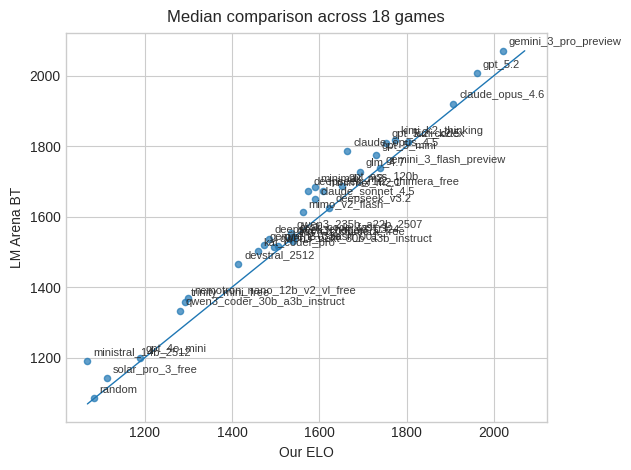

In [151]:
import numpy as np
import matplotlib.pyplot as plt

rating_df = pd.concat([v['leaderboard_table_df']['rating'].rename(k) for k, v in results.items()], axis=1)
rating_df['Median ELO'] = rating_df.median(axis=1, skipna=True)

xy = elos_with_rwins[["Median ELO"]].join(rating_df[["Median ELO"]], how="inner", lsuffix="_x", rsuffix="_y").dropna()
plt.scatter(xy["Median ELO_x"], xy["Median ELO_y"], s=20, alpha=0.7)

mn = np.nanmin([xy["Median ELO_x"].min(), xy["Median ELO_y"].min()])
mx = np.nanmax([xy["Median ELO_x"].max(), xy["Median ELO_y"].max()])
plt.plot([mn, mx], [mn, mx], linewidth=1)

for idx, r in xy.iterrows():
    plt.annotate(str(idx),(r["Median ELO_x"], r["Median ELO_y"]),xytext=(4, 4),textcoords="offset points",fontsize=8,alpha=0.9)

plt.xlabel("Our ELO")
plt.ylabel(f"LM Arena {rating_system.upper()}")
plt.title(f"Median comparison across {n_games} games", pad=8)
plt.tight_layout(); plt.show()


## heatmap for any game/world

In [16]:
from src.experimental.lm_arena import simple_example
import plotly.express as px

def display_world(game, world, results_dir, rating_system, num_bootstrap, exclude_tie, scale=1.9):
    r = simple_example.main_results(game, world, results_dir=results_dir, rating_system=rating_system, num_bootstrap=num_bootstrap, exclude_tie=exclude_tie)
    all_models = set(r['battles']['model_a']) | set(r['battles']['model_b'])
    row_beats_col = my_heatmap(r['battles'], all_models)

    model_order = sorted(r['elo_rating_final'].items(), key=lambda x: x[1], reverse=True)
    model_order = [x[0] for x in model_order]
    row_beats_col = row_beats_col.reindex(model_order, columns=model_order)
    row_beats_col = row_beats_col.rename(index=MODEL_NAME_MAP, columns=MODEL_NAME_MAP)
    fig = px.imshow(row_beats_col, color_continuous_scale="RdBu", text_auto=".1f", height=700 * scale, width=700 * scale)
    fig.update_layout(xaxis_title="Model B", yaxis_title="Model A", xaxis_side="top", title_y=0.07, title_x=0.5)
    fig.update_traces(hovertemplate="Model A: %{y}<br>Model B: %{x}<br>Fraction of A Wins: %{z}<extra></extra>")
    display(fig)

    def fmt(xs, timeout_count):
        # return f"{timeout_count}"
        if not xs:  # missing or empty
            return f"(0/{timeout_count})"
        x = np.asarray(xs, dtype=float)
        n = int(x.size)
        mean = x.mean()
        std = x.std(ddof=1) if n >= 2 else 0.0
        return f"{mean:.2f} ± {std:.2f} ({n}/{timeout_count})"

    error_turn_count = pd.Series(dtype=object)
    error_d, timeout_d = r["error_turn_count"]  # dict: model -> list[int]
    for m in model_order:
        error_turn_count[m] = fmt(error_d.get(m, []), timeout_d.get(m, 0))
    total_timeout = sum(r["error_turn_count"][1].values())
    total_timeout = 2 * total_timeout / r['leaderboard_table_df']['num_battles'].sum()  # fraction
    error_turn_count["Total"] = total_timeout
    error_turn_count.name = f"Error Turn Count"
    display(error_turn_count)

game = 'othello'
world = 'world1'
display_world(game, world, results_dir='results', rating_system='bt', num_bootstrap=100, exclude_tie=False)




Filtered 23460 matches to 5950 matches


Processing using <lambda>: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5950/5950 [00:00<00:00, 341144.83it/s]

Number of battles: 5950



  0%|                                                                                                                                                                                                                                       | 0/100 [00:00<?, ?it/s]/storage/ANON/projects/synthesis/arena/CA_arena/src/experimental/lm_arena/rating_systems.py:172: RuntimeWarning:

divide by zero encountered in log

/storage/ANON/projects/synthesis/arena/CA_arena/src/experimental/lm_arena/rating_systems.py:172: RuntimeWarning:

invalid value encountered in multiply

  4%|████████▉                                                                                                                                                                                                                      | 4/100 [00:00<00:09,  9.91it/s]/storage/ANON/projects/synthesis/arena/CA_arena/src/experimental/lm_arena/rating_systems.py:172: RuntimeWarning:

divide by zero encountered in log

/storage/ANON/projects/synth

gemini_3_pro_preview                           (0/0)
gpt_5.2                                        (0/0)
kimi_k2.5                                      (0/0)
claude_opus_4.6                                (0/0)
glm_5                            55.68 ± 4.13 (50/0)
claude_opus_4.5                                (0/5)
mimo_v2_flash                                  (0/0)
claude_sonnet_4.5                              (0/0)
deepseek_v3.2                                 (0/21)
grok_code_fast_1                              (0/17)
gpt_5_mini                                     (0/6)
gpt_5.2_codex                                  (0/4)
gemini_3_flash_preview                        (0/78)
glm_4.7                                        (0/0)
qwen3_coder                                    (0/0)
kimi_k2_thinking                             (0/133)
tng_r1t_chimera_free                           (0/0)
gpt_oss_120b                                   (0/0)
deepseek_r1t2_chimera_free                    

## quals

In [86]:
from pathlib import Path
pp = Path('results_quals_delete')
s = Path('results_quals')
s.mkdir(exist_ok=True)
for f in pp.glob('*.json'):
    print(f)
    print(f.name)
    namesplit = f.name.split('_')
    namesplit.pop(0)
    namesplit.pop(-1)
    namesplit.pop(-1)
    world = namesplit[-1]
    game_str = '_'.join(namesplit[:-1])
    print(game_str, world)
    with open(f, 'r') as ff:
        data = json.load(ff)
    n = data['pre_elimination_results']
    nn = {
        'match_results': n['match_results'],
        'error_logs': [n['error_logs']],
    }
    with open(s / f'matches_quals_{game_str}_{world}.json', 'w') as ff:
        json.dump(nn, ff, indent=2)


results_quals_delete/matches_mancala_world1_2346_0.json
matches_mancala_world1_2346_0.json
mancala world1
results_quals_delete/matches_go_world1_2346_0.json
matches_go_world1_2346_0.json
go world1
results_quals_delete/matches_checkers_world1_2346_0.json
matches_checkers_world1_2346_0.json
checkers world1
results_quals_delete/matches_clobber_world1_2346_0.json
matches_clobber_world1_2346_0.json
clobber world1
results_quals_delete/matches_connect4_world1_2346_0.json
matches_connect4_world1_2346_0.json
connect4 world1
results_quals_delete/matches_lines_of_action_world1_2346_0.json
matches_lines_of_action_world1_2346_0.json
lines_of_action world1
results_quals_delete/matches_backgammon_world1_2346_0.json
matches_backgammon_world1_2346_0.json
backgammon world1
results_quals_delete/matches_havannah_world1_2346_0.json
matches_havannah_world1_2346_0.json
havannah world1
results_quals_delete/matches_chess_worlduci1_2346_0.json
matches_chess_worlduci1_2346_0.json
chess worlduci1
results_quals_de

# Legacy

# Engine (OLD)

## Generate Data

In [ ]:
import time
import json
from datetime import datetime

from typing import Optional

from src.game_arena import utils
from src.game_arena import base
from src.game_arena import run_leaderboard
from src.game_arena.utils import setup_logging

logger = setup_logging("run_leaderboard_notebook.log", "run_leaderboard", to_stdout=True)

def main_leaderboard(
        game_str: str,
        world: str,
        n_games: int,
        timeout: int,
        save_results_dir: str,
        max_workers: int,
        inject_bots,
        seed: Optional[int] = None,
        quals_dir: Optional[str] = None,
        top_k_model_bots: Optional[int] = None,
        limit_model_bots: Optional[int] = None,
        skip_save_results: bool = False,
        model_blacklist: Optional[list[str]] = None,
        model_whitelist: Optional[list[str]] = None,
    ):
    logger.info(f'Starting leaderboard for game {game_str}, world {world}: n_games = {n_games}, timeout = {timeout}, max_workers = {max_workers}, seed = {seed}, quals_dir = {quals_dir}, top_k_model_bots = {top_k_model_bots}, skip_save_results = {skip_save_results}, model_blacklist = {model_blacklist}, model_whitelist = {model_whitelist}')
    game = utils.get_game(game_name=game_str)
    main_world = world
    if '&' in world:
        main_world = world.split('&')[0]
    config = utils.get_config_file(game_str, main_world)
    if '&' not in world:
        bots: list[BotPath] = list(utils.get_bot_paths_from_world(game_str, world, add_random=True, limit_model_bots=limit_model_bots).items())
    else:
        bots = []
        for world_part in world.split('&'):
            cur = list(utils.get_bot_paths_from_world(game_str, world_part, add_random=True, limit_model_bots=limit_model_bots).items())
            cur = [(f'{world_part}:{bot_name}', bot_path) for bot_name, bot_path in cur]
            bots.extend(cur)
    print(f'n bots = {len(bots)}')
    assert len(bots) > 1, f'Need at least 2 bots to run a leaderboard. Got {len(bots)} bots. in game {game_str}, world {world}'
    def game_creator():
        return game(config)
    game_creator.__name__ = game.__name__

    if model_blacklist is not None:
        pre_filtered_len = len(bots)
        print('model_blacklist', model_blacklist)
        print('bots', set([b[0].split('/')[0] for b in bots]))
        bots = [b for b in bots if b[0].split('/')[0] not in model_blacklist]
        print(f'pre-blacklisting #bots = {pre_filtered_len}, post-blacklisting #bots = {len(bots)}')

    if model_whitelist is not None:
        pre_filtered_len = len(bots)
        bots = [b for b in bots if b[0].split('/')[0] in model_whitelist]
        print(f'pre-whitelisting #bots = {pre_filtered_len}, post-whitelisting #bots = {len(bots)}')

    pre_filtered_len = len(bots)
    qual_bot_names = None
    if quals_dir is not None:
        assert top_k_model_bots is not None, "top_k_model_bots is required when quals_json is provided"
        quals_json = utils.get_root_path() / Path(quals_dir) / f'matches_quals_{game_str}_{world}.json'
        assert quals_json.exists(), f"Quals JSON file not found {quals_json}"
        with open(quals_json, 'r') as f:
            quals_data = json.load(f)
        ci_rankings = quals_data['ci_rankings']
        qual_bot_names = set(['random'])
        for model_name, rankings in ci_rankings.items():
            qual_bots_sorted = sorted(rankings, key=lambda x: x['rating'] if x.get('rating') is not None else 0, reverse=True)
            top_k_bot_names = [e['bot'] for e in qual_bots_sorted[:top_k_model_bots]]
            qual_bot_names.update(top_k_bot_names)
        bots = [b for b in bots if b[0] in qual_bot_names]
        del quals_data
    post_filtered_len = len(bots)
    print(f'pre-filtered #bots = {pre_filtered_len}, post-filtered #bots = {post_filtered_len}')

    run_config = {'game_str': game_str, 'world': world, 'timeout': timeout, 'seed': seed}
    final_result_path = utils.get_root_path() / Path(save_results_dir) / f'matches_{game_str}_{world}.json'
    global_results = run_leaderboard._load_previous_results(final_result_path, run_config, qual_bot_names)
    todo = run_leaderboard._build_todo_with_resume_A_vs_B(inject_bots, bots, n_games, global_results.get('match_results', []))
    print(f'game = {game_str}, world = {world}, len(todo) = {len(todo)}')
    if len(todo) == 0:
        print('No games to play. Exiting.')
        return
    cur_id = datetime.now().strftime('%Y_%m_%d_%H_%M_%S')
    start_time = time.time()
    logger.info(f'game = {game_str}, world = {world}, #pre-filtered bots = {pre_filtered_len}, #post-filtered bots = {post_filtered_len}, #todo = {len(todo)}, n_games = {n_games}, timeout = {timeout}, max_workers = {max_workers}. start time: {start_time}. {cur_id}')
    print('TRUE TOURNAMENT:')

    result = base.play_all_2p_games(
        game,
        config,
        todo,
        seed=seed,
        timeout=timeout,
        max_workers=max_workers,
    )
    global_results['match_results'].extend(result)

    elapsed_time = time.time() - start_time
    logger.info(f'done playing all games {game_str}, world = {world}. elapsed minutes: {elapsed_time / 60:.2f}. {cur_id}')

    if skip_save_results:
        print('skipping saving results')
        return
    final_result_path.parent.mkdir(parents=True, exist_ok=True)
    with open(final_result_path, 'w') as f:
        json.dump(global_results, f, indent=2)



### chess

In [ ]:
from src.heuristic.chess_01.play_heuristic_vs_bot import _load_passthrough_policy, _load_heuristic_policy
# from src.heuristic.chess_02.play_sunfish_vs_random import _load_sunfish_policy
to_inject = [
    # ('github_0_star', _load_passthrough_policy()),
    # ('github_0_star_modified', _load_heuristic_policy()),
    ('sunfish', Path('src/heuristic/chess_02/passthrough.py')),
]
model_blacklist, model_whitelist = run_leaderboard.get_model_blacklist_whitelist('src/experimental/model_ignore.json', None, None, None)

main_leaderboard(
    game_str='chess',
    world='worlduci1',
    n_games=10,
    timeout=20,
    limit_model_bots=5,
    max_workers=32,
    inject_bots=to_inject,
    save_results_dir='results_side_experiments/results_heuristic/new',
    model_whitelist=model_whitelist,
    model_blacklist=model_blacklist,
)

2026-02-22 03:39:45,647 - run_leaderboard - INFO - 1618869394.py:30 - Starting leaderboard for game chess, world worlduci1: n_games = 10, timeout = 20, max_workers = 32, seed = None, quals_dir = None, top_k_model_bots = None, skip_save_results = False, model_blacklist = ['claude_sonnet_4', 'gemini_2.5_flash', 'gpt_5.2_pro', 'deepseek_v3.2_speciale'], model_whitelist = None


n bots = 171
model_blacklist ['claude_sonnet_4', 'gemini_2.5_flash', 'gpt_5.2_pro', 'deepseek_v3.2_speciale']
bots {'glm_4.7', 'nemotron_nano_12b_v2_vl_free', 'minimax_m2', 'claude_sonnet_4.5', 'gemini_3_pro_preview', 'devstral_2512', 'glm_5', 'claude_opus_4.6', 'mimo_v2_flash', 'deepseek_chat_v3_0324', 'qwen3_32b', 'qwen3_coder_30b_a3b_instruct', 'gemini_3_flash_preview', 'gpt_oss_120b', 'tng_r1t_chimera_free', 'ministral_14b_2512', 'deepseek_v3.2', 'gpt_5_mini', 'qwen3_coder', 'gpt_5.2_codex', 'gpt_5.2', 'qwen3_next_80b_a3b_instruct', 'claude_opus_4.5', 'gemini_2.0_flash_001', 'random', 'kimi_k2.5', 'kimi_k2_thinking', 'solar_pro_3_free', 'grok_code_fast_1', 'deepseek_r1t2_chimera_free', 'trinity_mini_free', 'gpt_4o_mini', 'qwen3_235b_a22b_2507', 'kat_coder_pro', 'minimax_m2.1'}
pre-blacklisting #bots = 171, post-blacklisting #bots = 171
pre-filtered #bots = 171, post-filtered #bots = 171
2026-02-22 03:39:46,223 - run_leaderboard - INFO - run_leaderboard.py:241 - loading existing res

Creating futures, this should only take a few seconds: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3320/3320 [00:00<00:00, 40307.32it/s]


Output()

2026-02-22 04:11:11,660 - run_leaderboard - INFO - 1618869394.py:105 - done playing all games chess, world = worlduci1. elapsed minutes: 31.42. 2026_02_22_03_39_46


### checkers

In [ ]:
# need to:
# pip install loguru
# pip install uvicorn
# pip install fastapi
from src.heuristic.checkers_01.play_draughts_vs_random import _load_draughts_policy
to_inject = [
    # ('github_0_star', _load_passthrough_policy()),
    # ('github_0_star_modified', _load_heuristic_policy()),
    ('alpha_beta', Path('src/heuristic/checkers_01/passthrough.py')),
]
model_blacklist, model_whitelist = run_leaderboard.get_model_blacklist_whitelist('src/experimental/model_ignore.json', None, None, None)

main_leaderboard(
    game_str='checkers',
    world='world1',
    n_games=10,
    timeout=4,
    limit_model_bots=5,
    max_workers=32,
    inject_bots=to_inject,
    save_results_dir='results_side_experiments/results_heuristic/new',
    model_whitelist=model_whitelist,
    # model_whitelist=['gpt_5_mini'],
    # model_whitelist=['glm_5'],
    model_blacklist=model_blacklist,
)


2026-02-22 21:35:09,129 - run_leaderboard - INFO - 1618869394.py:30 - Starting leaderboard for game checkers, world world1: n_games = 10, timeout = 4, max_workers = 32, seed = None, quals_dir = None, top_k_model_bots = None, skip_save_results = False, model_blacklist = ['gpt_5.2_pro', 'deepseek_v3.2_speciale', 'claude_sonnet_4', 'gemini_2.5_flash'], model_whitelist = None
n bots = 173
model_blacklist ['gpt_5.2_pro', 'deepseek_v3.2_speciale', 'claude_sonnet_4', 'gemini_2.5_flash']
bots {'mimo_v2_flash', 'glm_4.7', 'grok_code_fast_1', 'gpt_5.2_pro', 'devstral_2512', 'minimax_m2', 'qwen3_32b', 'deepseek_v3.2', 'gpt_5.2', 'kimi_k2.5', 'qwen3_next_80b_a3b_instruct', 'gpt_oss_120b', 'gpt_5_mini', 'gemini_2.0_flash_001', 'deepseek_v3.2_speciale', 'nemotron_nano_12b_v2_vl_free', 'gpt_4o_mini', 'deepseek_chat_v3_0324', 'claude_opus_4.6', 'kat_coder_pro', 'ministral_14b_2512', 'trinity_mini_free', 'kimi_k2_thinking', 'glm_5', 'gemini_3_flash_preview', 'minimax_m2.1', 'qwen3_coder_30b_a3b_instruc

Creating futures, this should only take a few seconds: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3420/3420 [00:00<00:00, 32859.65it/s]

Output()

2026-02-22 21:57:03,670 - run_leaderboard - INFO - 1618869394.py:105 - done playing all games checkers, world = world1. elapsed minutes: 21.90. 2026_02_22_21_35_09


## leaderboard

In [3]:
def hacky_fix_augmented(game_str, aug_data):
    if game_str == 'checkers':
        # remove any matches that have the error message
        to_find = 'No intersection between engine moves and legal moves'
        old_aug_data = aug_data
        aug_data = []
        for g in old_aug_data:
            if g['r'] is not None and to_find not in g['r'].get('exception', ''):
                aug_data.append(g)
        print(f'removed {len(old_aug_data) - len(aug_data)} matches with error message: {to_find}')
    return aug_data

gs = [
    ['chess', 'worlduci1', 'results_side_experiments/results_heuristic/matches_chess_worlduci1_2080_5.json', 'results_side_experiments/results_heuristic/matches_chess_worlduci1_feb_22_sunfish-depth-5.json', 'Chess'],
    # ['checkers', 'world1', 'results_side_experiments/results_heuristic/matches_checkers_world1_2080_5.json', 'results_side_experiments/results_heuristic/matches_checkers_world1_153_5.json', 'Checkers'],

    # ['checkers', 'world1', 'results_side_experiments/results_heuristic/matches_checkers_world1_2080_5.json', 'results_side_experiments/results_heuristic/new/matches_checkers_world1_feb_22.json', 'Checkers'],
    # ['checkers', 'world1', 'results_current/results_somerset_1/tourney/matches_checkers_world1.json', 'results_side_experiments/results_heuristic/new/matches_checkers_world1_feb_22.json', 'Checkers'],
    ['checkers', 'world1', 'results_current/results_somerset_feb_20/tourney/matches_checkers_world1.json', 'results_side_experiments/results_heuristic/new/matches_checkers_world1.json', 'Checkers'],

    # ['chess', 'worlduci1', 'results_side_experiments/results_heuristic/matches_chess_worlduci1_2080_5.json', 'results_side_experiments/results_heuristic/matches_chess_world1_456_5.json', 'Chess'],
    # ['chess', 'worlduci1', 'results_current/results_somerset_1/tourney/matches_chess_worlduci1.json', 'results_side_experiments/results_heuristic/a/matches_chess_worlduci1_feb_21.json', 'Chess'],
    # ['checkers', 'world1', None, None, 'Checkers'],
]
elos = []
raw_match_data = {}
top_bot_ids = {}
for game_str, world, match_json, aug_json, colname in gs:
    print(f'{game_str} {world}')
    all_data_pruned = get_match_results(match_json)
    if aug_json is not None:
        aug_data = get_match_results(aug_json)
        aug_data = hacky_fix_augmented(game_str, aug_data)
    else:
        aug_data = []

    # to_remove = [m for m in aug_data if m['winner'] is None and (m['name0'] == 'sunfish' or m['name1'] == 'sunfish')]  # remove draws
    # print('removing', len(to_remove), 'matches due to draws with sunfish')
    # aug_data = [m for m in aug_data if m not in to_remove]

    print(f'{game_str} {world} {len(all_data_pruned)}, aug: {len(aug_data)}')
    elo_pre, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='top_1', verbose=False)
    top_models_names = set(top_models)
    top_bot_ids[colname] = top_models_names
    all_data_pruned = [g for g in all_data_pruned if g['name0'] in top_models_names and g['name1'] in top_models_names]
    all_data_pruned.extend(aug_data)
    for g in all_data_pruned:
        g['fullname0'] = g['name0']
        g['fullname1'] = g['name1']
        g['name0'] = g['name0'].split('/')[0]
        g['name1'] = g['name1'].split('/')[0]
        g['name0'] = NAME_FIX_MAP.get(g['name0'], g['name0'])
        g['name1'] = NAME_FIX_MAP.get(g['name1'], g['name1'])
    all_data_pruned = [g for g in all_data_pruned if g['name0'] not in NAME_DELETE and g['name1'] not in NAME_DELETE]

    raw_match_data[colname] = all_data_pruned
    elo_post, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='none', verbose=False)
    elos.append(elo_post)

for i in range(len(elos)):
    elos[i] = elos[i].astype(float)


chess worlduci1
chess worlduci1 20800, aug: 3420
LEGACY {'name0': 'qwen3_coder/002', 'name1': 'gpt_5.2_codex/003', 'winner': 'timeout', 'done': False, 'r': None, 'exception': 'Game execution exceeded timeout of 20 seconds', 'exception_traceback': 'Traceback (most recent call last):\n  File "/storage/ANON/projects/synthesis/arena/CA_arena/src/game_arena/base.py", line 201, in play_game_with_timeout\n    raise TimeoutError(f"Game execution exceeded timeout of {timeout} seconds")\nTimeoutError: Game execution exceeded timeout of 20 seconds\n', 'time_analysis': {'1': 19.85220193862915, '0': 0.305084228515625, 'last': ['1', 0.2071974277496338]}, 'now': 20.395103693008423}
LEGACY {'name0': 'gpt_5.2_codex/003', 'name1': 'qwen3_coder/002', 'winner': 'timeout', 'done': False, 'r': None, 'exception': 'Game execution exceeded timeout of 20 seconds', 'exception_traceback': 'Traceback (most recent call last):\n  File "/storage/ANON/projects/synthesis/arena/CA_arena/src/game_arena/base.py", line 201

In [4]:
from src.experimental.lm_arena.simple_example import main_results
results = {}
for game_str, world, match_json, aug_json, colname in gs:
    print(f'{game_str} {world}')
    all_data_pruned = get_match_results(match_json)
    if aug_json is not None:
        aug_data = get_match_results(aug_json)
        aug_data = hacky_fix_augmented(game_str, aug_data)
    else:
        aug_data = []
    # TYPE A (full bot)
    # all_data_pruned.extend(aug_data)

    # TYPE B (mix)
    all_data_pruned.extend(aug_data)
    for m in all_data_pruned:
        m['name0'] = m['name0'].split('/')[0]
        m['name1'] = m['name1'].split('/')[0]
        m['name0'] = NAME_FIX_MAP.get(m['name0'], m['name0'])
        m['name1'] = NAME_FIX_MAP.get(m['name1'], m['name1'])


    results[colname] = main_results(all_data_pruned, rating_system='bt', exclude_tie=False, num_cpu=1, seed=42, only_model=False)



chess worlduci1
Filtered 24220 matches to 24220 matches


Processing using <lambda>: 100%|██████████| 24220/24220 [00:00<00:00, 99453.75it/s] 


Number of battles: 24220


100%|██████████| 100/100 [00:07<00:00, 13.88it/s]


checkers world1
removed 1 matches with error message: No intersection between engine moves and legal moves
Filtered 50339 matches to 50339 matches


Processing using <lambda>: 100%|██████████| 50339/50339 [00:00<00:00, 105572.97it/s]


Number of battles: 50339


100%|██████████| 100/100 [00:03<00:00, 25.90it/s]


In [5]:
# for i, (k, v) in enumerate(results['Checkers'].items()):
#     if i < 3:
#         continue
#     display(k)
#     display(v)

elos = []
for k in results:
    elos.append(pd.DataFrame(results[k]['leaderboard_table_df']['rating']).rename(columns={'rating': 'ELO'}))
# results['Checkers']['leaderboard_table_df']['rating'].sort_values(ascending=False)

In [10]:
colname = 'Chess'
# colname = 'Checkers'
matches = raw_match_data[colname]
print(top_bot_ids[colname])
all_scores_df = run_leaderboard.get_scores_from_match_data(matches)
all_scores_df['total_matches'] = all_scores_df.sum(axis=1)

elos_df = pd.concat(elos, axis=1)
elos_df.columns = [n for _,_,_,_,n in gs]
df = pd.concat([all_scores_df, elos_df[colname].rename('ELO')], axis=1).round().astype("Int64")
df.sort_values('ELO', ascending=False, inplace=True)
df

{'minimax_m2/001', 'glm_4.7/004', 'qwen3_coder_30b_a3b_instruct/005', 'deepseek_chat_v3_0324/005', 'gemini_3_pro_preview/001', 'minimax_m2.1/002', 'kimi_k2.5/002', 'devstral_2512_free/001', 'gpt_4o_mini/004', 'deepseek_v3.2/003', 'kat_coder_pro/002', 'nemotron_nano_12b_v2_vl_free/005', 'qwen3_next_80b_a3b_instruct/001', 'qwen3_235b_a22b_2507/005', 'gemini_2.0_flash_001/004', 'gpt_5.2_codex/004', 'claude_sonnet_4.5/002', 'gpt_5.2/002', 'qwen3_coder/002', 'deepseek_r1t2_chimera_free/003', 'grok_code_fast_1/003', 'claude_opus_4.5/002', 'ministral_14b_2512/001', 'gpt_oss_120b/002', 'kimi_k2_thinking/002', 'mimo_v2_flash_free/001', 'trinity_mini_free/004', 'tng_r1t_chimera_free/005', 'gemini_3_flash_preview/003', 'random', 'gpt_5_mini/003', 'qwen3_32b/005', 'solar_pro_3_free/001'}


,win,loss,draw,error,timeout,enemy_error,enemy_timeout,total_matches,ELO
sunfish,1144,0,70,0,2,2129,75,3420,2525
claude_opus_4.6,0,62,24,12,0,0,2,100,2210
claude_opus_4.5,86,70,55,20,20,129,40,420,1954
gpt_5.2,88,84,82,3,5,109,49,420,1863
gemini_3_pro_preview,58,114,110,2,0,106,30,420,1861
kimi_k2_thinking,40,87,120,40,0,106,27,420,1830
kimi_k2.5,28,79,166,0,20,102,25,420,1810
gpt_5_mini,104,60,12,40,75,103,26,420,1809
claude_sonnet_4.5,13,135,107,20,0,114,31,420,1777
qwen3_coder,26,81,91,75,0,125,22,420,1754


In [7]:
elos_df = pd.concat(elos, axis=1)
elos_df.columns = [n for _,_,_,_,n in gs]
# elos_df['Median ELO'] = elos_df.fillna(-9999).median(axis=1, skipna=False).round(2)
# elos_df['Mean ELO'] = elos_df.fillna(0).mean(axis=1).round(2)
# elos_df = elos_df.sort_values('Median ELO', ascending=False)
# # elos_df = elos_df.sort_values('Mean ELO', ascending=False)
# # elos_df = elos_df.sort_values('Lines of Action ELO', ascending=False)
# # elos_df = elos_df.sort_values('3D Tic Tac Toe ELO', ascending=False)
# elos_with_rwins = elos_df.copy()
# for game_str, _, _, _, colname in gs:
#     if colname in elos_with_rwins.columns:
#         elos_with_rwins[colname] = elos_with_rwins[colname].astype(str)
#         for model in elos_with_rwins.index:
#             elo = elos_df.at[model, colname]
#             if pd.notnull(elo):
#                 elo_str = f"{int(round(elo))}"
#             else:
#                 elo_str = 'nan'
#             elos_with_rwins.at[model, colname] = f"{elo_str}"
# if "Median ELO" in elos_with_rwins.columns:
#     elos_with_rwins["Median ELO"] = elos_df["Median ELO"].round(0)
# with pd.option_context('display.max_rows', None, 'display.max_columns', None):
#     display(elos_with_rwins)

In [ ]:
for m in matches:
    if m['r'] is None:
        continue
    if (m['name0'] == 'sunfish' and m['winner'] != 0 and m['r']['player_err_counts'][0] == 1) or (m['name1'] == 'sunfish' and m['winner'] != 1 and m['r']['player_err_counts'][1] == 1):
        print(m)
        print(m['r']['exception_traceback'])


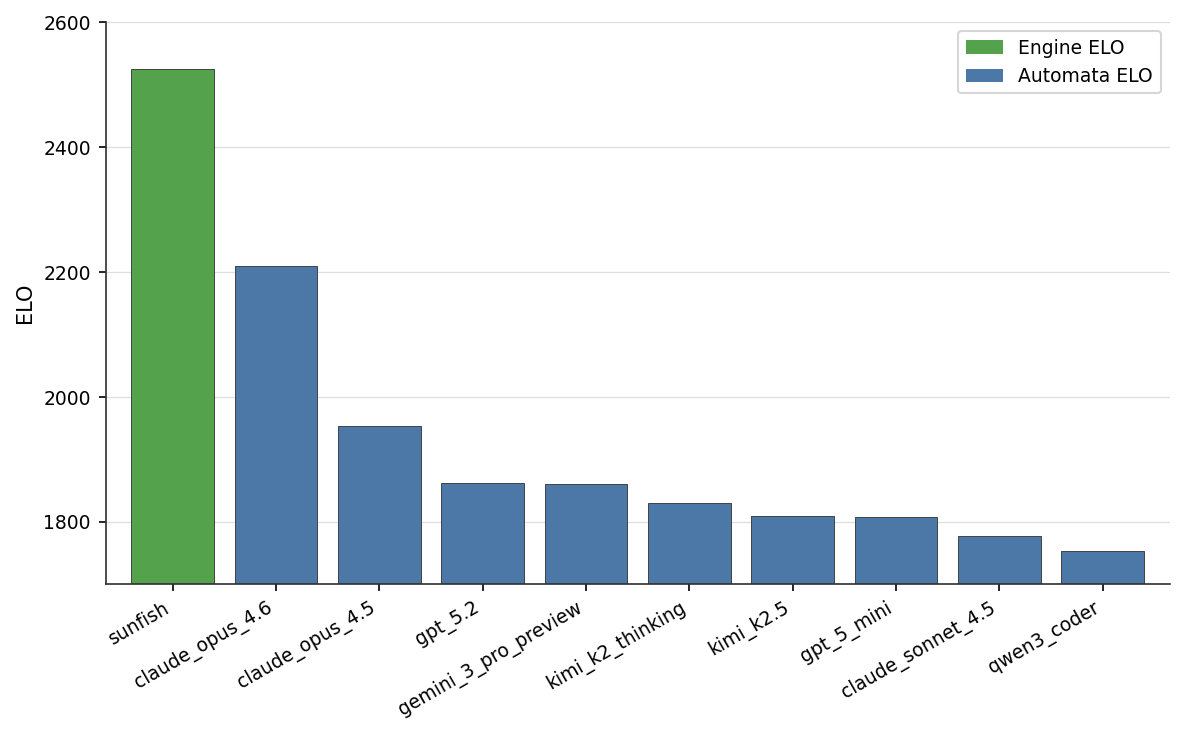

In [8]:
df = elos[0].copy()
df = df[~df.index.str.contains('github')]
df = df.nlargest(10, "ELO")
df = df.sort_values("ELO", ascending=False)

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "axes.edgecolor": "#2f2f2f",
    "axes.linewidth": 0.8,
    "grid.color": "#d0d0d0",
    "grid.linewidth": 0.6,
    "grid.alpha": 0.7,
})

engine_color = "#54A24B"
auto_color = "#4C78A8"

ax = df.plot.bar(
    figsize=(8, 5),
    width=0.8,
    color=auto_color,  # default
    edgecolor="#2f2f2f",
    linewidth=0.4,
)

# recolor just the engine bar
for patch, name in zip(ax.patches, df.index):
    if name == "sunfish":
        patch.set_facecolor(engine_color)

ax.set_ylabel("ELO")
ax.set_xlabel("")
ax.grid(axis="y")
ax.set_axisbelow(True)

for s in ["top", "right"]:
    ax.spines[s].set_visible(False)

ax.set_ylim(df["ELO"].min() * 0.97, df["ELO"].max() * 1.03)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")

from matplotlib.patches import Patch
ax.legend(
    handles=[
        Patch(facecolor=engine_color, label="Engine ELO"),
        Patch(facecolor=auto_color, label="Automata ELO"),
    ],
)

plt.tight_layout()
plt.show()
# out_pdf = "figures/engine_chess.pdf"
# fig = ax.get_figure()
# fig.savefig(out_pdf, format="pdf", bbox_inches="tight")


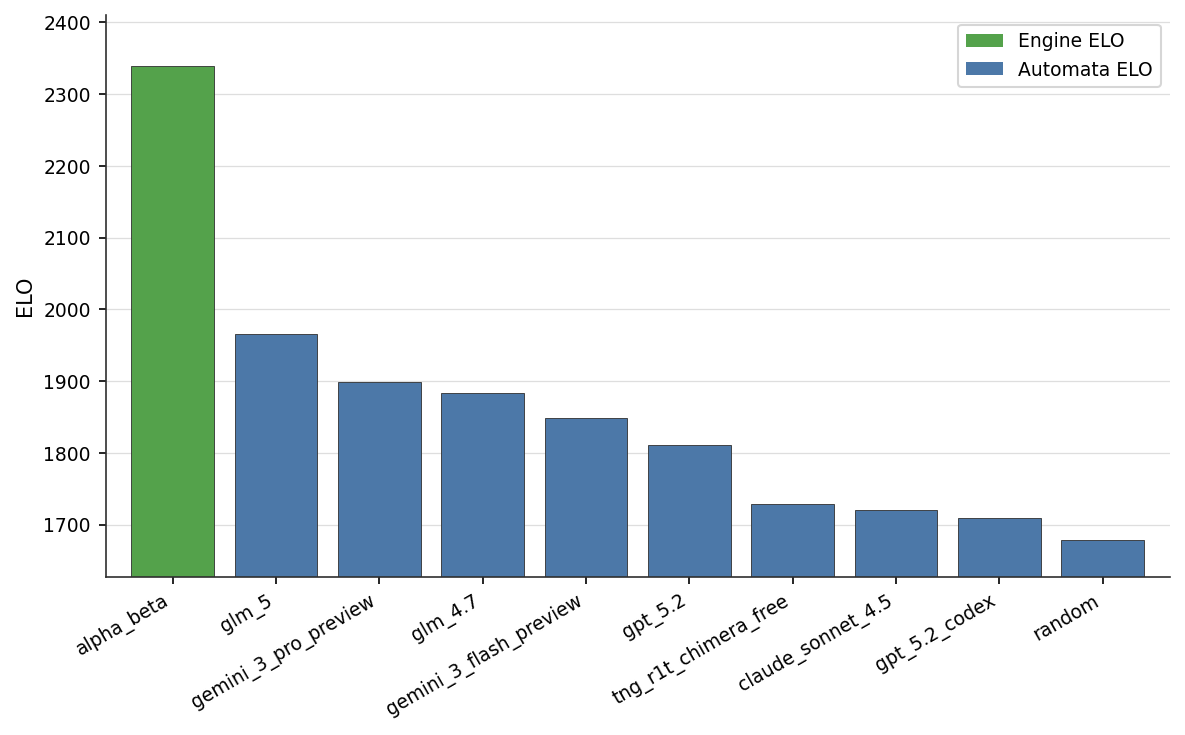

In [9]:
df = elos[1].copy()
df = df[~df.index.str.contains('github')]
df = df.nlargest(10, "ELO")
df = df.sort_values("ELO", ascending=False)

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "axes.edgecolor": "#2f2f2f",
    "axes.linewidth": 0.8,
    "grid.color": "#d0d0d0",
    "grid.linewidth": 0.6,
    "grid.alpha": 0.7,
})

engine_color = "#54A24B"
auto_color = "#4C78A8"

ax = df.plot.bar(
    figsize=(8, 5),
    width=0.8,
    color=auto_color,  # default
    edgecolor="#2f2f2f",
    linewidth=0.4,
)

# recolor just the engine bar
for patch, name in zip(ax.patches, df.index):
    if name == "alpha_beta":
        patch.set_facecolor(engine_color)

ax.set_ylabel("ELO")
ax.set_xlabel("")
ax.grid(axis="y")
ax.set_axisbelow(True)

for s in ["top", "right"]:
    ax.spines[s].set_visible(False)

ax.set_ylim(df["ELO"].min() * 0.97, df["ELO"].max() * 1.03)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")

from matplotlib.patches import Patch
ax.legend(
    handles=[
        Patch(facecolor=engine_color, label="Engine ELO"),
        Patch(facecolor=auto_color, label="Automata ELO"),
    ],
)

plt.tight_layout()
plt.show()
# out_pdf = "figures/engine_checkers.pdf"
# fig = ax.get_figure()
# fig.savefig(out_pdf, format="pdf", bbox_inches="tight")


# Memory vs No Memory (OLD)

## Generate combined world

In [ ]:
game_str = 'go'
# game_str = 'chess'
world_no_mem = 'world1'
# world_no_mem = 'worlduci1'
world_mem = 'worldmem1'
# world_mem = 'worlducimem1'

all_data_pruned = get_match_results(game_str, world_no_mem, get_matches_filename(game_str, world_no_mem))
_, top_models_nomem = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='top_1', verbose=False)

all_data_pruned = get_match_results(game_str, world_mem, get_matches_filename(game_str, world_mem))
_, top_models_mem = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='top_1', verbose=False)


NameError: name 'get_matches_filename' is not defined

In [ ]:
limit_model_bots = 5
n_games = 1
timeout = 20
max_workers = 32

config = utils.get_config_file(game_str, world_no_mem)
all_bots = []

bots = list(utils.get_bot_jsons_from_world(game_str, world_no_mem, add_random=True, limit_model_bots=limit_model_bots).items())
print('world1 pre filter', len(bots))
bots = [b for b in bots if b[0] in top_models_nomem]
bots = [(f'nomem:{bot_name}', policy) for bot_name, policy in bots]
print('world1 post filter', len(bots))
all_bots.extend(bots)

bots = list(utils.get_bot_jsons_from_world(game_str, world_mem, add_random=True, limit_model_bots=limit_model_bots).items())
print('worldmem1 pre filter', len(bots))
bots = [b for b in bots if b[0] in top_models_mem or b[0].startswith('deepseek_v3.2_speciale')]
bots = [(f'mem:{bot_name}', policy) for bot_name, policy in bots]
print('worldmem1 post filter', len(bots))
all_bots.extend(bots)


todo = []
for asdf, p1 in enumerate(all_bots):
    for p2 in all_bots[asdf+1:]:
        todo.append((p1, p2))
print('len todo', len(todo))
assert len(todo) > 0, 'No games to play. Exiting.'


world1 pre filter 153
world1 post filter 33
worldmem1 pre filter 154
worldmem1 post filter 34
len todo 2211


In [ ]:
game = utils.get_game(game_str)
def game_creator():
    return game(config)
game_creator.__name__ = game.__name__

final_result_path = utils.get_root_path() / 'results_memory' / f'matches_{game_str}_{world_mem}_{len(todo)}_{n_games}.json'
print(f'game = {game_str}, world = {world_mem}, len(todo) = {len(todo)}')
result = base.play_all_2p_games(game_creator, todo, n_games=n_games, timeout=timeout, verbose=False, max_workers=max_workers)

final_result_path.parent.mkdir(parents=True, exist_ok=True)
with open(final_result_path, 'w') as f:
    json.dump(result, f, indent=2)


In [ ]:
final_result_path.parent.mkdir(parents=True, exist_ok=True)
with open(final_result_path, 'w') as f:
    json.dump(result, f, indent=2)


## Plot

In [ ]:
gs = [
    # ['go', 'world1', None, 'Go'],
    # ['go', 'worldmem1', None, 'Go W/Memory'],
    # ['go', 'worldmem1', Path('results_memory/matches_go_worldmem1_2016_1.json'), 'Go Comparison'],
    # ['go', 'worldmem1', Path('results_memory/matches_go_worldmem1_2211_1.json'), 'Go Comparison'],
    # ['chess', 'worldmem1', Path('results_memory/matches_chess_worldmem1_1953_1.json'), 'Chess Comparison'],
    ['chess', 'worlducimem1', Path('results_memory/matches_chess_worlducimem1_1891_1.json'), 'Chess UCI Comparison'],
]

elos_mem = []
elos_mem_colnames = []
elos_mem_done_count = {}
elos_mem_raw_match_data = {}
elos_mem_top_bots = {}
total_num_games = 0
NAME_FIX = {
    'mem:random': 'random',
    'nomem:random': 'random',
}
for game_str, world, match_json, colname in gs:
    if match_json is None:
        try:
            match_json = get_matches_filename(game_str, world)
        except Exception as e:
            print(f'ERROR ERROR ERROR {game_str} {world}: {e}')
            continue
    all_data_pruned = get_match_results(match_json)
    elos_mem_raw_match_data[colname] = copy.deepcopy(all_data_pruned)
    # elos_mem_raw_match_data[colname] = all_data_pruned
    num_games = len(all_data_pruned)
    print(f'{game_str} {world} {len(all_data_pruned)}')
    total_num_games += num_games

    elo_pre, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='top_1', verbose=False, learning_rate=4, iters=500)
    elos_mem_top_bots[colname] = top_models
    top_models_names = set(top_models)
    all_data_pruned = [g for g in all_data_pruned if g['name0'] in top_models_names and g['name1'] in top_models_names]
    for g in all_data_pruned:
        g['name0'] = g['name0'].split('/')[0]
        g['name1'] = g['name1'].split('/')[0]
        g['name0'] = NAME_FIX.get(g['name0'], g['name0'])
        g['name1'] = NAME_FIX.get(g['name1'], g['name1'])
    elo_post, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='none', verbose=False, learning_rate=4, iters=500)
    if 'Comparison' not in colname:
        elos_mem.append(elo_post)
        elos_mem_colnames.append(colname)
    else:
        # need to split into two columns
        nomem_df = elo_post[elo_post.index.str.startswith('nomem:')].rename(index=lambda x: x.replace('nomem:', '', 1))
        nomem_df.loc['random'] = elo_post.loc['random']
        mem_df   = elo_post[elo_post.index.str.startswith('mem:')].rename(index=lambda x: x.replace('mem:', '', 1))
        mem_df.loc['random'] = elo_post.loc['random']
        elos_mem.append(nomem_df)
        elos_mem.append(mem_df)
        elos_mem_colnames.append(colname + ' No Memory')
        elos_mem_colnames.append(colname + ' With Memory')

    elos_mem_done_count[colname] = get_done_count(all_data_pruned)

print('total games =', total_num_games)
for asdf in range(len(elos_mem)):
    elos_mem[asdf] = elos_mem[asdf].astype(float)
elos_mem_df = pd.concat(elos_mem, axis=1)
elos_mem_df.columns = elos_mem_colnames
elos_mem_df = elos_mem_df[(elos_mem_df.index != 'gpt_5.2_pro') & (elos_mem_df.index != 'deepseek_v3.2_speciale')]
# elos_mem_df = elos_mem_df[(elos_mem_df.index != 'gpt_5.2_pro')]
elos_mem_top_bots

chess worlducimem1 3782
total games = 3782


{'Chess UCI Comparison': Index(['mem:claude_opus_4.5/001', 'nomem:gpt_5.2/002', 'mem:gpt_5_mini/003',
        'mem:kimi_k2_thinking/002', 'nomem:gpt_5_mini/003',
        'nomem:claude_opus_4.5/002', 'mem:gpt_5.2/001',
        'nomem:gemini_3_pro_preview/001', 'nomem:deepseek_chat_v3_0324/005',
        'mem:minimax_m2/004', 'nomem:gpt_5.2_codex/003',
        'nomem:kimi_k2_thinking/004', 'mem:claude_sonnet_4.5/002',
        'mem:glm_4.7/001', 'nomem:qwen3_coder/002',
        'mem:deepseek_r1t2_chimera_free/003', 'mem:gemini_3_pro_preview/004',
        'mem:gemini_3_flash_preview/005', 'nomem:claude_sonnet_4.5/002',
        'mem:deepseek_chat_v3_0324/004', 'nomem:mimo_v2_flash_free/001',
        'nomem:qwen3_235b_a22b_2507/003', 'mem:minimax_m2.1/002',
        'nomem:minimax_m2.1/002', 'nomem:deepseek_r1t2_chimera_free/003',
        'mem:gpt_oss_120b/002', 'mem:qwen3_235b_a22b_2507/002',
        'mem:gpt_5.2_codex/002', 'nomem:tng_r1t_chimera_free/004',
        'mem:mimo_v2_flash_free/00

In [ ]:
# ms = [m for m in elos_mem_raw_match_data['Go Comparison'] if m['name0'].startswith('mem:deepseek_v3.2_speciale') or m['name1'].startswith('mem:deepseek_v3.2_speciale')]
ms = [m for m in elos_mem_raw_match_data['Go Comparison'] if m['name0'] == 'mem:deepseek_v3.2_speciale' or m['name1'] == 'mem:deepseek_v3.2_speciale']
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(pd.DataFrame(ms))


""


In [ ]:
print('WIN/LOSS/DRAW/ERROR/TIMEOUT breakdown for a game:')
colname = 'Go Comparison'
all_scores_df = run_leaderboard.get_scores_from_match_data(elos_mem_raw_match_data[colname])
all_scores_df['total'] = all_scores_df.sum(1)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(all_scores_df.loc[all_scores_df.index.str.contains('ministr')].sort_values('win', ascending=False))


WIN/LOSS/DRAW/ERROR/TIMEOUT breakdown for a game:


/tmp/ipykernel_719977/4064341317.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  all_scores_df['total'] = all_scores_df.sum(1)


,win,loss,draw,error,timeout,enemy_error,enemy_timeout,total
mem:ministral_14b_2512/004,2,1,1,120,0,2,2,128
nomem:ministral_14b_2512/004,0,0,0,115,0,10,3,128


In [ ]:
elos_mem_df

,Go Comparison No Memory,Go Comparison With Memory
gpt_5.2_codex,2027.63,1740.27
kimi_k2_thinking,1841.08,1555.60
gpt_5.2,1786.74,1977.94
gemini_3_pro_preview,1780.17,1806.30
kat_coder_pro,1732.08,1359.92
gpt_5_mini,1716.41,1798.60
minimax_m2,1704.59,1652.17
qwen3_32b,1701.87,1545.03
gpt_oss_120b,1696.36,1773.39
trinity_mini_free,1652.81,1510.33


/tmp/ipykernel_719977/757242155.py:10: Pandas4Warning: Starting with pandas version 4.0 all arguments of median will be keyword-only.
  df = df.loc[df.median(1).sort_values(ascending=False).index]


With Memory = 1629.1, No Memory = 1606.4


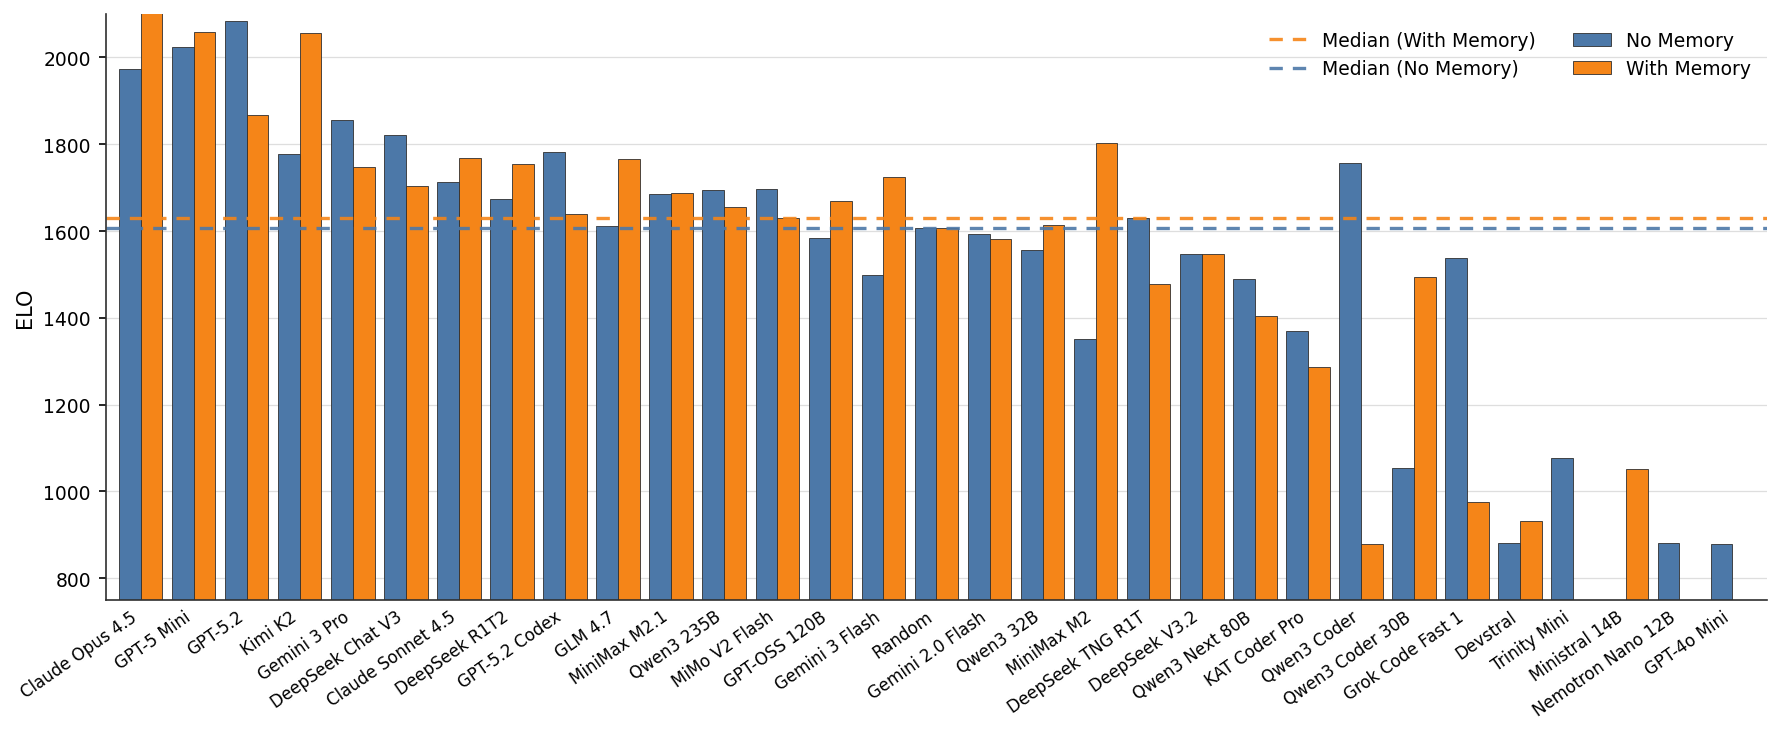

In [ ]:
# game_str = 'Chess'
# title = f'Chess SAN (with legal moves) Automata Comparison'
game_str = 'Chess UCI'
title = f'Chess Automata Comparison'
# game_str = 'Go'
# title = f'Go Automata Comparison'

df = elos_mem_df[[f'{game_str} Comparison No Memory', f'{game_str} Comparison With Memory']]
# remove gpt 5.2 pro from rows
df = df.loc[df.median(1).sort_values(ascending=False).index]
df = df.rename(columns={f'{game_str} Comparison No Memory': 'No Memory', f'{game_str} Comparison With Memory': 'With Memory'})

# rand_mean = df.loc['random'].mean()
# df.loc['random', 'With Memory'] = rand_mean
# df.loc['random', 'No Memory'] = rand_mean

with plt.rc_context({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "axes.edgecolor": "#2f2f2f",
    "axes.linewidth": 0.8,
    "grid.color": "#d0d0d0",
    "grid.linewidth": 0.6,
    "grid.alpha": 0.7,
}):
    ax = df.plot.bar(
        figsize=(12, 5),
        width=0.82,
        color=["#4C78A8", "#F58518"],
        edgecolor="#2f2f2f",
        linewidth=0.4,
    )

    ax.set_ylim(750, 2100)
    ax.set_ylabel("ELO")
    ax.set_xlabel("")
    ax.grid(axis="y")
    ax.set_axisbelow(True)

    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

    avg_mem = df["With Memory"].median()
    avg_nomem = df["No Memory"].median()
    print(f'With Memory = {avg_mem:.1f}, No Memory = {avg_nomem:.1f}')
    ax.axhline(avg_mem, color="#F58518", linestyle=(0, (4, 3)), linewidth=1.6, alpha=0.9, label="Median (With Memory)")
    ax.axhline(avg_nomem, color="#4C78A8", linestyle=(0, (4, 3)), linewidth=1.6, alpha=0.9, label="Median (No Memory)")

    # ax.set_title(title)
    ax.tick_params(axis="x", length=0)
    ax.set_xticklabels([model_name_map(s) for s in df.index.astype(str)], rotation=35, ha="right")
    ax.legend(frameon=False, ncols=2, loc="upper right")
    plt.tight_layout()
    plt.show()
out_pdf = f"figures/{game_str.replace(' ', '_').lower()}_memory.pdf"
fig = ax.get_figure()
fig.savefig(out_pdf, bbox_inches="tight")


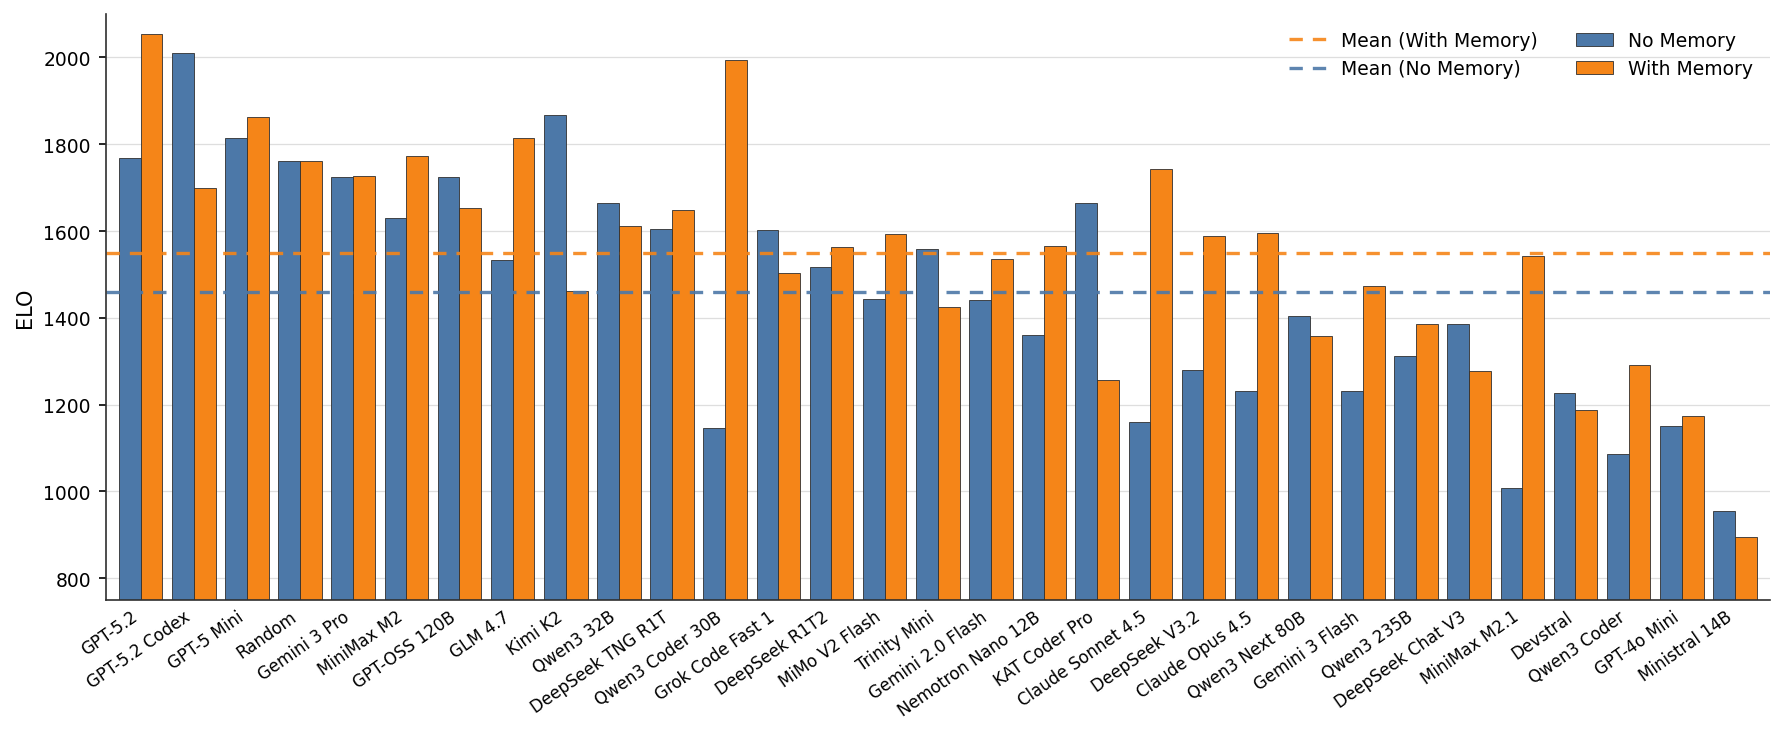

In [ ]:
fig

## calculate ELOs for TOP1 without removing bad bot elo
This should be in leadeboard section not mem vs no mem section

In [ ]:
gs = [
    ['tic_tac_toe_3d', 'world1', None, '3D TTT'],
    ['tic_tac_toe', 'world1', None, '3x3 TTT'],
    ['tic_tac_toe', 'world2', None, '4x4 TTT'],
    ['blackjack', 'world1', None, 'Blackjack'],
    ['battleships', 'world1', None, 'Battleships'],
    ['connect4', 'world1', None, 'Connect4'],
    ['lines_of_action', 'world1', None, 'LoA'],
    ['mancala', 'world1', None, 'Mancala'],
    ['clobber', 'world1', None, 'Clobber'],
    ['pentago', 'world1', None, 'Pentago'],
    ['amazons', 'world1', None, 'Amazons'],
    # ['backgammon', 'world1', None, 'Backgammon'],
    ['nim', 'world1', None, 'Nim'],
    ['dots_and_boxes', 'world1', None, 'Dots&B'],
    ['chess', 'world1', None, 'Chess'],
    ['breakthrough', 'world1', None, 'Breakthrough'],
    ['hex', 'world1', None, 'Hex'],
    ['havannah', 'world1', None, 'Havannah'],
    # ['go', 'world1', 'matches_go_world1_1891_5.json', 'Go'],
    ['go', 'world1', None, 'Go'],
    ['checkers', 'world1', None, 'Checkers'],
]

elos = []
raw_match_data = {}
top_bots = {}
total_num_games = 0
for game_str, world, match_json, colname in gs:
    if match_json is None:
        match_json = get_matches_filename(game_str, world)
    all_data_pruned = get_match_results(game_str, world, match_json)
    num_games = len(all_data_pruned)
    print(f'{game_str} {world} {len(all_data_pruned)}')
    total_num_games += num_games

    elo_pre, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='top_1', verbose=False)
    elo_pre.index = elo_pre.index.str.replace(r"/\d+$", "", regex=True)  # remove bot number
    raw_match_data[colname] = all_data_pruned
    top_bots[colname] = top_models
    elos.append(elo_pre)
print('total games =', total_num_games)
for asdf in range(len(elos)):
    elos[asdf] = elos[asdf].astype(float)



tic_tac_toe_3d world1 22052
tic_tac_toe world1 26732
tic_tac_toe world2 20022
blackjack world1 22350
battleships world1 20880
connect4 world1 18632
lines_of_action world1 2550
mancala world1 18632
clobber world1 6320
pentago world1 5550
amazons world1 27010
nim world1 39160
dots_and_boxes world1 13260
chess world1 30810
breakthrough world1 29260
hex world1 23460
havannah world1 23460
go world1 15960
checkers world1 12750
total games = 378850


In [ ]:
elos_df = pd.concat(elos, axis=1)
elos_df.columns = [n for _,_,_,n in gs]
elos_df['Median ELO'] = elos_df.fillna(-9999).median(axis=1, skipna=False).round(2)
elos_df['Mean ELO'] = elos_df.fillna(0).mean(axis=1).round(2)
elos_df = elos_df.sort_values('Median ELO', ascending=False)
# elos_df = elos_df.sort_values('Mean ELO', ascending=False)
# elos_df = elos_df.sort_values('Lines of Action ELO', ascending=False)
# elos_df = elos_df.sort_values('3D Tic Tac Toe ELO', ascending=False)
elos_with_rwins = elos_df.copy()
for game_str, _, _, colname in gs:
    if colname in elos_with_rwins.columns:
        elos_with_rwins[colname] = elos_with_rwins[colname].astype(str)
        for model in elos_with_rwins.index:
            elo = elos_df.at[model, colname]
            if pd.notnull(elo):
                elo_str = f"{int(round(elo))}"
            else:
                elo_str = 'nan (❌)'
            elos_with_rwins.at[model, colname] = f"{elo_str}"
if "Median ELO" in elos_with_rwins.columns:
    elos_with_rwins["Median ELO"] = elos_df["Median ELO"].round(0)
elos_with_rwins['comments'] = ''
# elos_with_rwins.at['gemini_3_pro_preview', 'comments'] = 'expensive (removed)'
# elos_with_rwins.at['claude_opus_4.5', 'comments'] = 'expensive (removed)'
# elos_with_rwins.at['claude_sonnet_4.5', 'comments'] = 'expensive (removed)'
elos_with_rwins.at['deepseek_v3.2_speciale', 'comments'] = 'expensive (removed)'
elos_with_rwins.at['claude_sonnet_4', 'comments'] = 'expensive (removed)'
elos_with_rwins.at['gemini_2.5_flash', 'comments'] = 'expensive (removed)'
# remove expensive (removed) rows
elos_with_rwins = elos_with_rwins[elos_with_rwins['comments'] != 'expensive (removed)']
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(elos_with_rwins)

,3D TTT,3x3 TTT,4x4 TTT,Blackjack,Battleships,Connect4,LoA,Mancala,Clobber,Pentago,Amazons,Nim,Dots&B,Chess,Breakthrough,Hex,Havannah,Go,Checkers,Median ELO,Mean ELO,comments
gemini_3_pro_preview,1671,1530,1538,1571,1663,2028,1896,2029,2198,1681,2675,2334,1877,1855,2386,2622,1818,1996,1551,1877.0,1939.89,
gpt_5.2,1692,1529,1553,1602,1761,2319,2021,2003,2016,1636,2144,2337,1982,1693,1813,2007,1441,2029,1702,1813.0,1854.54,
gpt_5.2_codex,1675,1531,1550,1533,1794,1875,2172,1901,1873,1671,1854,2365,1706,1586,1955,1972,1750,2089,1707,1794.0,1817.75,
claude_opus_4.5,1655,1529,1556,1557,1781,2008,1999,1941,1779,1627,1561,2333,1865,1635,1999,1848,1757,1566,1517,1757.0,1763.48,
gpt_5.2_pro,1418,1529,1549,1446,1865,2260,1747,1863,2208,1670,2629,2285,2229,1756,1052,1942,1083,1784,1671,1756.0,1787.11,
kimi_k2_thinking,1646,1529,1539,1562,1707,1966,1790,1739,1606,1630,2221,2328,1764,1491,1496,2044,1847,1857,1479,1707.0,1747.43,
gemini_3_flash_preview,1658,1532,1552,1601,1690,1982,1907,2112,1550,1490,1915,2347,1681,1565,2127,2040,1900,920,1587,1681.0,1741.86,
glm_4.7,1685,1529,1538,1557,1582,2002,1555,1947,nan (❌),1680,1958,2364,1836,1538,1876,1963,1256,1680,1805,1680.0,1651.49,
deepseek_v3.2,1677,1530,1566,1605,1796,1787,1632,1965,1931,1506,1945,2356,1695,1617,1705,1077,1727,1385,1322,1677.0,1675.07,
claude_sonnet_4.5,1657,1538,1534,1570,1724,1924,1967,1813,1654,1614,2103,1556,nan (❌),1574,2060,1663,1647,1261,1568,1647.0,1603.69,


In [ ]:
colname = 'Checkers'
all_scores_df = run_leaderboard.get_scores_from_match_data(raw_match_data[colname])
all_scores_df = all_scores_df[all_scores_df.index.isin(top_bots[colname])]
all_scores_df.index = all_scores_df.index.str.replace(r"/\d+$", "", regex=True)  # remove bot number
df = pd.concat([all_scores_df, elos_df[colname].rename('ELO')], axis=1).round().astype("Int64")
print('Checkers')
df.sort_values('ELO', ascending=False)

Checkers


,win,loss,draw,error,timeout,enemy_error,enemy_timeout,ELO
deepseek_r1t2_chimera_free,218,31,70,5,0,138,38,1896
tng_r1t_chimera_free,183,58,104,4,0,119,32,1848
deepseek_chat_v3_0324,125,87,65,5,0,188,30,1840
glm_4.7,170,68,59,0,0,174,29,1805
qwen3_235b_a22b_2507,150,114,81,0,0,115,40,1712
gemini_2.0_flash_001,129,95,96,3,0,146,31,1708
gpt_5.2_codex,97,180,69,0,0,121,33,1707
gpt_5.2,184,38,10,0,93,159,16,1702
qwen3_32b,94,20,31,233,1,104,17,1696
gpt_5.2_pro,185,33,15,0,83,151,33,1671


# live play ELO (OLD)

In [ ]:
def patch_llm_name(m, prefix: str):
    if m['name0'].startswith('LLM_'):
        m['name0'] = 'LLM_' + prefix + m['name0'][4:]
    elif m['name1'].startswith('LLM_'):
        m['name1'] = 'LLM_' + prefix + m['name1'][4:]
    else:
        raise ValueError(f"Invalid name: {m['name0']} or {m['name1']}")
    return m

d = Path('./results_live')
results = {}
for model_name in d.iterdir():
    if not model_name.is_dir() or model_name.name == 'trash':
        continue
    counts = {f.name: len(list(f.glob('**/*.json'))) for f in model_name.iterdir()}
    print(model_name, counts)
    for f in model_name.glob('**/*.json'):
        try:
            with open(f, 'r') as fd:
                data = json.load(fd)
        except Exception as e:
            print(f'Error loading {f}: {e}')
            continue
        game_world = f.parent.name
        game, world = game_world.rsplit('_', 1)
        if (game, world) not in results:
            results[(game, world)] = {}
        if model_name.name not in results[(game, world)]:
            results[(game, world)][model_name.name] = []
        data['r'] = {'player_err_counts': data['player_err_counts']}
        show_legal_moves = data.get('live_play', {}).get('show_legal_moves', False)
        if show_legal_moves:
            patch_llm_name(data, 'PEEK_')
        if not data['done']:
            continue
        results[(game, world)][model_name.name].append(data)

match_results = {}
match_results_vs_bot = {}
for game, world in results:
    for model_name, data in results[(game, world)].items():
        if (game, world) not in match_results:
            match_results[(game, world)] = {}
            match_results_vs_bot[(game, world)] = {}
        match_results[(game, world)][model_name] = {
            'winner_LLM': 0,
            'winner_Automata': 0,
            'draw': 0,
            'err_LLM': 0,
            'err_Automata': 0,
        }
        match_results_vs_bot[(game, world)][model_name] = {}
        for m in data:
            res = run_leaderboard.get_match_result(m, False)
            if res[0] == 'win':
                winner = 'LLM' if m[f'name{res[1]}'].startswith('LLM') else 'Automata'
                match_results[(game, world)][model_name]['winner_' + winner] += 1
                bot_name = m[f'name0'] if m[f'name1'].startswith('LLM') else m[f'name1']
                if bot_name not in match_results_vs_bot[(game, world)][model_name]:
                    match_results_vs_bot[(game, world)][model_name][bot_name] = {'win': 0, 'lose': 0}
                match_results_vs_bot[(game, world)][model_name][bot_name]['win' if winner == 'LLM' else 'lose'] += 1
            elif res[0] == 'draw':
                match_results[(game, world)][model_name]['draw'] += 1
            elif 1 in m['player_err_counts']:
                err_idx = m['player_err_counts'].index(1)
                err = 'LLM' if m[f'name{err_idx}'].startswith('LLM') else 'Automata'
                match_results[(game, world)][model_name]['err_' + err] += 1
                # if err == 'LLM':
                #     print(m['exception'])
            else:
                raise ValueError(f"Invalid match result: {m}")
for g, data in match_results.items():
    print('Game:', g[0])
    for model_name, data in data.items():
        print('   LLM:', model_name, 'Results =', data)
print('--------------------------------')
print('Breakdown by opponent:')
for g, data in match_results_vs_bot.items():
    print(g[0])
    for llm_name, data in data.items():
        print('   LLM:', llm_name, end='')
        for bot_name, data in data.items():
            print(' ', bot_name, data, end='')
        print('|END OF RESULTS|')


results_live/qwen3_coder {'connect4_world1': 10, 'chess_worlduci1': 25}
results_live/kat_coder_pro {'connect4_world1': 10, 'chess_worlduci1': 25}
results_live/grok_code_fast_1 {'chess_worlduci1': 22}
results_live/minimax_m2 {'connect4_world1': 10, 'chess_worlduci1': 16}
results_live/trinity_mini_free {'connect4_world1': 104}
results_live/deepseek_v3.2 {'connect4_world1': 10, 'chess_worlduci1': 25}
results_live/gemini_2.0_flash_001 {'connect4_world1': 10, 'chess_worlduci1': 25}
results_live/tng_r1t_chimera_free {'connect4_world1': 92}
results_live/devstral_2512_free {'dots_and_boxes_world1': 34, 'clobber_world1': 22, 'hex_world1': 34, 'chess_world1': 43, 'breakthrough_world1': 17, 'connect4_world1': 22}
results_live/gemini_3_flash_preview {'dots_and_boxes_world1': 60, 'clobber_world1': 52, 'hex_world1': 86, 'breakthrough_world1': 59, 'connect4_world1': 150, 'chess_worlduci1': 34}
results_live/deepseek_chat_v3_0324 {'connect4_world1': 10, 'chess_worlduci1': 25}
results_live/qwen3_235b_a2

In [ ]:
gs = [
    # ['hex', 'world1', None, 'Hex'],
    # ['dots_and_boxes', 'world1', None, 'Dots and Boxes'],
    # ['clobber', 'world1', None, 'Clobber'],
    ['connect4', 'world1', None, 'Connect4'],
    # ['breakthrough', 'world1', None, 'Breakthrough'],
    # ['chess', 'world1', None, 'Chess'],
    # ['chess', 'worlduci1', None, 'Chess UCI'],
]

live_play_elos = []
automata_data = []
live_play_data = []
for game_str, world, match_json, colname in gs:
    if match_json is None:
        match_json = get_match_file_path(game_str, world)
    all_data_pruned = get_match_results(match_json)
    automata_data.extend(all_data_pruned)
    assert isinstance(all_data_pruned, list)
    elo_pre, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='top_1', verbose=False)
    if (game_str, world) in results:
        for model_name, data in results[(game_str, world)].items():
            all_data_pruned.extend(data)
    top_models_names = set(top_models)
    all_data_pruned = [g for g in all_data_pruned if g['name0'] in top_models_names and g['name1'] in top_models_names and ('OLD_' not in g['name0'] and 'OLD_' not in g['name1'])]
    if (game_str, world) in results:
        for model_name, data in results[(game_str, world)].items():
            data = copy.deepcopy(data)
            all_data_pruned.extend(data)
            live_play_data.extend(data)
    for g in all_data_pruned:
        g['name0'] = g['name0'].split('/')[0]
        g['name1'] = g['name1'].split('/')[0]
    elo_post, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='none', verbose=False, learning_rate=2)
    live_play_elos.append(elo_post)

for asdf in range(len(live_play_elos)):
    live_play_elos[asdf] = live_play_elos[asdf].astype(float)


In [ ]:
# live_play_data[0]
g = []
for m in live_play_data:
    if m['name0'].split('LLM_')[-1].split('PEEK_')[-1] == m['name1'].split('LLM_')[-1].split('PEEK_')[-1]:
        g.append(m)


In [ ]:
counts = defaultdict(int)
for m in g:
    counts[m['name0']] += 1
    counts[m['name1']] += 1

for k, v in counts.items():
    if v > 1:
        print(k, v)


LLM_PEEK_kat_coder_pro 2
kat_coder_pro 2
LLM_PEEK_minimax_m2 2
minimax_m2 2
tng_r1t_chimera_free 4
LLM_PEEK_tng_r1t_chimera_free 4
LLM_PEEK_gemini_3_flash_preview 2
gemini_3_flash_preview 4
LLM_gemini_3_flash_preview 2
LLM_PEEK_minimax_m2.1 2
minimax_m2.1 2
LLM_PEEK_kimi_k2_thinking 2
kimi_k2_thinking 2
LLM_PEEK_ministral_14b_2512 4
ministral_14b_2512 4
LLM_PEEK_gpt_4o_mini 2
gpt_4o_mini 2


In [ ]:
live_play_elos_df = pd.concat(live_play_elos, axis=1)
live_play_elos_df.columns = [n for _,_,_,n in gs]
live_play_elos_df['Median ELO'] = live_play_elos_df.fillna(-9999).median(axis=1, skipna=False).round(2)
live_play_elos_df['Mean ELO'] = live_play_elos_df.fillna(0).mean(axis=1).round(2)
live_play_elos_df = live_play_elos_df.sort_values('Median ELO', ascending=False)
elos_live_rwins = live_play_elos_df.copy()
for game_str, _, _, colname in gs:
    if colname in elos_live_rwins.columns:
        elos_live_rwins[colname] = elos_live_rwins[colname].astype(str)
        for model in elos_live_rwins.index:
            elo = live_play_elos_df.at[model, colname]
            if pd.notnull(elo):
                elo_str = f"{int(round(elo))}"
            else:
                elo_str = 'nan'
            elos_live_rwins.at[model, colname] = f"{elo_str}"
if "Median ELO" in elos_live_rwins.columns:
    elos_live_rwins["Median ELO"] = live_play_elos_df["Median ELO"].round(0)
elos_live_rwins['comments'] = ''
elos_live_rwins.at['claude_sonnet_4', 'comments'] = 'expensive (removed)'
elos_live_rwins.at['gemini_2.5_flash', 'comments'] = 'expensive (removed)'
# remove expensive (removed) rows
elos_live_rwins = elos_live_rwins[elos_live_rwins['comments'] != 'expensive (removed)']
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(elos_live_rwins)

,Connect4,Median ELO,Mean ELO,comments
glm_4.7,2052,2052.0,2052.12,
gpt_5.2,2050,2050.0,2049.53,
gemini_2.0_flash_001,1973,1973.0,1973.47,
claude_opus_4.6,1940,1940.0,1940.15,
kimi_k2_thinking,1920,1920.0,1919.56,
kimi_k2.5,1900,1900.0,1899.87,
devstral_2512,1878,1878.0,1877.61,
glm_5,1871,1871.0,1870.99,
mimo_v2_flash,1812,1812.0,1811.76,
gemini_3_flash_preview,1806,1806.0,1805.84,


In [ ]:
df = elos_live_rwins.copy()
df = df[df.columns[0]]

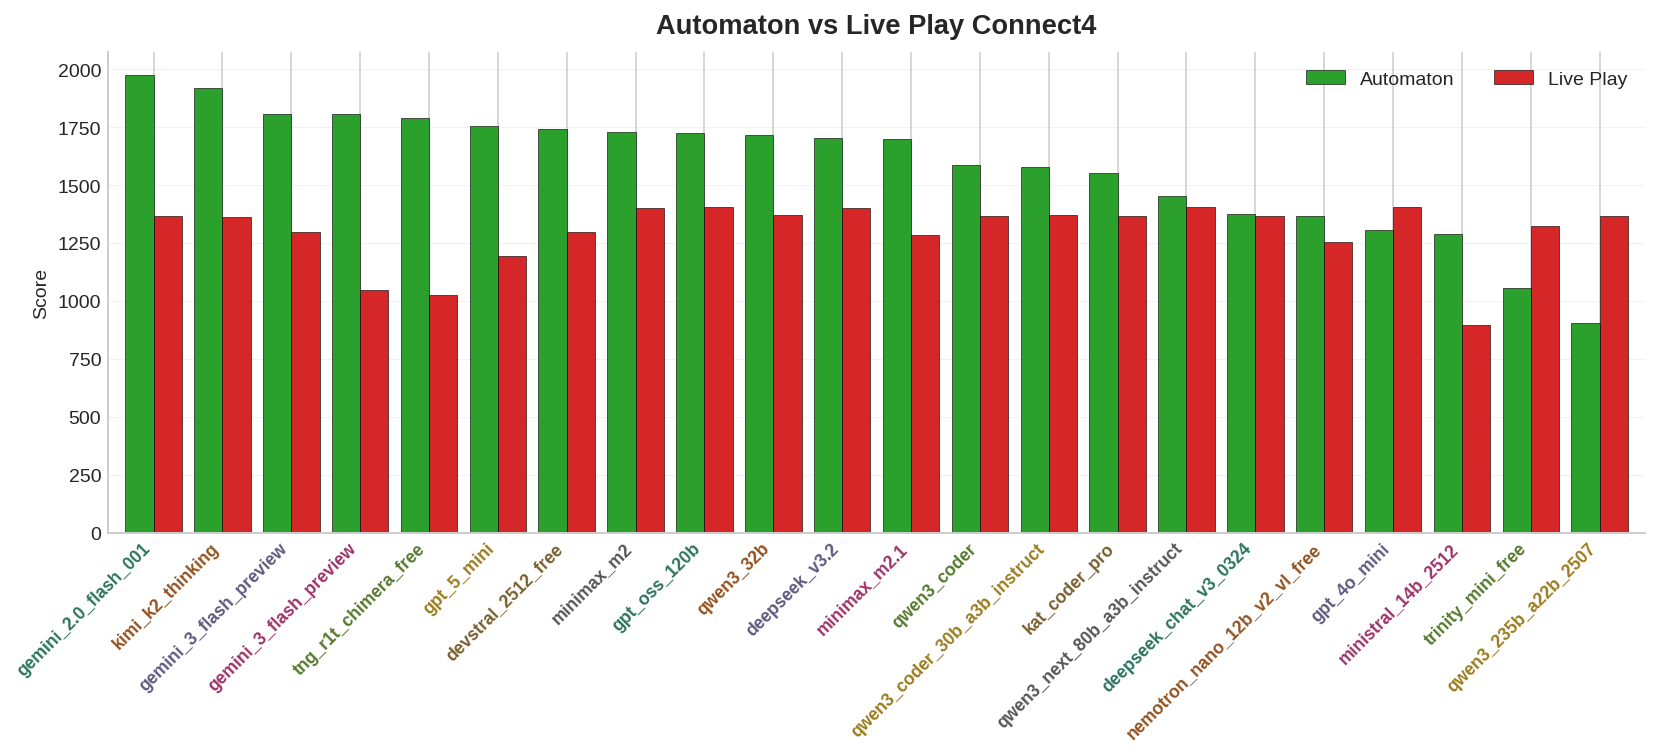

In [ ]:
hide_green = True

base = df.copy()
base.index = base.index.astype(str)

live = base[base.index.str.startswith("LLM_")].copy()
live.index = live.index.str.removeprefix("LLM_").str.removeprefix("PEEK_")

auto = pd.to_numeric(base, errors="coerce")
auto.index = auto.index.str.removeprefix("PEEK_")

out = pd.DataFrame({"Automaton": auto}).join(
    pd.DataFrame({"Live Play": pd.to_numeric(live, errors="coerce")}),
    how="left"
)
if hide_green:
    out = out.dropna(subset=["Automaton", 'Live Play']).sort_values(["Live Play","Automaton"], ascending=False)
else:
    out = out.dropna(subset=["Automaton"]).sort_values(["Live Play","Automaton"], ascending=False)
out = out.sort_values("Automaton", ascending=False)

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(max(12, 0.5 * len(out)), 5.5), dpi=140)

ax.grid(axis="y", which="major", linestyle="-", linewidth=0.6, alpha=0.25)
ax.grid(axis="x", visible=False)

bars = out[["Automaton", "Live Play"]].plot(kind="bar", ax=ax, width=0.82, color=["#2CA02C", "#D62728"], edgecolor="black", linewidth=0.3)

ax.set_title(f"Automaton vs Live Play {elos_live_rwins.columns[0]}", fontsize=14, fontweight="bold", pad=10)
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", rotation=45, labelsize=9)

cmap = plt.get_cmap("Dark2")
colors = [cmap(i % cmap.N) for i in range(len(out.index))]
ax.set_xticklabels(out.index.astype(str).tolist(), rotation=45, ha="right")

text_blend = 0.45
grey = np.array([0.25, 0.25, 0.25, 1.0])
for tick, c in zip(ax.get_xticklabels(), colors):
    rgba = np.array(c)
    muted = (1 - text_blend) * rgba + text_blend * grey
    tick.set_color(muted)
    tick.set_fontweight("semibold")

ax.legend(frameon=False, ncol=2, loc="upper right")
plt.tight_layout()
plt.show()


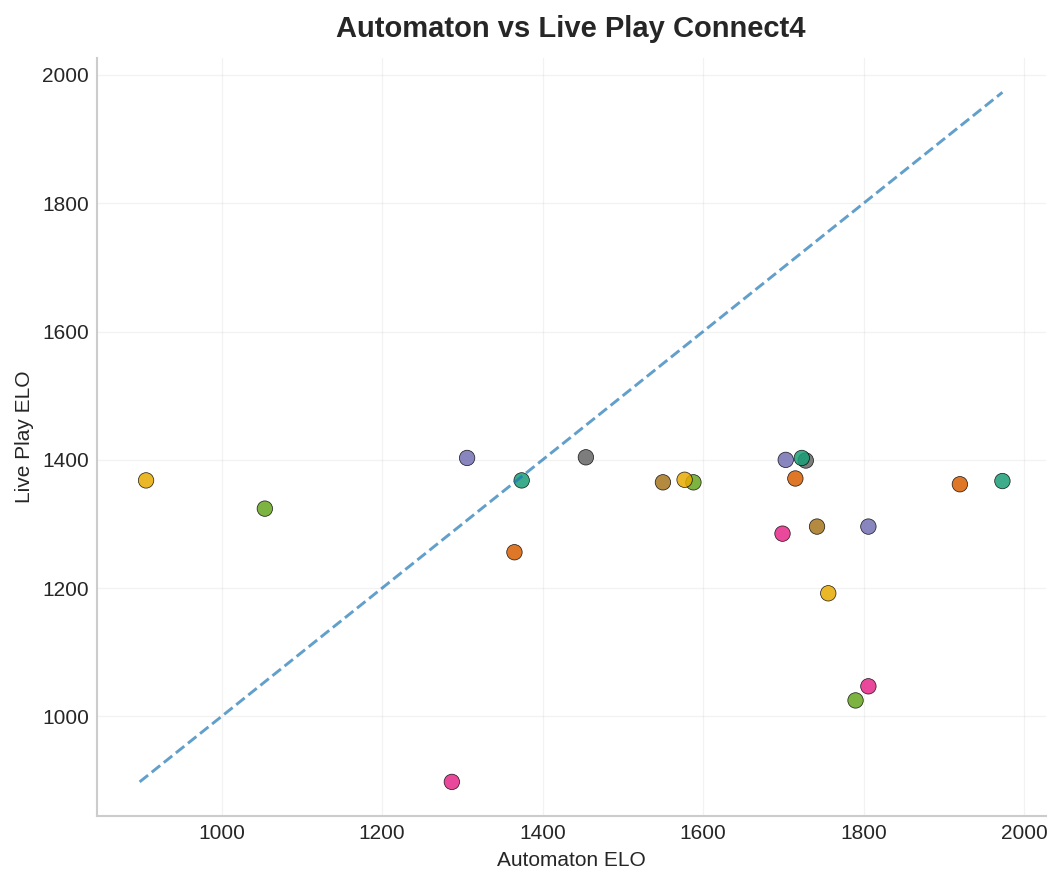

In [ ]:
base = df.copy()
base.index = base.index.astype(str)

live = base[base.index.str.startswith("LLM_")].copy()
live.index = live.index.str.removeprefix("LLM_").str.removeprefix("PEEK_")

auto = pd.to_numeric(base, errors="coerce")
auto.index = auto.index.str.removeprefix("PEEK_")

out = pd.DataFrame({"Automaton": auto}).join(
    pd.DataFrame({"Live Play": pd.to_numeric(live, errors="coerce")}),
    how="left"
).dropna(subset=["Automaton","Live Play"])

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(7.2, 6), dpi=150)

cmap = plt.get_cmap("Dark2")
colors = [cmap(i % cmap.N) for i in range(len(out))]

ax.scatter(out["Automaton"], out["Live Play"], s=55, alpha=0.85, c=colors, edgecolors="black", linewidths=0.35)

mn = min(out["Automaton"].min(), out["Live Play"].min())
mx = max(out["Automaton"].max(), out["Live Play"].max())
ax.plot([mn, mx], [mn, mx], linestyle="--", linewidth=1.4, alpha=0.7)

ax.set_title(f"Automaton vs Live Play {elos_live_rwins.columns[0]}", fontsize=14, fontweight="bold", pad=10)
ax.set_xlabel("Automaton ELO")
ax.set_ylabel("Live Play ELO")
ax.grid(True, linestyle="-", linewidth=0.6, alpha=0.25)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

plt.tight_layout()
out_pdf = f"figures/live_play_{elos_live_rwins.columns[0].replace(' ', '_')}.pdf"
plt.savefig(out_pdf, format="pdf", bbox_inches="tight")
plt.show()


## stability

In [ ]:
# ['hex', 'world1', None, 'Hex'],
# ['dots_and_boxes', 'world1', None, 'Dots and Boxes'],
# ['clobber', 'world1', None, 'Clobber'],
# ['connect4', 'world1', None, 'Connect4'],
# ['breakthrough', 'world1', None, 'Breakthrough'],
# ['chess', 'world1', None, 'Chess'],
# ['chess', 'worlduci1', None, 'Chess UCI'],
game_str, world, match_json, colname = ['connect4', 'world1', None, 'Connect4']


if match_json is None:
    match_json = get_matches_filename(game_str, world)
all_data_pruned = get_match_results(game_str, world, match_json)
assert isinstance(all_data_pruned, list)
elo_pre, top_models = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='top_1', verbose=False)
if (game_str, world) in results:
    for model_name, data in results[(game_str, world)].items():
        all_data_pruned.extend(data)
top_models_names = set(top_models)
all_data_pruned = [g for g in all_data_pruned if g['name0'] in top_models_names and g['name1'] in top_models_names and ('OLD_' not in g['name0'] and 'OLD_' not in g['name1'])]
print(len(all_data_pruned))

llms_data = defaultdict(list)
if (game_str, world) in results:
    for model_name, data in results[(game_str, world)].items():
        data = copy.deepcopy(data)
        for m in data:
            m['name0'] = m['name0'].split('/')[0]
            m['name1'] = m['name1'].split('/')[0]
            if m['name0'].startswith('LLM_'):
                llms_data[m['name0']].append(m)
            if m['name1'].startswith('LLM_'):
                llms_data[m['name1']].append(m)
        
for g in all_data_pruned:
    g['name0'] = g['name0'].split('/')[0]
    g['name1'] = g['name1'].split('/')[0]


print('len(all_data_pruned) = ', len(all_data_pruned))
for k in llms_data:
    print(k, len(llms_data[k]))

1122
len(all_data_pruned) =  1122
LLM_PEEK_devstral_2512_free 22
LLM_PEEK_gemini_3_flash_preview 94
LLM_gemini_3_flash_preview 56
LLM_PEEK_kimi_k2_thinking 26
LLM_PEEK_ministral_14b_2512 42


In [ ]:
import random
from IPython.display import clear_output

def get_elo_with_n_matches(all_data_pruned, n, llms_data):
    data = list(all_data_pruned)  # don't mutate caller's list
    for k, matches in llms_data.items():
        n_k = min(n, len(matches))
        data.extend(random.sample(matches, n_k))
    random.shuffle(data)
    elo_post, _ = run_leaderboard.get_elo_df_combined(data, combine_method="none", verbose=False, iters=40, learning_rate=2)
    elo_post = elo_post["ELO"].to_dict()
    return {k: v for k, v in elo_post.items() if str(k).startswith("LLM")}

data_x, data_y = [], []
for asdf in range(20):
    print(asdf)
    for n in range(1, 100):
        elo_post = get_elo_with_n_matches(all_data_pruned, n, llms_data)
        data_x.append(n)
        data_y.append(elo_post)
    clear_output(wait=True)

clear_output()


In [ ]:
len(all_data_pruned)

1122

In [ ]:
# random.sample(llms_data['LLM_gemini_3_flash_preview'], 2)

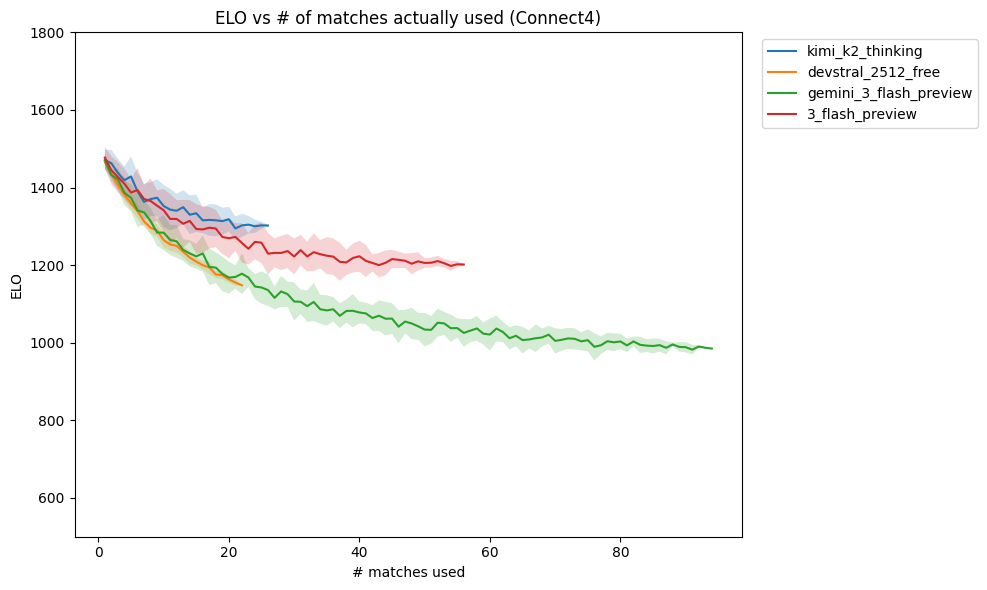

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

vals = defaultdict(lambda: defaultdict(list))  # model -> used_n -> [elo samples]

for idx in range(len(data_x)):
    n = int(data_x[idx])
    d = data_y[idx]
    for model, elo in d.items():
        used_n = min(n, len(llms_data.get(model, [])))  # <-- key fix
        vals[model][used_n].append(elo)

plt.figure(figsize=(10, 6))
for model, by_n in vals.items():
    ns = np.array(sorted(by_n.keys()))
    mu = np.array([np.mean(by_n[k]) for k in ns])
    sd = np.array([np.std(by_n[k], ddof=1) if len(by_n[k]) > 1 else 0.0 for k in ns])

    label = model.split("_", 2)[-1]
    plt.plot(ns, mu, label=label)
    plt.fill_between(ns, mu - sd, mu + sd, alpha=0.2)

plt.title("ELO vs # of matches actually used (Connect4)")
plt.xlabel("# matches used")
plt.ylabel("ELO")
plt.ylim(500, 1800)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### ELO algorithm repitition

In [ ]:
all_data_prunedr = all_data_pruned.copy()
for k in llms_data:
    all_data_prunedr.extend(llms_data[k])
saved = []
for asdf in range(40):
    random.shuffle(all_data_prunedr)
    # elo_post, _ = run_leaderboard.get_elo_df_combined(all_data_pruned, combine_method='none', verbose=False, iters=20)
    elo_post, _ = run_leaderboard.get_elo_df_combined(all_data_prunedr, combine_method='none', verbose=False, iters=40, learning_rate=2)
    saved.append(elo_post)


/tmp/ipykernel_1580163/2027379037.py:10: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


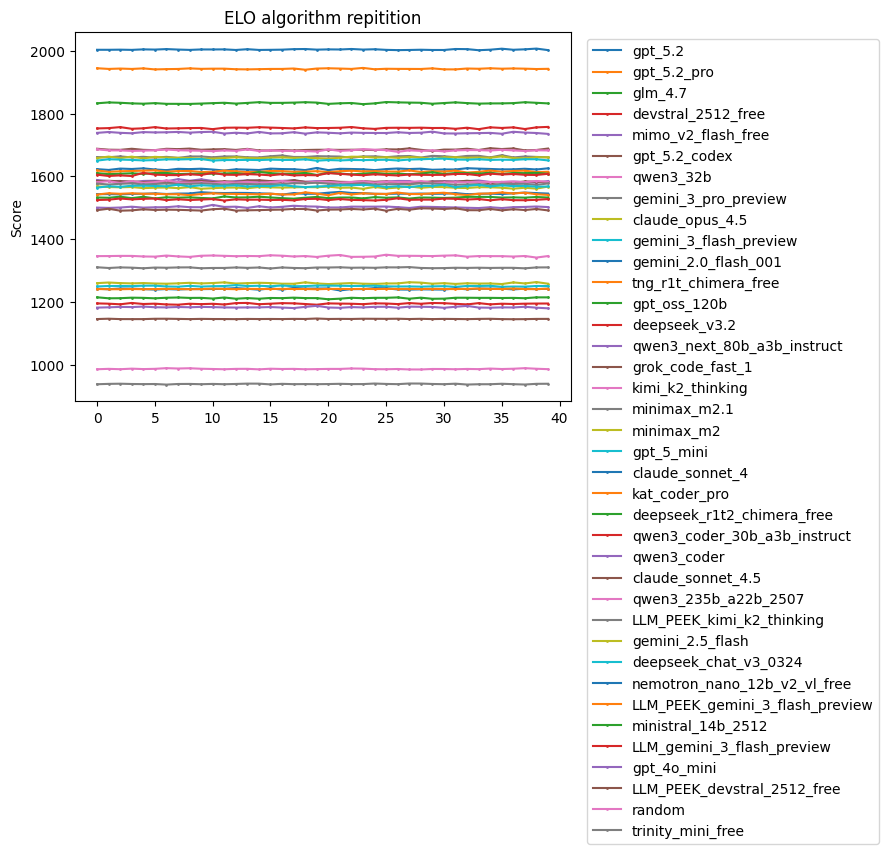

In [ ]:
plt.title('ELO algorithm repitition')
df = pd.concat(saved, axis=1)
df.columns = range(len(df.columns))
x = df.columns.astype(int)  # if columns are strings like "0","1",...
for model, row in df.iterrows():
    plt.plot(x, row.to_numpy(), marker="o", label=model, markersize=1)
plt.xlabel("")
plt.ylabel("Score")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## Cleanup

In [ ]:
import shutil
d = Path('./results_live')
dryrun = True
stats = 0
trash = Path('./results_live/trash')
trash.mkdir(exist_ok=True)
for model_name in d.iterdir():
    if not model_name.is_dir() or model_name.name == 'trash':
        continue
    for f in model_name.glob('**/*.json'):
        with open(f, 'r') as fd:
            data = json.load(fd)
        exception = data.get('exception', None)
        if exception is not None and 'No response from ' in exception:
            # move to d/trash/model_game_
            trash_dir = trash / (model_name.name + ',' + f.parent.name + ',' + f.name)
            print('moving to', trash_dir)
            if not dryrun:
                shutil.move(f, trash_dir)
            stats += 1
print(stats)


0


## AI plot bar

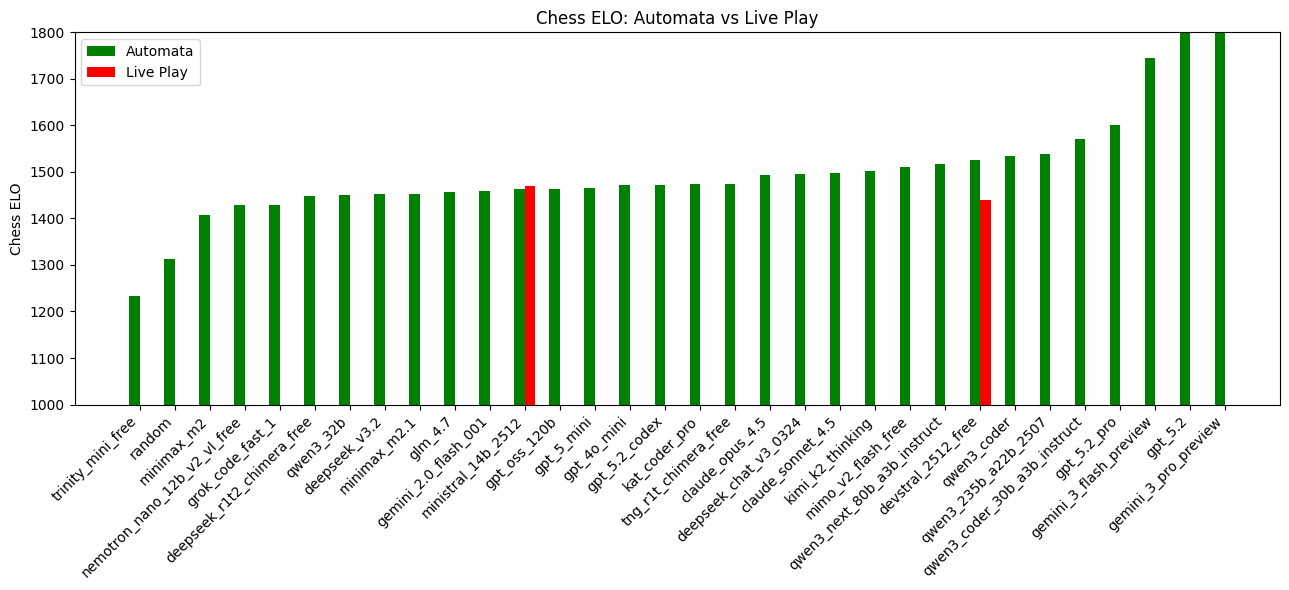

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Split live play vs automata ---
live_play = elos_df[elos_df.index.str.startswith("LLM_PEEK_")].copy()
automata = elos_df[~elos_df.index.str.startswith("LLM_PEEK_")].copy()

# Normalize names for pairing
live_play["base_name"] = live_play.index.str.replace("LLM_PEEK_", "", regex=False)
automata["base_name"] = automata.index

# --- 2. Pair models (left join keeps automata-only rows) ---
paired = pd.merge(
    automata.reset_index(),
    live_play.reset_index(),
    on="base_name",
    how="left",
    suffixes=("_auto", "_live")
)

# --- 3. Prepare plotting data ---
models = paired["base_name"]
elo_auto = paired["Chess_auto"]
elo_live = paired["Chess_live"]  # NaN for models without live play

# Sort by automata ELO for readability
order = np.argsort(elo_auto.values)
models = models.iloc[order]
elo_auto = elo_auto.iloc[order]
elo_live = elo_live.iloc[order]

# --- 4. Plot ---
x = np.arange(len(models))
width = 0.3  # thinner bars

plt.figure(figsize=(13, 6))

# Automata bars (always present)
plt.bar(x - width/2, elo_auto, width, label="Automata", color="green")

# Live play bars (only where available)
mask = ~elo_live.isna()
plt.bar(x[mask] + width/2, elo_live[mask], width, label="Live Play", color="red")

plt.xticks(x, models, rotation=45, ha="right")
plt.ylabel("Chess ELO")
plt.title("Chess ELO: Automata vs Live Play")
plt.ylim(1000, 1800)
plt.legend()
plt.tight_layout()
plt.show()


# test